# Whole-bone GH exposure and cartilage cell state

**An executable companion to the study by Ahmet Haşim Yurttakal and Hasan Erbay.**

Does basal expression of a whole-bone growth hormone (GH) exposure signature concentrate in a particular cartilage state? This notebook reconstructs the source signature, projects it onto embryonic day 15 (E15) and postnatal day 28 (P28) mouse atlases, and tests two anatomical controls derived independently of those atlases.

### Start here

1. Use 64-bit **Python 3.12**. In the extracted distribution run `python -m pip install -r requirements.txt` in your Python environment. Launch `python -m jupyterlab GHIR_Public_Notebook.ipynb`. The README includes Windows and macOS/Linux setup commands.
2. If you downloaded **only this notebook**, install the following in the environment you use to launch Jupyter. All analysis functions, both frozen gene lookups and the GEO download information are embedded.

~~~text
python -m pip install numpy==2.3.5 scipy==1.17.0 pandas==2.2.3 scikit-learn==1.8.0 statsmodels==0.14.6 h5py==3.16.0 matplotlib==3.10.8 Pillow==13.0.0 threadpoolctl==3.6.0 ipykernel==7.4.0 nbformat==5.11.1 nbclient==0.11.0 jupyterlab==4.6.6
~~~

3. Choose **Kernel → Restart Kernel and Run All Cells**. The defaults are `inputs/` and `GHIR_reproduction/`. The first online run downloads about **352 MiB** from NCBI GEO. The complete distribution supplies the same data for offline use. The options in step 1 let you change folders or require offline input.
4. After step 42, open `GHIR_reproduction/tables/table1.csv`, `table2.csv` and `GHIR_reproduction/figure_index.csv`. Each of the 15 figures is saved as PNG, EPS and PDF. Saved cell outputs provide a preview. Running all cells recomputes the results.

| Steps | What you can learn or check |
|---|---|
| 1–12 | Configure the run, inspect the estimators, exercise six numerical tests and verify the data. The long gene-lookup cells are collapsed for easier reading. |
| 13–31 | Reconstruct the juvenile whole-bone signature and historical analyses, including the original cell population, mouse zones, cross-species pairing and null tests. |
| 32–40 | Rebuild cartilage-dominant trajectories, test anatomical controls and investigate gene mapping, sample metadata and contributions from individual genes. |
| 41–42 | Create the publication tables and figures and compare numerical results with the manuscript. |

### How to read the test

For cell $i$, the projection is $R_i=\sum_g w_g\widetilde X_{ig}/\sqrt{\sum_g w_g^2}$, with signed whole-bone weights $w_g$ and within-atlas standardized expression $\widetilde X_{ig}$. Graph distance orders the cells. The primary statistic is the range of the fitted mean score within the central 80% of cells. Matched control genes account for abundance, detection and variation along the graph. A separate directional test asks whether a resting or hypertrophic program increases toward its expected end. Untreated atlases measure basal expression. A treatment-by-stage interaction would require matched GH-treated and control samples.

Seeds, input hashes, spline settings and numbers of null draws are recorded in the code. The two numerical audit files report the computed value, published value, tolerance and result of each comparison.


### 1 · Configure the run

Leave the three options at their defaults for a first run. Set INPUT_DIRECTORY or OUTPUT_DIRECTORY to a local folder to reuse a cache or store results elsewhere. Set OFFLINE to True to require a complete local cache. Environment variables GHIR_INPUTS, GHIR_OUTPUT and GHIR_OFFLINE provide the same choices for scripted runs. This cell checks the Python environment before calling a scientific package.


In [1]:
# Optional settings. None uses the defaults or the corresponding environment variable.
INPUT_DIRECTORY = None
OUTPUT_DIRECTORY = None
OFFLINE = None

import os
import struct
import sys
from importlib import metadata
from pathlib import Path


ANALYSIS_PINS = {
    "numpy": "2.3.5",
    "scipy": "1.17.0",
    "pandas": "2.2.3",
    "scikit-learn": "1.8.0",
    "statsmodels": "0.14.6",
    "h5py": "3.16.0",
    "matplotlib": "3.10.8",
    "Pillow": "13.0.0",
    "threadpoolctl": "3.6.0",
}
NOTEBOOK_PINS = {
    "ipykernel": "7.4.0",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "jupyterlab": "4.6.6",
}


def check_environment():
    """Diagnose missing libraries before downloading any expression data."""
    # The analyses already use two BLAS threads. Give joblib the same default
    # on managed hosts that cannot report a physical core count.
    os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
    if sys.version_info < (3, 11) or struct.calcsize("P") < 8:
        raise RuntimeError("Use 64-bit Python 3.12 for this analysis.")
    if sys.flags.optimize:
        raise RuntimeError("Start Python without -O so the scientific checks run.")
    pins = ANALYSIS_PINS | NOTEBOOK_PINS
    installed = {}
    for name in pins:
        try:
            installed[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            installed[name] = "unavailable"
    missing = [name for name in ANALYSIS_PINS if installed[name] == "unavailable"]
    if missing:
        packages = " ".join(f"{name}=={pins[name]}" for name in ANALYSIS_PINS)
        raise RuntimeError(
            "Missing analysis packages: "
            + ", ".join(missing)
            + "\nIn a terminal for this environment run: python -m pip install -r requirements.txt"
            + "\nWith only the notebook, use a new cell: %pip install "
            + packages
            + "\nRestart the kernel after installation."
        )
    different = [
        f"{n} {installed[n]} (reference {v})" for n, v in ANALYSIS_PINS.items() if installed[n] != v
    ]
    if different or sys.version_info[:2] != (3, 12):
        print(
            "Reference environment: 64-bit Python 3.12. Results will be checked at manuscript precision."
        )
        if different:
            print("Different package versions: " + ", ".join(different))
    return installed


def resolve_paths(base, input_dir=None, output_dir=None):
    """Explicit folder options take precedence over environment variables."""
    cache = (
        Path(input_dir or os.environ.get("GHIR_INPUTS") or base / "inputs").expanduser().resolve()
    )
    output = (
        Path(output_dir or os.environ.get("GHIR_OUTPUT") or base / "GHIR_reproduction")
        .expanduser()
        .resolve()
    )
    return cache, output


def offline_mode(override=None):
    if override is not None:
        return override
    value = os.environ.get("GHIR_OFFLINE", "").strip().lower()
    if value not in ("", "0", "false", "no", "1", "true", "yes"):
        raise ValueError("Set GHIR_OFFLINE to 1 (offline) or 0 (download missing data).")
    return value in ("1", "true", "yes")


def display_path(path):
    """Use short relative paths when the run is inside the current directory."""
    try:
        return str(Path(path).resolve().relative_to(Path.cwd().resolve()))
    except ValueError:
        return str(path)


versions = check_environment()
inputs, root = resolve_paths(Path.cwd(), INPUT_DIRECTORY, OUTPUT_DIRECTORY)
offline = offline_mode(OFFLINE)
out, figdir = root / "tables", root / "figures"
for folder in (out, figdir):
    folder.mkdir(parents=True, exist_ok=True)
print(
    f"Python {sys.version.split()[0]} | GEO cache: {display_path(inputs)} | Results: {display_path(root)}"
)
print("Input mode:", "offline" if offline else "reuse verified files or download missing data")

Python 3.12.14 | GEO cache: inputs | Results: GHIR_reproduction
Input mode: offline


### 2 · Load numerical routines and define print-quality export

Import the sparse-matrix, statistical and graph tools. The thread limiter controls numerical parallelism across platforms. Each manuscript panel is exported to PDF, high-resolution PNG and EPS; the PNG is also displayed inline. EPS uses a raster rendering of the panel to preserve transparent bands and point opacity.



In [2]:
import re, gzip, io, math, warnings, json, hashlib, shutil, time, urllib.request, tempfile
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.io import mmread
from scipy.stats import norm, ttest_1samp, fisher_exact, spearmanr, rankdata
from scipy.interpolate import UnivariateSpline
from scipy.sparse.csgraph import dijkstra, connected_components
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess as sm_lowess
from threadpoolctl import threadpool_limits
from IPython.display import display, Image
from PIL import Image as PILImage

thread_limits = threadpool_limits(limits=2)


def export_panel(figure, name):
    """Keep a native PDF plus two visually equivalent 300-dpi image exports."""
    pdf, png, eps = [figdir / f"{name}.{ext}" for ext in ("pdf", "png", "eps")]
    figure.savefig(pdf, bbox_inches="tight", facecolor="white")
    figure.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
    with PILImage.open(png) as source:
        rgb = np.asarray(source.convert("RGB"))
    height, width = rgb.shape[:2]
    plate = plt.figure(figsize=(width / 300, height / 300), dpi=300)
    plate.figimage(rgb, origin="upper", resize=False)
    plate.savefig(eps, format="eps", dpi=300)
    plt.close(plate)
    if "get_ipython" in globals():
        display(Image(filename=str(png), width=760))
    plt.close(figure)

### 3 · Parse SOFT records and preserve historical identifiers

Read platform and sample tables from GEO family SOFT files, map probes to symbols and collapse duplicate probes. The helper functions below define a common identifier convention for subsequent intersections.



In [3]:
EPS = 1e-8

CANONICAL_GH_IGF = {
    "GHR",
    "JAK2",
    "STAT5A",
    "STAT5B",
    "CISH",
    "SOCS2",
    "IGF1",
    "IGF1R",
    "IRS1",
    "IRS2",
    "AKT1",
    "MTOR",
}

MARKER_MODULES = {
    "resting": ["Apoe", "Pthlh", "Sfrp5", "Fgfr3", "Sox9", "Acan"],
    "proliferative": ["Mki67", "Pcna", "Top2a", "Ccnb1", "Cdk1", "Ccnd1"],
    "prehypertrophic": ["Ihh", "Pth1r", "Serinc5", "Mef2c", "Runx2"],
    "hypertrophic": ["Col10a1", "Mmp13", "Alpl", "Ibsp", "Spp1"],
    "chondrocyte": ["Sox9", "Col2a1", "Acan", "Comp", "Col9a1"],
    "osteoblast": ["Sp7", "Bglap", "Col1a1", "Alpl", "Runx2"],
    "gh_transduction": ["Ghr", "Jak2", "Stat5a", "Stat5b", "Cish", "Socs2"],
    "igf_axis": ["Igf1", "Igf1r", "Irs1", "Irs2", "Akt1", "Mtor"],
}

GSE3689_PUBLISHED_TARGETS = {
    "IGF1": {"6h": 2.60, "24h": 2.29},
    "TBX3": {"6h": 2.00, "24h": 2.50},
    "WNT5A": {"6h": 1.87, "24h": 2.03},
    "BMP2": {"6h": 0.74, "24h": 0.78},
    "BMP7": {"24h": 0.51},
    "STAT5A": {"24h": 0.60},
}

CONSERVATION_COLUMNS = [
    "conservation",
    "mouse_resting",
    "mouse_proliferative",
    "mouse_hypertrophic",
    "human_resting",
    "human_proliferative",
    "human_hypertrophic",
]


def bh_fdr(p: Sequence[float]) -> np.ndarray:
    p = np.asarray(p, float)
    if multipletests is not None:
        return multipletests(np.nan_to_num(p, nan=1.0), method="fdr_bh")[1]
    n = len(p)
    order = np.argsort(np.nan_to_num(p, nan=1.0))
    q = np.empty(n, float)
    ranked = np.nan_to_num(p, nan=1.0)[order] * n / (np.arange(n) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    q[order] = np.minimum(ranked, 1.0)
    return q


def percentile_score(x: pd.Series, higher_better: bool = True) -> pd.Series:
    arr = x.astype(float)
    ok = arr.notna()
    out = pd.Series(np.nan, index=x.index, dtype=float)
    if ok.sum() == 0:
        return out
    ranks = rankdata(arr[ok].to_numpy(), method="average") / ok.sum()
    if not higher_better:
        ranks = 1.0 - ranks + 1.0 / ok.sum()
    out.loc[ok] = ranks
    return out


def _clean_soft_value(v: str) -> str:
    return v.strip().strip('"')


def parse_geo_family_soft(path: os.PathLike | str) -> Dict[str, object]:
    """Parse GEO family SOFT without GEOparse.

    Returns {samples: {GSM: {metadata, table}}, platforms: {GPL: {metadata, table}}}.
    This parser is intentionally limited to fields needed by this project.
    """
    path = Path(path)
    opener = gzip.open if path.suffix == ".gz" else open
    result = {"samples": {}, "platforms": {}}
    entity_type = None
    entity_id = None
    metadata: Dict[str, List[str]] = {}
    table_lines: List[str] = []
    in_table = False

    def flush():
        nonlocal entity_type, entity_id, metadata, table_lines, in_table
        if entity_type and entity_id:
            table = None
            if table_lines:
                try:
                    table = pd.read_csv(
                        io.StringIO("\n".join(table_lines)), sep="\t", dtype=str, low_memory=False
                    )
                except Exception as e:
                    warnings.warn(f"Could not parse table for {entity_id}: {e}")
            target = result["samples"] if entity_type == "SAMPLE" else result["platforms"]
            target[entity_id] = {"metadata": metadata.copy(), "table": table}
        metadata = {}
        table_lines = []
        in_table = False

    with opener(path, "rt", encoding="utf-8", errors="replace") as fh:
        for raw in fh:
            line = raw.rstrip("\n\r")
            if line.startswith("^SAMPLE = "):
                flush()
                entity_type, entity_id = "SAMPLE", line.split("=", 1)[1].strip()
                continue
            if line.startswith("^PLATFORM = "):
                flush()
                entity_type, entity_id = "PLATFORM", line.split("=", 1)[1].strip()
                continue
            if entity_type is None:
                continue
            low = line.lower()
            if low in {"!sample_table_begin", "!platform_table_begin"}:
                in_table = True
                table_lines = []
                continue
            if low in {"!sample_table_end", "!platform_table_end"}:
                in_table = False
                continue
            if in_table:
                if line and not line.startswith("!"):
                    table_lines.append(line)
                continue
            if line.startswith("!") and " = " in line:
                k, v = line[1:].split(" = ", 1)
                metadata.setdefault(k, []).append(_clean_soft_value(v))
    flush()
    return result


def metadata_text(meta: Mapping[str, Sequence[str]]) -> str:
    pieces = []
    for k, v in meta.items():
        if isinstance(v, (list, tuple)):
            pieces.extend(map(str, v))
        else:
            pieces.append(str(v))
    return " ".join(pieces)


def choose_gene_column(platform: pd.DataFrame) -> str:
    candidates = []
    for c in platform.columns:
        lc = str(c).lower()
        score = 0
        if "gene symbol" in lc or "gene_symbol" in lc:
            score += 10
        if lc in {"symbol", "genesymbol", "gene"}:
            score += 8
        if "symbol" in lc:
            score += 5
        if "gene" in lc and "title" not in lc and "description" not in lc:
            score += 2
        candidates.append((score, c))
    candidates.sort(reverse=True, key=lambda z: z[0])
    if not candidates or candidates[0][0] <= 0:
        raise ValueError(
            f"No gene-symbol-like column found. Columns: {platform.columns.tolist()[:30]}"
        )
    return candidates[0][1]


def choose_id_column(platform: pd.DataFrame) -> str:
    for c in platform.columns:
        if str(c).upper() in {"ID", "ID_REF", "SPOT_ID"}:
            return c
    return platform.columns[0]


def clean_gene_symbol(x: object) -> Optional[str]:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    s = str(x).strip()
    if not s or s.lower() in {"nan", "null", "---", "na"}:
        return None
    for sep in [" /// ", "///", ";", "|", ","]:
        if sep in s:
            s = s.split(sep)[0].strip()
    if re.fullmatch(r"[A-Za-z0-9_.-]+", s) is None:
        toks = re.findall(r"[A-Za-z][A-Za-z0-9_.-]+", s)
        if not toks:
            return None
        s = toks[0]
    return s


def platform_probe_to_gene(platform_table: pd.DataFrame) -> pd.Series:
    idc = choose_id_column(platform_table)
    gc = choose_gene_column(platform_table)
    ser = platform_table[[idc, gc]].copy()
    ser[idc] = ser[idc].astype(str)
    ser[gc] = ser[gc].map(clean_gene_symbol)
    ser = ser.dropna(subset=[gc]).drop_duplicates(idc)
    return ser.set_index(idc)[gc]


def extract_value_column(df: pd.DataFrame) -> str:
    candidates = ["VALUE", "signal", "Signal", "VALUE Signal"]
    for c in candidates:
        if c in df.columns:
            return c
    numeric_scores = []
    for c in df.columns:
        if str(c).upper() == "ID_REF":
            continue
        v = pd.to_numeric(df[c], errors="coerce")
        numeric_scores.append((v.notna().mean(), c))
    numeric_scores.sort(reverse=True)
    if not numeric_scores or numeric_scores[0][0] < 0.5:
        raise ValueError("No numeric expression column detected")
    return numeric_scores[0][1]


def collapse_probe_matrix_to_genes(
    probe_matrix: pd.DataFrame, probe_to_gene: pd.Series, agg: str = "median"
) -> pd.DataFrame:
    """Map probe-level expression to a unique, uppercase gene-symbol index.

    Uppercasing is done *before* aggregation. This prevents case variants or
    platform aliases (for example, ``Socs2`` and ``SOCS2``) from creating
    duplicate labels later when mouse and human evidence streams are aligned.
    """
    x = probe_matrix.copy()
    x.index = x.index.astype(str)
    p2g = probe_to_gene.copy()
    p2g.index = p2g.index.astype(str)
    if p2g.index.has_duplicates:
        p2g = p2g[~p2g.index.duplicated(keep="first")]
    common = x.index.intersection(p2g.index)
    x = x.loc[common].copy()
    genes = pd.Series(p2g.reindex(common).values, index=x.index, dtype="object")
    genes = genes.map(clean_gene_symbol).map(lambda z: str(z).upper() if z is not None else np.nan)
    x["__gene__"] = genes.values
    x = x.dropna(subset=["__gene__"])
    x = x[x["__gene__"].astype(str).str.len() > 0]
    if agg == "mean":
        out = x.groupby("__gene__", sort=True).mean(numeric_only=True)
    else:
        out = x.groupby("__gene__", sort=True).median(numeric_only=True)
    out.index = out.index.astype(str)
    return out


def _canonical_gene_series(s: pd.Series, agg: str = "mean") -> pd.Series:
    """Return a gene-indexed Series with unique uppercase labels.

    Duplicate labels can arise after case normalization, multi-probe mapping,
    or alias collapse. They are aggregated rather than passed to ``reindex``,
    because pandas intentionally raises ``ValueError`` for reindexing a source
    axis that contains duplicates.
    """
    if s is None:
        return pd.Series(dtype=float)
    out = s.copy()
    out.index = pd.Index([str(x).strip().upper() for x in out.index])
    out = out[out.index.notna()]
    out = out[out.index.astype(str).str.len() > 0]
    if out.index.has_duplicates:
        if pd.api.types.is_numeric_dtype(out):
            out = out.groupby(level=0).mean() if agg == "mean" else out.groupby(level=0).median()
        else:
            out = out.groupby(level=0).first()
    return out


def _canonical_gene_frame(df: pd.DataFrame, agg: str = "mean") -> pd.DataFrame:
    """Return a gene-indexed DataFrame with unique uppercase labels."""
    if df is None:
        return pd.DataFrame()
    out = df.copy()
    out.index = pd.Index([str(x).strip().upper() for x in out.index])
    out = out[out.index.astype(str).str.len() > 0]
    if out.index.has_duplicates:
        num_cols = list(out.select_dtypes(include=[np.number, "bool"]).columns)
        other_cols = [c for c in out.columns if c not in num_cols]
        pieces = []
        if num_cols:
            num = (
                out[num_cols].groupby(level=0).mean()
                if agg == "mean"
                else out[num_cols].groupby(level=0).median()
            )
            pieces.append(num)
        if other_cols:
            pieces.append(out[other_cols].groupby(level=0).first())
        out = pd.concat(pieces, axis=1) if pieces else pd.DataFrame(index=sorted(set(out.index)))
    return out

### 4 · Reconstruct fixed-dye array contrasts and combine evidence

Repair the historical shifted Agilent fields, subtract local background, normalize within arrays and form signed time-specific and combined statistics. The fixed-size signature is selected by its winsorized weights. The published target observations provide a direction check.

The signed Stouffer statistic is $Z_g=\sum_t z_{gt}/\sqrt{|T_g|}$. Combined evidence can retain a common dye offset. The weighting multiplies $|Z_g|$ by $\sqrt{|\bar\mu_g|+0.05}$ and applies the sign of the mean log ratio. It then winsorizes extreme weights, selects the 300 largest absolute weights and normalizes them.

In [4]:
def infer_gse3689_time(meta: Mapping[str, Sequence[str]], idx: int) -> str:
    """Infer the post-injection time for one GSE3689 two-color array.

    GSE3689 stores GH and PBS on the two channels of the same array.  Time is
    therefore an *array-level* attribute.  We prioritize treatment/title fields
    and only use the original replicate-order convention as a documented
    fallback (replicates 1--3: 6 h; 4--6: 24 h).
    """
    preferred = []
    for key, vals in meta.items():
        lk = str(key).lower()
        if any(
            tok in lk for tok in ["treatment_protocol", "title", "description", "characteristics"]
        ):
            preferred.extend(vals if isinstance(vals, (list, tuple)) else [vals])
    txt = " ".join(map(str, preferred)).lower() or metadata_text(meta).lower()
    if re.search(r"\b6\s*hours?\b|\b6\s*h\b", txt):
        return "6h"
    if re.search(r"\b24\s*hours?\b|\b24\s*h\b", txt):
        return "24h"
    return "6h" if idx < 3 else "24h"


def infer_gse3689_channel_orientation(
    meta: Mapping[str, Sequence[str]],
) -> Tuple[int, str, str, str]:
    """Return sign needed for GH/PBS log-ratio and audit strings.

    The deposited experiment labels GH-treated RNA with Cy5 on channel 1 and
    PBS control RNA with Cy3 on channel 2.  We nevertheless infer the channel
    assignment from the sample metadata whenever possible so that a silent
    channel reversal cannot flip every effect direction.
    """

    def collect(ch: int) -> str:
        pieces = []
        suffix = f"_ch{ch}"
        for key, vals in meta.items():
            lk = str(key).lower()
            if lk.endswith(suffix) and any(
                tok in lk
                for tok in ["source_name", "treatment_protocol", "label", "characteristics"]
            ):
                pieces.extend(vals if isinstance(vals, (list, tuple)) else [vals])
        return " ".join(map(str, pieces)).lower()

    ch1 = collect(1)
    ch2 = collect(2)
    gh1 = bool(re.search(r"growth hormone|\bgh\b", ch1))
    pbs1 = "pbs" in ch1
    gh2 = bool(re.search(r"growth hormone|\bgh\b", ch2))
    pbs2 = "pbs" in ch2
    if gh1 and pbs2:
        return 1, "metadata", "GH", "PBS"
    if gh2 and pbs1:
        return -1, "metadata", "PBS", "GH"
    # Dataset-design fallback is explicit and auditable, never silent.
    return 1, "GSE3689 documented design fallback", "GH", "PBS"


def _gse3689_soft_columns_shifted(df: pd.DataFrame) -> bool:
    """Detect the historical one-column shift in GSE3689 family SOFT tables.

    In the GEO family representation the header can include VALUE even when the
    row-level processed ratio is absent.  The raw channel values are then shifted
    one column to the left.  Treating the apparent CH1MedianSig/CH2MedianSig
    labels literally in that case mixes foreground and background columns and
    produces an invalid GH signature.
    """
    needed = {
        "VALUE",
        "CH1MeanSig",
        "CH2MeanSig",
        "CH1MedianSig",
        "CH2MedianSig",
        "CH1MeanBac",
        "CH2MeanBac",
        "CH1MedianBac",
        "CH2MedianBac",
    }
    if not needed.issubset(df.columns):
        return False
    value = pd.to_numeric(df["VALUE"], errors="coerce")
    pre = (
        pd.to_numeric(df["PRE_VALUE"], errors="coerce")
        if "PRE_VALUE" in df.columns
        else pd.Series(dtype=float)
    )
    finite = value[np.isfinite(value)]
    if finite.empty:
        return False
    # A true log2 ratio is normally O(1), whereas the shifted VALUE column
    # contains foreground fluorescence intensities O(10^2--10^4).
    value_looks_raw = float(np.nanmedian(np.abs(finite))) > 20.0
    pre_missing = (len(pre) == 0) or (float(np.isfinite(pre).mean()) < 0.05)
    return bool(value_looks_raw and pre_missing)


def _repair_gse3689_channel_columns(df: pd.DataFrame) -> Tuple[pd.DataFrame, bool]:
    """Return correctly named raw channel columns for a GSE3689 sample table."""
    raw = df.copy()
    shifted = _gse3689_soft_columns_shifted(raw)
    cols = [
        "CH1MeanSig",
        "CH2MeanSig",
        "CH1MedianSig",
        "CH2MedianSig",
        "CH1MeanBac",
        "CH2MeanBac",
        "CH1MedianBac",
        "CH2MedianBac",
    ]
    if shifted:
        # GEO row values omit VALUE; all raw-channel fields therefore appear
        # under the preceding header.  The mapping below restores the intended
        # Agilent Feature Extraction fields.
        mapping = {
            "CH1MeanSig": "VALUE",
            "CH2MeanSig": "CH1MeanSig",
            "CH1MedianSig": "CH2MeanSig",
            "CH2MedianSig": "CH1MedianSig",
            "CH1MeanBac": "CH2MedianSig",
            "CH2MeanBac": "CH1MeanBac",
            "CH1MedianBac": "CH2MeanBac",
            "CH2MedianBac": "CH1MedianBac",
        }
        fixed = pd.DataFrame(index=raw.index)
        for dest, src in mapping.items():
            fixed[dest] = pd.to_numeric(raw[src], errors="coerce")
    else:
        missing = [c for c in cols if c not in raw.columns]
        if missing:
            raise ValueError(f"GSE3689 raw-channel columns missing: {missing}")
        fixed = raw[cols].apply(pd.to_numeric, errors="coerce")
    fixed.index = raw.index
    return fixed, shifted


def _gse3689_lowess_logratio(
    df: pd.DataFrame,
    meta: Mapping[str, Sequence[str]],
    raw_signal_threshold: float = 100.0,
    lowess_frac: float = 0.30,
) -> Tuple[pd.Series, Dict[str, object]]:
    """Reconstruct one GSE3689 array using the published preprocessing logic.

    Govoni et al. analyzed local-background-subtracted median channel signals,
    applied within-array LOWESS normalization, and retained probes with raw
    signal >=100 and a present flag.  The family SOFT file does not expose the
    original GeneSpring present/absent flag, so this reanalysis reproduces the
    available parts exactly and records that flag filtering is unavailable.
    """
    if sm_lowess is None:
        raise RuntimeError(
            "statsmodels LOWESS is required for GSE3689 preprocessing. Install statsmodels>=0.14."
        )
    fixed, shifted = _repair_gse3689_channel_columns(df)
    ch1_med = fixed["CH1MedianSig"].to_numpy(float)
    ch2_med = fixed["CH2MedianSig"].to_numpy(float)
    ch1_bac = fixed["CH1MedianBac"].to_numpy(float)
    ch2_bac = fixed["CH2MedianBac"].to_numpy(float)
    fg1 = ch1_med - ch1_bac
    fg2 = ch2_med - ch2_bac
    rawmax = np.fmax(ch1_med, ch2_med)
    valid = (
        np.isfinite(fg1)
        & np.isfinite(fg2)
        & np.isfinite(rawmax)
        & (fg1 > 0)
        & (fg2 > 0)
        & (rawmax >= float(raw_signal_threshold))
    )
    M = np.full(len(df), np.nan, float)
    A = np.full(len(df), np.nan, float)
    M[valid] = np.log2(fg1[valid] / fg2[valid])
    A[valid] = 0.5 * (np.log2(fg1[valid]) + np.log2(fg2[valid]))
    if valid.sum() < 100:
        raise ValueError(
            f"Only {int(valid.sum())} GSE3689 probes passed signal/background QC; cannot fit LOWESS reliably."
        )
    fitted = sm_lowess(M[valid], A[valid], frac=float(lowess_frac), it=3, return_sorted=False)
    normM = np.full(len(df), np.nan, float)
    normM[valid] = M[valid] - np.asarray(fitted, float)
    sign, orientation_source, ch1_treat, ch2_treat = infer_gse3689_channel_orientation(meta)
    normM *= float(sign)
    out = pd.Series(normM, index=df["ID_REF"].astype(str), dtype=float)
    qc = {
        "soft_column_shift_repaired": bool(shifted),
        "channel_orientation_source": orientation_source,
        "channel1_treatment": ch1_treat,
        "channel2_treatment": ch2_treat,
        "n_spots_total": int(len(df)),
        "n_spots_signal_pass": int(valid.sum()),
        "signal_pass_fraction": float(valid.mean()),
        "raw_signal_threshold": float(raw_signal_threshold),
        "lowess_fraction": float(lowess_frac),
        "median_raw_M_before_lowess": float(np.nanmedian(M[valid])),
        "median_M_after_lowess": float(np.nanmedian(normM[valid])),
        "present_flag_available": False,
        "preprocessing_method": "background-subtracted median + robust LOWESS",
    }
    return out, qc


def construct_gh_weights(
    gh_stats: pd.DataFrame,
    method: str = "primary",
    top_n: int = 300,
    winsor_quantile: float = 0.995,
) -> pd.DataFrame:
    """Construct normalized acute-GH weights from one common GSE3689 statistic table.

    Candidate selection and single-cell projection must use the *same* primary
    perturbational score.  ``selected_signature`` therefore explicitly records
    the genes entering the top-N primary/alternative signature and is used by
    the candidate-ranking stage rather than ranking every assayed GSE3689 gene.
    """
    x = _canonical_gene_frame(gh_stats.copy())
    required = {"mean_log2fc", "z_combined"}
    missing = required - set(x.columns)
    if missing:
        raise ValueError(
            f"GH statistics missing required columns for weight construction: {sorted(missing)}"
        )
    mu = pd.to_numeric(x["mean_log2fc"], errors="coerce")
    z = pd.to_numeric(x["z_combined"], errors="coerce")
    method = str(method).lower()
    if method == "primary":
        raw = np.sign(mu) * np.abs(z) * np.sqrt(np.abs(mu) + 0.05)
    elif method == "effect_only":
        raw = mu.copy()
    elif method == "evidence_only":
        raw = np.sign(mu) * np.abs(z)
    else:
        raise ValueError("method must be one of: primary, effect_only, evidence_only")
    eligible = pd.Series(True, index=x.index)
    if "analysis_eligible" in x.columns:
        eligible = x["analysis_eligible"].fillna(False).astype(bool)
    raw = raw.where(eligible & np.isfinite(raw), np.nan)
    finite = np.isfinite(raw.to_numpy(float))
    lim = (
        float(np.nanquantile(np.abs(raw.to_numpy(float)[finite]), winsor_quantile))
        if finite.any()
        else 1.0
    )
    if not np.isfinite(lim) or lim <= 0:
        lim = 1.0
    raw_w = raw.clip(-lim, lim)
    x["weight_raw_unwinsorized"] = raw
    x["weight_raw"] = raw_w
    x["rank_abs_weight"] = np.nan
    if raw_w.notna().any():
        x.loc[raw_w.notna(), "rank_abs_weight"] = (
            raw_w.dropna().abs().rank(ascending=False, method="min")
        )
    selected_idx = raw_w.dropna().abs().nlargest(min(int(top_n), int(raw_w.notna().sum()))).index
    x["selected_signature"] = x.index.isin(selected_idx)
    x["weight"] = 0.0
    if len(selected_idx):
        norm_l2 = float(np.sqrt(np.sum(raw_w.loc[selected_idx].to_numpy(float) ** 2))) or 1.0
        x.loc[selected_idx, "weight"] = raw_w.loc[selected_idx] / norm_l2
    x["weight_method"] = method
    return x.sort_values(["selected_signature", "rank_abs_weight"], ascending=[False, True])


def analyze_gse3689(
    geo: Dict[str, object],
    top_n: int = 300,
    raw_signal_threshold: float = 100.0,
    lowess_frac: float = 0.30,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Reanalyze GSE3689 with channel-aware, background-subtracted LOWESS preprocessing.

    This function deliberately does not compute log2(CH1MedianSig/CH2MedianSig)
    from the literal family-SOFT headers because the historical GSE3689 SOFT
    representation can be one column shifted.  Each array is repaired,
    background-subtracted, LOWESS normalized, and oriented as GH/PBS before
    probe-to-gene collapse.
    """
    platforms = geo["platforms"]
    if not platforms:
        raise ValueError("GSE3689 platform table missing")
    platform_id = list(platforms.keys())[0]
    p2g = platform_probe_to_gene(platforms[platform_id]["table"])
    sample_series = []
    sample_meta = []
    for idx, (gsm, obj) in enumerate(geo["samples"].items()):
        df = obj["table"]
        if df is None:
            continue
        if "ID_REF" not in df.columns:
            df = df.rename(columns={df.columns[0]: "ID_REF"})
        series, qc = _gse3689_lowess_logratio(
            df, obj["metadata"], raw_signal_threshold, lowess_frac
        )
        series.name = gsm
        sample_series.append(series)
        qc.update({"sample": gsm, "time": infer_gse3689_time(obj["metadata"], idx)})
        sample_meta.append(qc)
    if not sample_series:
        raise ValueError("No usable GSE3689 sample tables")
    probe = pd.concat(sample_series, axis=1)
    gene = collapse_probe_matrix_to_genes(probe, p2g, agg="median")
    sm = pd.DataFrame(sample_meta).set_index("sample")
    rows = []
    for g, row in gene.iterrows():
        rec = {"gene": g}
        zs = []
        effects = []
        available_z = []
        for t in ["6h", "24h"]:
            cols = sm.index[sm["time"] == t].intersection(gene.columns)
            vals = pd.to_numeric(row[cols], errors="coerce").dropna().to_numpy(float)
            rec[f"n_valid_{t}"] = int(len(vals))
            mu = float(np.mean(vals)) if len(vals) else np.nan
            if len(vals) >= 2 and np.nanstd(vals, ddof=1) > 0:
                _, p = ttest_1samp(vals, 0.0, nan_policy="omit")
                p = float(p)
            else:
                p = 1.0
            z = (
                float(np.sign(mu) * norm.ppf(1 - max(min(p, 1 - 1e-15), 1e-300) / 2))
                if np.isfinite(mu)
                else np.nan
            )
            rec[f"log2fc_{t}"] = mu
            rec[f"p_{t}"] = p
            rec[f"z_{t}"] = z
            if np.isfinite(z):
                available_z.append(z)
            if np.isfinite(mu):
                effects.append(mu)
        rec["n_timepoints_available"] = int(len(available_z))
        rec["z_combined"] = (
            float(np.sum(available_z) / math.sqrt(len(available_z))) if available_z else np.nan
        )
        rec["mean_log2fc"] = float(np.mean(effects)) if effects else np.nan
        # At least one time point must have >=2 valid paired arrays.
        rec["analysis_eligible"] = bool(rec["n_valid_6h"] >= 2 or rec["n_valid_24h"] >= 2)
        rows.append(rec)
    res = pd.DataFrame(rows).set_index("gene")
    for t in ["6h", "24h"]:
        res[f"fdr_{t}"] = bh_fdr(res[f"p_{t}"].fillna(1.0).values)
    res["p_combined"] = 2 * norm.sf(
        np.abs(pd.to_numeric(res["z_combined"], errors="coerce").fillna(0.0))
    )
    res.loc[~res["analysis_eligible"], "p_combined"] = 1.0
    res["fdr_combined"] = bh_fdr(res["p_combined"].values)
    res = construct_gh_weights(res, method="primary", top_n=top_n)
    return res, sm.reset_index()


def gse3689_published_target_qc(gh: pd.DataFrame) -> pd.DataFrame:
    """Compare reanalysis directions with fold changes explicitly reported by Govoni et al."""
    g = _canonical_gene_frame(gh.copy())
    rows = []
    for gene, vals in GSE3689_PUBLISHED_TARGETS.items():
        for time, pub_fold in vals.items():
            col = f"log2fc_{time}"
            est = (
                float(g.loc[gene, col])
                if gene in g.index and col in g.columns and np.isfinite(g.loc[gene, col])
                else np.nan
            )
            pub_log2 = float(np.log2(pub_fold))
            rows.append(
                {
                    "gene": gene,
                    "time": time,
                    "published_fold_change": float(pub_fold),
                    "published_log2fc": pub_log2,
                    "estimated_log2fc": est,
                    "estimated_fold_change": float(2**est) if np.isfinite(est) else np.nan,
                    "direction_match": bool(np.sign(est) == np.sign(pub_log2))
                    if np.isfinite(est)
                    else np.nan,
                }
            )
    return pd.DataFrame(rows)

### 5 · Estimate anatomical zone profiles

Read zone identity from sample-specific titles, scale each array to a common median and average within anatomical zone. The functions return both the three-zone specificity vectors and a weighted zonal burden.



In [5]:
def infer_zone(text: str, human: bool = False) -> Optional[str]:
    """Infer one growth-plate zone from a *sample-specific* text string.

    Important: callers should not pass the concatenation of the entire GEO
    metadata record. GEO extraction protocols commonly describe *all* growth
    plate zones, which can cause every sample to be assigned to the same zone.
    ``infer_zone_from_metadata`` below therefore prioritizes the sample title.
    """
    s = str(text).strip().lower()
    if not s:
        return None
    # Most specific labels must be checked before their parent terms.
    if human:
        if "prehypert" in s or re.search(r"\bphz\d*\b", s):
            return "prehypertrophic"
        if "hypertroph" in s or re.search(r"\bhz\d*\b", s):
            return "hypertrophic"
        if "prolifer" in s or re.search(r"\bpz\d*\b", s):
            return "proliferative"
        if "reserve" in s or "rest" in s or "round" in s or re.search(r"\brz\d*\b", s):
            return "resting"
        if "perichond" in s or re.search(r"\bpc\b", s):
            return "perichondrium"
    else:
        if "prehypert" in s or re.search(r"\bphz\d*\b", s):
            return "prehypertrophic"
        if "hypertroph" in s or re.search(r"\bhz\d*\b", s):
            return "hypertrophic"
        if "matur" in s or re.search(r"\bmz\d*\b", s):
            return "maturing"
        if "prolifer" in s or "flat" in s or re.search(r"\bpz\d*\b", s):
            return "proliferative"
        if "round" in s or "rest" in s or re.search(r"\brz\d*\b", s):
            return "resting"
    return None


def _metadata_values(
    meta: Mapping[str, Sequence[str]], key_fragments: Sequence[str]
) -> List[Tuple[str, str]]:
    """Return metadata values whose key matches one of ``key_fragments``."""
    out = []
    for k, v in meta.items():
        lk = str(k).lower()
        if not any(fragment in lk for fragment in key_fragments):
            continue
        values = v if isinstance(v, (list, tuple)) else [v]
        for item in values:
            out.append((str(k), str(item)))
    return out


def infer_zone_from_metadata(
    meta: Mapping[str, Sequence[str]], human: bool = False
) -> Tuple[Optional[str], str, str]:
    """Infer zone using sample-specific GEO fields in a strict priority order.

    The v1.2 implementation concatenated all sample metadata, including common
    extraction protocols that mention every growth-plate zone. For GSE9160 this
    could label all ten samples as the same zone; for GSE14007 it could similarly
    collapse the four-zone replication to one zone. This function fixes that by
    using title/source/characteristics before any broad fallback.

    Returns ``(zone, source_field, source_text)`` for diagnostics.
    """
    priorities = [
        ("title", ["sample_title", "title"]),
        ("source", ["source_name_ch1", "source name"]),
        ("characteristics", ["characteristics_ch1", "characteristics"]),
        ("description", ["description"]),
    ]
    for label, frags in priorities:
        for key, value in _metadata_values(meta, frags):
            zone = infer_zone(value, human=human)
            if zone is not None:
                return zone, key, value
    # Last-resort fallback excludes protocol/method fields because these often
    # mention all zones and are not sample-identifying.
    excluded = ("protocol", "extract", "hybrid", "scan", "data_processing", "growth")
    for k, v in meta.items():
        lk = str(k).lower()
        if any(tok in lk for tok in excluded):
            continue
        values = v if isinstance(v, (list, tuple)) else [v]
        for item in values:
            zone = infer_zone(str(item), human=human)
            if zone is not None:
                return zone, str(k), str(item)
    return None, "", ""


def process_zonal_geo(
    geo: Dict[str, object], human: bool = False
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    platforms = geo["platforms"]
    if not platforms:
        raise ValueError("Platform table missing")
    platform_id = list(platforms.keys())[0]
    p2g = platform_probe_to_gene(platforms[platform_id]["table"])
    ss = []
    meta = []
    for gsm, obj in geo["samples"].items():
        df = obj["table"]
        if df is None:
            continue
        if "ID_REF" not in df.columns:
            df = df.rename(columns={df.columns[0]: "ID_REF"})
        vc = extract_value_column(df)
        vals = pd.to_numeric(df[vc], errors="coerce")
        s = pd.Series(vals.values, index=df["ID_REF"].astype(str), name=gsm)
        ss.append(s)
        txt = metadata_text(obj["metadata"])
        zone, zone_source, zone_text = infer_zone_from_metadata(obj["metadata"], human=human)
        meta.append(
            {
                "sample": gsm,
                "zone": zone,
                "zone_source": zone_source,
                "zone_text": zone_text[:160],
                "text": txt[:300],
            }
        )
    probe = pd.concat(ss, axis=1)
    # scale each sample to common median to reduce arbitrary between-array scaling.
    med = probe.median(axis=0, skipna=True)
    target = np.nanmedian(med.values)
    probe = probe.multiply(target / (med + EPS), axis=1)
    gene = collapse_probe_matrix_to_genes(probe, p2g, agg="median")
    m = pd.DataFrame(meta).set_index("sample")
    valid = m["zone"].notna()
    m = m.loc[valid]
    gene = gene[m.index.intersection(gene.columns)]
    zone_means = {}
    for z in sorted(m["zone"].unique()):
        cols = m.index[m["zone"] == z].intersection(gene.columns)
        zone_means[z] = gene[cols].mean(axis=1)
    return pd.DataFrame(zone_means), m.reset_index()


def zone_specificity(
    zone_mean: pd.DataFrame, zones: Optional[Sequence[str]] = None
) -> pd.DataFrame:
    x = zone_mean.copy().astype(float).clip(lower=0)
    if zones is not None:
        keep = [z for z in zones if z in x.columns]
        missing = [z for z in zones if z not in x.columns]
        if missing:
            warnings.warn(
                f"Requested growth-plate zones are missing: {missing}; "
                f"available zones={list(x.columns)}. Check sample-zone parsing."
            )
        x = x[keep]
    denom = x.sum(axis=1) + EPS
    return x.div(denom, axis=0)


def zonal_gh_propensity(spec: pd.DataFrame, gh: pd.DataFrame) -> pd.DataFrame:
    w = _canonical_gene_series(gh["weight"].copy())
    w = w.loc[pd.to_numeric(w, errors="coerce").fillna(0).abs() > 0]
    s = _canonical_gene_frame(spec.copy())
    common = s.index.intersection(w.index)
    if len(common) == 0:
        raise ValueError("No selected GH-signature gene overlap for zonal GH propensity")
    wv = w.loc[common]
    den = float(np.abs(wv).sum()) or 1.0
    rows = []
    for z in s.columns:
        pi = s.loc[common, z]
        rows.append(
            {
                "zone": z,
                "signed_propensity": float((wv * pi).sum() / den),
                "unsigned_burden": float((np.abs(wv) * pi).sum() / den),
                "n_genes": len(common),
            }
        )
    return pd.DataFrame(rows).set_index("zone")


def _find_file(directory: Path, patterns: Sequence[str]) -> Path:
    files = list(directory.rglob("*"))
    for p in patterns:
        reg = re.compile(p, re.I)
        for f in files:
            if f.is_file() and reg.search(f.name):
                return f
    raise FileNotFoundError(f"No file matching {patterns} in {directory}")


def _open_text_auto(path: Path):
    return gzip.open(path, "rt") if path.suffix == ".gz" else open(path, "rt")

### 6 · Build cell graphs and standardize gene expression

Read sparse 10x counts, filter cells, score marker panels, choose variable features and build a k-nearest-neighbor graph. Shortest paths from a resting-like root define relative pseudotime. The baseline gene projection uses expression standardized across cells.

The graph coordinate is $\tau_i=d(i,r)/\max_j d(j,r)$. Distances are conditional on the root, retained cells and connectivity. Cell-level differences do not supply animal replication.

In [6]:
def load_10x_mtx(directory: os.PathLike | str) -> Tuple[sparse.csr_matrix, List[str], List[str]]:
    d = Path(directory)
    mtx = _find_file(d, [r"matrix.*\.mtx(\.gz)?$", r"\.mtx(\.gz)?$"])
    feat = _find_file(d, [r"features.*\.tsv(\.gz)?$", r"genes.*\.tsv(\.gz)?$"])
    bar = _find_file(d, [r"barcodes.*\.tsv(\.gz)?$"])
    if mtx.suffix == ".gz":
        with gzip.open(mtx, "rb") as fh:
            mat = mmread(fh).tocsr()
    else:
        mat = mmread(mtx).tocsr()
    # 10x is genes x cells
    with _open_text_auto(feat) as fh:
        feats = [line.rstrip("\n").split("\t") for line in fh if line.strip()]
    genes = [r[1] if len(r) > 1 else r[0] for r in feats]
    with _open_text_auto(bar) as fh:
        barcodes = [line.strip().split("\t")[0] for line in fh if line.strip()]
    if mat.shape[0] == len(genes):
        X = mat.T.tocsr()
    elif mat.shape[1] == len(genes):
        X = mat.tocsr()
    else:
        raise ValueError(f"Matrix dimensions {mat.shape} incompatible with {len(genes)} genes")
    return X, genes, barcodes


def qc_and_normalize_sc(
    X: sparse.csr_matrix,
    genes: Sequence[str],
    barcodes: Sequence[str],
    min_genes: int = 200,
    max_mt_pct: float = 20.0,
    max_cells: Optional[int] = 20000,
    random_state: int = 42,
) -> Tuple[sparse.csr_matrix, List[str], pd.DataFrame]:
    genes = np.asarray(genes, dtype=object)
    total = np.asarray(X.sum(axis=1)).ravel()
    n_genes = np.asarray((X > 0).sum(axis=1)).ravel()
    mt = np.array([str(g).upper().startswith("MT-") for g in genes])
    mt_counts = np.asarray(X[:, mt].sum(axis=1)).ravel() if mt.any() else np.zeros(X.shape[0])
    pct_mt = 100 * mt_counts / (total + EPS)
    max_genes = max(np.quantile(n_genes, 0.995), min_genes + 100)
    keep = (n_genes >= min_genes) & (n_genes <= max_genes) & (pct_mt <= max_mt_pct) & (total > 0)
    idx = np.where(keep)[0]
    if max_cells is not None and len(idx) > max_cells:
        rng = np.random.default_rng(random_state)
        idx = np.sort(rng.choice(idx, size=max_cells, replace=False))
    X = X[idx].tocsr().astype(np.float64)
    meta = pd.DataFrame(
        {
            "barcode": np.asarray(barcodes, dtype=object)[idx],
            "total_counts": total[idx],
            "n_genes": n_genes[idx],
            "pct_mt": pct_mt[idx],
        }
    )
    sf = 1e4 / (np.asarray(X.sum(axis=1)).ravel() + EPS)
    X = X.multiply(sf[:, None]).tocsr()
    X.data = np.log1p(X.data)
    return X, list(genes), meta


def select_hvg_and_pca(
    X: sparse.csr_matrix,
    genes: Sequence[str],
    n_hvg: int = 2500,
    n_pcs: int = 30,
    random_state: int = 42,
):
    mean = np.asarray(X.mean(axis=0)).ravel()
    mean2 = np.asarray(X.power(2).mean(axis=0)).ravel()
    var = np.maximum(mean2 - mean**2, 0)
    dispersion = var / (mean + 0.1)
    expressed = np.asarray((X > 0).sum(axis=0)).ravel() >= 10
    score = np.where(expressed, dispersion, -np.inf)
    n = min(n_hvg, np.isfinite(score).sum())
    hvg_idx = np.argsort(score)[-n:]
    svd = TruncatedSVD(n_components=min(n_pcs, n - 1, X.shape[0] - 1), random_state=random_state)
    pcs = svd.fit_transform(X[:, hvg_idx])
    return pcs, hvg_idx, svd


def gene_lookup(genes: Sequence[str]) -> Dict[str, int]:
    out = {}
    for i, g in enumerate(genes):
        key = str(g).split("_")[0].upper()
        out.setdefault(key, i)
    return out


def module_score(
    X: sparse.csr_matrix, genes: Sequence[str], marker_genes: Sequence[str]
) -> Tuple[np.ndarray, List[str]]:
    lookup = gene_lookup(genes)
    idx = []
    used = []
    for g in marker_genes:
        k = g.upper()
        if k in lookup:
            idx.append(lookup[k])
            used.append(g)
    if not idx:
        return np.zeros(X.shape[0]), []
    arr = np.asarray(X[:, idx].mean(axis=1)).ravel()
    sd = np.std(arr)
    return (arr - np.mean(arr)) / (sd + EPS), used


def annotate_states(
    X: sparse.csr_matrix, genes: Sequence[str]
) -> Tuple[pd.DataFrame, Dict[str, List[str]]]:
    scores = {}
    used = {}
    for name, markers in MARKER_MODULES.items():
        scores[name], used[name] = module_score(X, genes, markers)
    state_names = ["resting", "proliferative", "prehypertrophic", "hypertrophic"]
    state_mat = np.column_stack([scores[s] for s in state_names])
    state = np.asarray(state_names, dtype=object)[np.argmax(state_mat, axis=1)]
    df = pd.DataFrame({f"score_{k}": v for k, v in scores.items()})
    df["cell_state"] = state
    return df, used


def build_knn_graph(pcs: np.ndarray, n_neighbors: int = 15) -> sparse.csr_matrix:
    k = min(n_neighbors + 1, len(pcs))
    nbrs = NearestNeighbors(n_neighbors=k, metric="euclidean").fit(pcs)
    dist, ind = nbrs.kneighbors(pcs)
    rows = []
    cols = []
    dat = []
    for i in range(len(pcs)):
        for j, dv in zip(ind[i, 1:], dist[i, 1:]):
            rows.extend([i, j])
            cols.extend([j, i])
            dat.extend([dv, dv])
    graph = sparse.coo_matrix((dat, (rows, cols)), shape=(len(pcs), len(pcs))).tocsr()
    graph.sum_duplicates()
    return graph


def select_pseudotime_root(
    pcs: np.ndarray, state_scores: pd.DataFrame, strategy: str = "resting_minus_hypertrophic_max"
) -> int:
    """Select a biologically resting-like root using one of three predefined strategies."""
    strategy = str(strategy).lower()
    rest = pd.to_numeric(state_scores["score_resting"], errors="coerce").to_numpy(float)
    hyp = pd.to_numeric(state_scores["score_hypertrophic"], errors="coerce").to_numpy(float)
    if strategy == "resting_minus_hypertrophic_max":
        signal = rest - hyp
        return int(np.nanargmax(signal))
    if strategy == "resting_score_max":
        return int(np.nanargmax(rest))
    if strategy == "resting_centroid_medoid":
        finite = np.isfinite(rest)
        if finite.sum() < 5:
            return int(np.nanargmax(rest - hyp))
        cutoff = float(np.nanquantile(rest[finite], 0.90))
        cand = np.where(finite & (rest >= cutoff))[0]
        if len(cand) < 3:
            cand = np.argsort(np.nan_to_num(rest, nan=-np.inf))[-max(3, min(20, len(rest))) :]
        centroid = np.nanmean(pcs[cand], axis=0)
        dist = np.linalg.norm(pcs[cand] - centroid, axis=1)
        return int(cand[int(np.nanargmin(dist))])
    raise ValueError("Unknown root strategy: " + strategy)


def graph_geodesic_pseudotime(
    pcs: np.ndarray,
    state_scores: pd.DataFrame,
    n_neighbors: int = 15,
    root_strategy: str = "resting_minus_hypertrophic_max",
) -> Tuple[np.ndarray, sparse.csr_matrix, int]:
    graph = build_knn_graph(pcs, n_neighbors=n_neighbors)
    root = select_pseudotime_root(pcs, state_scores, root_strategy)
    dist = dijkstra(graph, directed=False, indices=root)
    finite = np.isfinite(dist)
    if finite.sum() < 0.8 * len(dist):
        # Restrict root selection to the largest connected component rather than silently
        # changing the biological root definition.
        ncomp, labels = connected_components(graph, directed=False)
        sizes = np.bincount(labels)
        lab = int(np.argmax(sizes))
        candidates = np.where(labels == lab)[0]
        local = select_pseudotime_root(
            pcs[candidates], state_scores.iloc[candidates].reset_index(drop=True), root_strategy
        )
        root = int(candidates[local])
        dist = dijkstra(graph, directed=False, indices=root)
        finite = np.isfinite(dist)
    maxd = np.nanmax(dist[finite]) if finite.any() else 1.0
    pt = np.full(len(dist), np.nan)
    pt[finite] = dist[finite] / (maxd + EPS)
    return pt, graph, root


def embedding_2d(pcs, random_state=42):
    """Revision figures use the first two SVD coordinates."""
    return pcs[:, :2], "SVD"


def weighted_gh_score(
    X: sparse.csr_matrix, genes: Sequence[str], gh: pd.DataFrame, max_genes: int = 300
) -> Tuple[np.ndarray, List[str]]:
    lookup = gene_lookup(genes)
    gh2 = _canonical_gene_frame(gh.copy())
    gh2["absw"] = gh2["weight"].abs()
    gh2 = gh2.sort_values("absw", ascending=False)
    idx = []
    weights = []
    used = []
    for g, row in gh2.iterrows():
        if len(idx) >= max_genes:
            break
        k = str(g).upper()
        if k in lookup and abs(float(row["weight"])) > 0:
            idx.append(lookup[k])
            weights.append(float(row["weight"]))
            used.append(str(g))
    if len(idx) < 5:
        raise ValueError(f"Only {len(idx)} GH signature genes found in single-cell matrix")
    A = X[:, idx].toarray().astype(float)
    A = (A - A.mean(axis=0)) / (A.std(axis=0) + EPS)
    w = np.asarray(weights, float)
    score = A @ w / (np.sqrt(np.sum(w * w)) + EPS)
    return score, used


def analyze_single_cell(
    raw_dir: os.PathLike | str,
    gh: pd.DataFrame,
    max_cells: Optional[int] = 20000,
    random_state: int = 42,
) -> Dict[str, object]:
    X, genes, barcodes = load_10x_mtx(raw_dir)
    X, genes, meta = qc_and_normalize_sc(
        X, genes, barcodes, max_cells=max_cells, random_state=random_state
    )
    state_scores, used = annotate_states(X, genes)
    pcs, hvg_idx, svd = select_hvg_and_pca(X, genes, random_state=random_state)
    pt, graph, root = graph_geodesic_pseudotime(pcs, state_scores)
    emb, emb_name = embedding_2d(pcs, random_state=random_state)
    gh_score, gh_used = weighted_gh_score(X, genes, gh)
    meta = pd.concat([meta.reset_index(drop=True), state_scores.reset_index(drop=True)], axis=1)
    meta["pseudotime"] = pt
    meta["gh_response_score"] = gh_score
    meta["embed1"] = emb[:, 0]
    meta["embed2"] = emb[:, 1]
    meta["embedding_type"] = emb_name
    return {
        "X": X,
        "genes": genes,
        "meta": meta,
        "pcs": pcs,
        "root": root,
        "used_markers": used,
        "gh_genes_used": gh_used,
    }

### 7 · Define the spline, interval and empirical nulls

These functions fit the fixed-smoothing binned spline and construct empirical null distributions. H1 randomizes weights or matched genes. H2 independently exchanges zone labels within each gene or draws abundance-matched genes. The same fixed seeds are used as in the manuscript.

For a curve $f$, the connected component around its maximum above $\min f+q(\max f-\min f)$ defines its descriptive interval. Refitting uses a fixed smoothing budget in every observed and null draw.

In [7]:
def smooth_binned_profile(centers, values, grid):
    """Evaluate the cubic smoothing spline for standardized bin means.

    FITPACK selects knots adaptively. Equivalent bin scores from different
    vector math implementations can differ in their last floating-point digits.
    Use a fixed precision for both observed and resampled profiles so that this
    roundoff does not decide between competing knots.
    """
    bin_scores = np.round(np.asarray(values, dtype=np.float64), decimals=9)
    return UnivariateSpline(centers, bin_scores, s=0.02 * len(centers))(grid)


def fit_response_window(
    pseudotime: Sequence[float],
    score: Sequence[float],
    n_bins: int = 30,
    threshold_fraction: float = 0.80,
    n_boot: int = 200,
    random_state: int = 42,
) -> Dict[str, object]:
    x = np.asarray(pseudotime, float)
    y = np.asarray(score, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x = x[ok]
    y = y[ok]
    bins = np.linspace(0, 1, n_bins + 1)
    centers = (bins[:-1] + bins[1:]) / 2
    bidx = np.clip(np.digitize(x, bins) - 1, 0, n_bins - 1)
    means = np.array(
        [np.mean(y[bidx == i]) if np.any(bidx == i) else np.nan for i in range(n_bins)]
    )
    valid = np.isfinite(means)
    if valid.sum() < 5:
        raise ValueError("Too few populated pseudotime bins")
    spline = UnivariateSpline(centers[valid], means[valid], s=max(0.01, valid.sum() * 0.02))
    grid = np.linspace(centers[valid].min(), centers[valid].max(), 300)
    smooth = spline(grid)
    rng = np.random.default_rng(random_state)
    boots = []
    if n_boot > 0:
        for _ in range(n_boot):
            bm = []
            bc = []
            for i in range(n_bins):
                vals = y[bidx == i]
                if len(vals) >= 2:
                    bm.append(np.mean(rng.choice(vals, size=len(vals), replace=True)))
                    bc.append(centers[i])
            if len(bm) >= 5:
                try:
                    sp = UnivariateSpline(
                        np.asarray(bc), np.asarray(bm), s=max(0.01, len(bm) * 0.02)
                    )
                    boots.append(sp(grid))
                except Exception:
                    pass
    if boots:
        B = np.vstack(boots)
        lo = np.percentile(B, 2.5, axis=0)
        hi = np.percentile(B, 97.5, axis=0)
    else:
        lo = np.full_like(grid, np.nan)
        hi = np.full_like(grid, np.nan)
    peak_idx = int(np.argmax(smooth))
    peak = float(grid[peak_idx])
    fmin = float(np.min(smooth))
    fmax = float(np.max(smooth))
    threshold = fmin + threshold_fraction * (fmax - fmin)
    above = smooth >= threshold
    # contiguous component containing peak
    left = peak_idx
    while left > 0 and above[left - 1]:
        left -= 1
    right = peak_idx
    while right < len(grid) - 1 and above[right + 1]:
        right += 1
    return {
        "grid": grid,
        "smooth": smooth,
        "ci_low": lo,
        "ci_high": hi,
        "peak": peak,
        "window_lower": float(grid[left]),
        "window_upper": float(grid[right]),
        "window_width": float(grid[right] - grid[left]),
        "threshold": float(threshold),
        "n_cells": len(x),
        "threshold_fraction": threshold_fraction,
    }


def _sparse_gene_moments(X: sparse.csr_matrix) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Column-wise mean, population SD, and detection prevalence for sparse log-expression."""
    X = X.tocsr()
    mean = np.asarray(X.mean(axis=0)).ravel().astype(float)
    mean2 = np.asarray(X.power(2).mean(axis=0)).ravel().astype(float)
    var = np.maximum(mean2 - mean**2, 0.0)
    sd = np.sqrt(var)
    det = np.asarray((X != 0).mean(axis=0)).ravel().astype(float)
    return mean, sd, det


def _sparse_standardized_weighted_score(
    X: sparse.csr_matrix,
    idx: Sequence[int],
    weights: Sequence[float],
    means: np.ndarray,
    sds: np.ndarray,
) -> np.ndarray:
    """Compute the same standardized weighted score as ``weighted_gh_score`` without densifying columns."""
    idx = np.asarray(idx, dtype=int)
    w = np.asarray(weights, dtype=float)
    if len(idx) != len(w) or len(idx) < 1:
        raise ValueError("idx and weights must have equal non-zero length")
    sd = np.asarray(sds[idx], dtype=float)
    mu = np.asarray(means[idx], dtype=float)
    keep = np.isfinite(sd) & (sd > EPS) & np.isfinite(mu) & np.isfinite(w)
    idx = idx[keep]
    w = w[keep]
    sd = sd[keep]
    mu = mu[keep]
    if len(idx) < 5:
        raise ValueError("Too few non-constant genes for standardized weighted score")
    coef = w / sd
    raw = np.asarray(X[:, idx].dot(coef)).ravel() - float(np.sum(w * mu / sd))
    den = float(np.sqrt(np.sum(w * w))) + EPS
    return raw / den


def _curve_structure_stats(window: Mapping[str, object]) -> Dict[str, float]:
    """Global statistics defined for developmental structure of the smoothed response curve."""
    smooth = np.asarray(window["smooth"], dtype=float)
    return {
        "amplitude": float(np.nanmax(smooth) - np.nanmin(smooth)),
        "curve_variance": float(np.nanvar(smooth)),
        "peak_excess_over_median": float(np.nanmax(smooth) - np.nanmedian(smooth)),
        "peak": float(window["peak"]),
    }


def _empirical_upper_p(null_values: Sequence[float], observed: float) -> float:
    arr = np.asarray(null_values, dtype=float)
    arr = arr[np.isfinite(arr)]
    if not np.isfinite(observed) or len(arr) == 0:
        return np.nan
    return float((1 + np.sum(arr >= float(observed))) / (len(arr) + 1))


def _rank_quantile_bins(values: np.ndarray, n_bins: int) -> np.ndarray:
    """Stable quantile bins even when many genes share the same value."""
    values = np.asarray(values, float)
    n = max(2, int(n_bins))
    ranks = pd.Series(values).rank(method="first", na_option="bottom").to_numpy(float)
    q = np.floor((ranks - 1) / max(len(ranks), 1) * n).astype(int)
    return np.clip(q, 0, n - 1)


def _sample_matched_by_2d_bins(
    rng: np.random.Generator,
    target_idx: np.ndarray,
    eligible_idx: np.ndarray,
    mean_bin: np.ndarray,
    det_bin: np.ndarray,
) -> np.ndarray:
    """Sample a no-replacement gene set matched to target counts across mean-expression/detection bins."""
    from collections import Counter

    target_idx = np.asarray(target_idx, int)
    eligible_idx = np.asarray(eligible_idx, int)
    chosen = []
    used = set()
    keys = {}
    for i in eligible_idx:
        keys.setdefault((int(mean_bin[i]), int(det_bin[i])), []).append(int(i))
    counts = Counter((int(mean_bin[i]), int(det_bin[i])) for i in target_idx)
    # Match larger strata first. Counter keeps first target occurrence for tied counts.
    for key, cnt in counts.most_common():
        cnt = int(cnt)
        pool = [i for i in keys.get(key, []) if i not in used]
        if len(pool) < cnt:
            # Expand deterministically to nearest 2D bins while preserving no replacement.
            candidates = [i for i in eligible_idx if int(i) not in used]
            candidates = sorted(
                candidates,
                key=lambda i: (
                    abs(int(mean_bin[i]) - key[0]) + abs(int(det_bin[i]) - key[1]),
                    rng.random(),
                ),
            )
            pick = candidates[:cnt]
        else:
            pick = rng.choice(np.asarray(pool, int), size=cnt, replace=False).tolist()
        chosen.extend(map(int, pick))
        used.update(map(int, pick))
    if len(chosen) != len(target_idx):
        raise RuntimeError("Matched-gene sampler failed to preserve signature size")
    return np.asarray(chosen, int)


def response_window_null_test(
    X: sparse.csr_matrix,
    genes: Sequence[str],
    meta: pd.DataFrame,
    gh: pd.DataFrame,
    n_permutations: int = 1000,
    n_bins: int = 30,
    threshold_fraction: float = 0.80,
    match_bins: int = 4,
    random_state: int = 42,
) -> Dict[str, object]:
    """Formal H1 null models for maturation-dependent structure of projected GH response potential.

    Two complementary nulls are evaluated through the complete score -> smoothing -> peak pipeline:
    (1) **weight permutation**: the selected GH genes are fixed but their GH-derived weights are permuted;
    (2) **expression/detection-matched random genes**: a same-sized background gene set is sampled with
        matching on mean expression and detection prevalence, and the observed weight distribution is
        randomly reassigned to those genes.

    The primary statistic defined in the finalized analysis is smoothed-curve amplitude, max f(tau)-min f(tau).
    Curve variance and peak excess over the curve median are reported as complementary statistics.
    Importantly, the permutation test establishes non-random developmental *structure*; it does not
    confer a p-value on the biological uniqueness of the observed peak location.
    """
    if "pseudotime" not in meta.columns:
        raise ValueError("meta must contain pseudotime")
    X = X.tocsc()
    genes = list(map(str, genes))
    lookup = gene_lookup(genes)
    g = _canonical_gene_frame(gh.copy())
    if "weight" not in g.columns:
        raise ValueError("GH table must contain normalized weight")
    g = g.loc[pd.to_numeric(g["weight"], errors="coerce").fillna(0).abs() > 0].copy()
    g["absw"] = pd.to_numeric(g["weight"], errors="coerce").abs()
    # A permutation indexes this ordered list. Winsorization creates ties, so use
    # the canonical gene symbol as the secondary key on every CPU and input order.
    g = g.sort_index().sort_values("absw", ascending=False, kind="stable")
    idx = []
    weights = []
    used = []
    for gene, row in g.iterrows():
        key = str(gene).upper()
        if key in lookup and np.isfinite(float(row["weight"])) and abs(float(row["weight"])) > 0:
            idx.append(int(lookup[key]))
            weights.append(float(row["weight"]))
            used.append(str(gene))
    idx = np.asarray(idx, int)
    weights = np.asarray(weights, float)
    means, sds, det = _sparse_gene_moments(X)
    keep = np.isfinite(sds[idx]) & (sds[idx] > EPS)
    idx = idx[keep]
    weights = weights[keep]
    used = [g for g, k in zip(used, keep) if k]
    if len(idx) < 10:
        raise ValueError("Too few selected GH genes are usable for H1 null testing")
    pt = pd.to_numeric(meta["pseudotime"], errors="coerce").to_numpy(float)
    observed_score = _sparse_standardized_weighted_score(X, idx, weights, means, sds)
    observed_window = fit_response_window(
        pt,
        observed_score,
        n_bins=n_bins,
        threshold_fraction=threshold_fraction,
        n_boot=0,
        random_state=random_state,
    )
    obs = _curve_structure_stats(observed_window)

    # Matching bins are calculated over all non-constant expressed genes.
    mean_bin = _rank_quantile_bins(means, match_bins)
    det_bin = _rank_quantile_bins(det, match_bins)
    all_idx = np.arange(X.shape[1], dtype=int)
    selected_set = set(map(int, idx))
    eligible = np.asarray(
        [
            i
            for i in all_idx
            if i not in selected_set and np.isfinite(sds[i]) and sds[i] > EPS and det[i] > 0
        ],
        int,
    )
    if len(eligible) < len(idx):
        raise ValueError("Insufficient background genes for expression/detection-matched H1 null")

    rng = np.random.default_rng(random_state)
    rows = []
    wp_curves = []
    mg_curves = []
    B = max(1, int(n_permutations))
    for b in range(B):
        # Null 1: break the mapping between GH perturbational weights and the selected genes.
        wp = weights[rng.permutation(len(weights))]
        score = _sparse_standardized_weighted_score(X, idx, wp, means, sds)
        win = fit_response_window(
            pt,
            score,
            n_bins=n_bins,
            threshold_fraction=threshold_fraction,
            n_boot=0,
            random_state=random_state + b + 1,
        )
        st = _curve_structure_stats(win)
        st.update({"null_type": "weight_permutation", "iteration": b + 1})
        rows.append(st)
        wp_curves.append(np.asarray(win["smooth"], dtype=np.float32))

        # Null 2: replace the GH genes with expression/detection-matched background genes.
        ridx = _sample_matched_by_2d_bins(rng, idx, eligible, mean_bin, det_bin)
        rw = weights[rng.permutation(len(weights))]
        score2 = _sparse_standardized_weighted_score(X, ridx, rw, means, sds)
        win2 = fit_response_window(
            pt,
            score2,
            n_bins=n_bins,
            threshold_fraction=threshold_fraction,
            n_boot=0,
            random_state=random_state + B + b + 1,
        )
        st2 = _curve_structure_stats(win2)
        st2.update({"null_type": "matched_random_genes", "iteration": b + 1})
        rows.append(st2)
        mg_curves.append(np.asarray(win2["smooth"], dtype=np.float32))

    null = pd.DataFrame(rows)
    summary = {
        "available": 1,
        "n_permutations": B,
        "n_signature_genes_used": int(len(idx)),
        "observed_amplitude": obs["amplitude"],
        "observed_curve_variance": obs["curve_variance"],
        "observed_peak_excess": obs["peak_excess_over_median"],
        "observed_peak": obs["peak"],
        "weight_permutation_p_amplitude": _empirical_upper_p(
            null.loc[null.null_type == "weight_permutation", "amplitude"], obs["amplitude"]
        ),
        "weight_permutation_p_variance": _empirical_upper_p(
            null.loc[null.null_type == "weight_permutation", "curve_variance"],
            obs["curve_variance"],
        ),
        "matched_gene_p_amplitude": _empirical_upper_p(
            null.loc[null.null_type == "matched_random_genes", "amplitude"], obs["amplitude"]
        ),
        "matched_gene_p_variance": _empirical_upper_p(
            null.loc[null.null_type == "matched_random_genes", "curve_variance"],
            obs["curve_variance"],
        ),
    }
    wp_arr = np.vstack(wp_curves)
    mg_arr = np.vstack(mg_curves)
    grid = np.asarray(observed_window["grid"], float)
    envelopes = {
        "grid": grid,
        "weight_perm_lo": np.percentile(wp_arr, 2.5, axis=0),
        "weight_perm_hi": np.percentile(wp_arr, 97.5, axis=0),
        "matched_lo": np.percentile(mg_arr, 2.5, axis=0),
        "matched_hi": np.percentile(mg_arr, 97.5, axis=0),
    }
    return {
        "summary": summary,
        "null_stats": null,
        "observed_window": observed_window,
        "observed_score": observed_score,
        "envelopes": envelopes,
        "signature_genes_used": used,
    }


def _zonal_structure_statistic(q: np.ndarray) -> float:
    q = np.asarray(q, float)
    k = len(q)
    return float(np.sqrt(np.sum((q - 1.0 / k) ** 2)))


def zonal_localization_null_test(
    spec: pd.DataFrame,
    zone_mean: pd.DataFrame,
    gh: pd.DataFrame,
    n_permutations: int = 1000,
    match_bins: int = 6,
    random_state: int = 42,
) -> Dict[str, object]:
    """Formal H2 test of non-random zonal localization using two complementary null models.

    Primary label-permutation null: independently permute the zone labels within each selected
    gene's specificity vector. This preserves each gene's degree of zonal specificity while destroying
    coherent alignment to named zones. Complementary matched-gene null: replace selected GH genes
    with a same-sized set matched on mean zonal expression and transfer the observed absolute-weight
    distribution. The global statistic is Euclidean deviation of the unsigned burden vector from a
    uniform K-zone burden.
    """
    s = _canonical_gene_frame(spec.copy())
    zm = _canonical_gene_frame(zone_mean.copy())
    g = _canonical_gene_frame(gh.copy())
    w = pd.to_numeric(
        g.get("weight", pd.Series(index=g.index, dtype=float)), errors="coerce"
    ).fillna(0.0)
    selected = w.index[w.abs() > 0]
    common = s.index.intersection(selected)
    if len(common) < 10:
        raise ValueError("Too few selected GH genes overlap the zonal dataset for H2 null testing")
    zones = list(s.columns)
    k = len(zones)
    if k < 2:
        raise ValueError("At least two zones are required for H2 null testing")
    mat = s.loc[common, zones].to_numpy(float)
    ww = w.reindex(common).abs().to_numpy(float)
    ww = ww / (ww.sum() + EPS)
    q_obs = ww @ mat
    t_obs = _zonal_structure_statistic(q_obs)

    # Background mean expression is used only for the matched-random-gene null.
    bg = s.index.intersection(zm.index)
    zm_mean = pd.to_numeric(zm.loc[bg].mean(axis=1), errors="coerce")
    finite = zm_mean[np.isfinite(zm_mean)].index
    bg = bg.intersection(finite)
    bg_vals = zm_mean.reindex(bg).to_numpy(float)
    bins = _rank_quantile_bins(bg_vals, match_bins)
    bin_map = {gene: int(b) for gene, b in zip(bg, bins)}
    selected_bins = [bin_map.get(g, None) for g in common]
    # Genes lacking a zone-mean value are assigned the median bin.
    med_bin = int(np.median(bins)) if len(bins) else 0
    selected_bins = [med_bin if b is None else int(b) for b in selected_bins]
    eligible = [g for g in bg if g not in set(common)]
    pools = {
        b: [g for g in eligible if bin_map.get(g, -1) == b] for b in range(max(2, int(match_bins)))
    }

    rng = np.random.default_rng(random_state)
    label_rows = []
    match_rows = []
    label_q = []
    match_q = []
    B = max(1, int(n_permutations))
    for b in range(B):
        # Independently shuffle the named zone identity within every GH-selected gene.
        perm = np.vstack([row[rng.permutation(k)] for row in mat])
        q = ww @ perm
        t = _zonal_structure_statistic(q)
        label_q.append(q)
        label_rows.append(
            {
                "null_type": "within_gene_zone_label_permutation",
                "iteration": b + 1,
                "structure_statistic": t,
                **{f"burden_{z}": float(q[j]) for j, z in enumerate(zones)},
            }
        )

        # Mean-expression-matched random gene set.
        chosen = []
        used = set()
        remaining = {key: list(values) for key, values in pools.items()}
        assert all(
            len(remaining.get(key, [])) >= selected_bins.count(key) for key in set(selected_bins)
        )
        for target_bin in selected_bins:
            pool = remaining.get(target_bin, [])
            if pool:
                pick = pool.pop(int(rng.integers(len(pool))))
            else:
                candidates = [g0 for g0 in eligible if g0 not in used]
                if not candidates:
                    raise RuntimeError("Insufficient matched genes for H2 null")
                pick = min(
                    candidates,
                    key=lambda g0: (abs(bin_map.get(g0, med_bin) - target_bin), rng.random()),
                )
            chosen.append(pick)
            used.add(pick)
        rmat = s.loc[chosen, zones].to_numpy(float)
        rw = ww[rng.permutation(len(ww))]
        q2 = rw @ rmat
        t2 = _zonal_structure_statistic(q2)
        match_q.append(q2)
        match_rows.append(
            {
                "null_type": "mean_expression_matched_random_genes",
                "iteration": b + 1,
                "structure_statistic": t2,
                **{f"burden_{z}": float(q2[j]) for j, z in enumerate(zones)},
            }
        )

    null = pd.DataFrame(label_rows + match_rows)
    label_arr = np.vstack(label_q)
    match_arr = np.vstack(match_q)
    summary = {
        "available": 1,
        "n_permutations": B,
        "n_signature_genes_used": int(len(common)),
        "n_zones": int(k),
        "observed_structure_statistic": t_obs,
        "label_permutation_p": _empirical_upper_p(
            null.loc[null.null_type == "within_gene_zone_label_permutation", "structure_statistic"],
            t_obs,
        ),
        "matched_gene_p": _empirical_upper_p(
            null.loc[
                null.null_type == "mean_expression_matched_random_genes", "structure_statistic"
            ],
            t_obs,
        ),
    }
    observed = pd.DataFrame(
        {
            "zone": zones,
            "observed_burden": q_obs,
            "label_null_median": np.median(label_arr, axis=0),
            "label_null_lo": np.percentile(label_arr, 2.5, axis=0),
            "label_null_hi": np.percentile(label_arr, 97.5, axis=0),
            "matched_null_median": np.median(match_arr, axis=0),
            "matched_null_lo": np.percentile(match_arr, 2.5, axis=0),
            "matched_null_hi": np.percentile(match_arr, 97.5, axis=0),
        }
    )
    return {"summary": summary, "null_stats": null, "zone_summary": observed}

### 8 · Define robustness and cross-species comparisons

Vary score construction, interval thresholds, roots and graph size. Compute cross-species basal similarity after matching mouse and human genes. These definitions are used by H3 and H4.



In [8]:
def response_window_sensitivity(
    X: sparse.csr_matrix,
    genes: Sequence[str],
    meta: pd.DataFrame,
    gh: pd.DataFrame,
    signature_sizes: Sequence[int] = (100, 200, 300),
    threshold_fractions: Sequence[float] = (0.70, 0.80, 0.90),
    n_bins: int = 30,
    random_state: int = 42,
) -> pd.DataFrame:
    """Evaluate whether the inferred GH Response Window is robust to analysis choices.

    This analysis is intentionally self-contained: it uses the already loaded single-cell matrix,
    pseudotime, and independently learned GSE3689 GH weights. It therefore cannot fail because an
    external supplementary file changes URL or becomes temporarily unavailable.

    For each requested number of top GH-signature genes N, the cell-level response-potential score
    is recomputed. For each response-window threshold q, a window is fitted using the same
    predefined definition used in the primary analysis. The returned table contains the actual
    number of GH genes found in the single-cell matrix, peak location, interval boundaries, width,
    and the Spearman correlation of each sensitivity score with the primary N=300 score when it is
    available.
    """
    if "pseudotime" not in meta.columns:
        raise ValueError("meta must contain a 'pseudotime' column")
    pt = pd.to_numeric(meta["pseudotime"], errors="coerce").to_numpy(float)
    # Primary score for concordance when available.
    try:
        primary_score, _ = weighted_gh_score(X, genes, gh, max_genes=300)
    except Exception:
        primary_score = None
    rows = []
    for requested_n in signature_sizes:
        score, used = weighted_gh_score(X, genes, gh, max_genes=int(requested_n))
        if primary_score is not None:
            ok = np.isfinite(score) & np.isfinite(primary_score)
            rho = (
                float(spearmanr(score[ok], primary_score[ok]).correlation)
                if ok.sum() > 2
                else np.nan
            )
        else:
            rho = np.nan
        for q in threshold_fractions:
            w = fit_response_window(
                pt,
                score,
                n_bins=n_bins,
                threshold_fraction=float(q),
                n_boot=0,
                random_state=random_state,
            )
            rows.append(
                {
                    "requested_signature_size": int(requested_n),
                    "genes_used_in_sc": int(len(used)),
                    "threshold_fraction": float(q),
                    "peak": float(w["peak"]),
                    "window_lower": float(w["window_lower"]),
                    "window_upper": float(w["window_upper"]),
                    "window_width": float(w["window_width"]),
                    "score_spearman_vs_primary": rho,
                }
            )
    out = pd.DataFrame(rows)
    return out.sort_values(["threshold_fraction", "requested_signature_size"]).reset_index(
        drop=True
    )


def signature_weighting_sensitivity(
    X: sparse.csr_matrix,
    genes: Sequence[str],
    meta: pd.DataFrame,
    gh: pd.DataFrame,
    top_n: int = 300,
    methods: Sequence[str] = ("primary", "effect_only", "evidence_only"),
    threshold_fraction: float = 0.80,
    n_bins: int = 30,
    random_state: int = 42,
) -> pd.DataFrame:
    """Test two alternative constructions of the acute-GH signature weights."""
    if "pseudotime" not in meta.columns:
        raise ValueError("meta must contain pseudotime")
    pt = pd.to_numeric(meta["pseudotime"], errors="coerce").to_numpy(float)
    scores = {}
    rows = []
    for method in methods:
        gmethod = construct_gh_weights(gh, method=method, top_n=top_n)
        score, used = weighted_gh_score(X, genes, gmethod, max_genes=top_n)
        scores[str(method)] = score
        w = fit_response_window(
            pt,
            score,
            n_bins=n_bins,
            threshold_fraction=threshold_fraction,
            n_boot=0,
            random_state=random_state,
        )
        rows.append(
            {
                "weight_method": str(method),
                "genes_used_in_sc": int(len(used)),
                "peak": float(w["peak"]),
                "window_lower": float(w["window_lower"]),
                "window_upper": float(w["window_upper"]),
                "window_width": float(w["window_width"]),
            }
        )
    primary = scores.get("primary")
    for row in rows:
        score = scores[row["weight_method"]]
        if primary is None:
            rho = np.nan
        else:
            ok = np.isfinite(score) & np.isfinite(primary)
            rho = float(spearmanr(score[ok], primary[ok]).correlation) if ok.sum() > 2 else np.nan
        row["score_spearman_vs_primary"] = rho
    return pd.DataFrame(rows)


def pseudotime_root_knn_robustness(
    pcs: np.ndarray,
    state_scores: pd.DataFrame,
    gh_response_score: Sequence[float],
    primary_pseudotime: Sequence[float],
    k_values: Sequence[int] = (10, 15, 20, 30),
    root_strategies: Sequence[str] = (
        "resting_minus_hypertrophic_max",
        "resting_score_max",
        "resting_centroid_medoid",
    ),
    threshold_fraction: float = 0.80,
    n_bins: int = 30,
    random_state: int = 42,
) -> pd.DataFrame:
    """Quantify sensitivity of the response window to root-cell and kNN-graph choices."""
    primary = np.asarray(primary_pseudotime, float)
    score = np.asarray(gh_response_score, float)
    rows = []
    for root_strategy in root_strategies:
        for k in k_values:
            pt, graph, root = graph_geodesic_pseudotime(
                pcs, state_scores, n_neighbors=int(k), root_strategy=root_strategy
            )
            ok = np.isfinite(pt) & np.isfinite(primary)
            rho = float(spearmanr(pt[ok], primary[ok]).correlation) if ok.sum() > 2 else np.nan
            w = fit_response_window(
                pt,
                score,
                n_bins=n_bins,
                threshold_fraction=threshold_fraction,
                n_boot=0,
                random_state=random_state,
            )
            rows.append(
                {
                    "root_strategy": root_strategy,
                    "k_neighbors": int(k),
                    "root_index": int(root),
                    "finite_fraction": float(np.isfinite(pt).mean()),
                    "pseudotime_spearman_vs_primary": rho,
                    "peak": float(w["peak"]),
                    "window_lower": float(w["window_lower"]),
                    "window_upper": float(w["window_upper"]),
                    "window_width": float(w["window_width"]),
                }
            )
    return pd.DataFrame(rows).sort_values(["root_strategy", "k_neighbors"]).reset_index(drop=True)


def _empty_conservation_table() -> pd.DataFrame:
    """Return a schema-stable empty conservation table.

    A zero-overlap mouse/human comparison is a valid data state, not a reason
    for downstream code to fail with KeyError('conservation').
    """
    df = pd.DataFrame(columns=CONSERVATION_COLUMNS)
    df.index.name = "gene"
    return df


def cross_species_conservation(
    mouse_spec: pd.DataFrame, human_spec: pd.DataFrame
) -> Tuple[pd.DataFrame, Dict[str, float]]:
    """Compare zonal specificity between mouse and human growth plate.

    The function is deliberately *schema-stable*: even when there are no
    usable cross-species gene symbols, it returns an empty DataFrame that
    still contains the expected ``conservation`` column. This prevents the
    notebook from crashing and makes the absence of overlap explicit.
    """
    required = ["resting", "proliferative", "hypertrophic"]
    stats: Dict[str, float] = {
        "n_mouse_genes": int(len(mouse_spec)),
        "n_human_genes": int(len(human_spec)),
        "n_symbol_overlap_before_filter": 0,
        "n_ortholog_symbols": 0,
        "mean_gene_conservation": np.nan,
        "zone_profile_spearman": np.nan,
    }

    if mouse_spec is None or human_spec is None or mouse_spec.empty or human_spec.empty:
        warnings.warn(
            "Mouse-human conservation could not be computed because one zonal "
            "specificity table is empty. The analysis will continue with "
            "conservation marked unavailable."
        )
        return _empty_conservation_table(), stats

    m = mouse_spec.copy()
    h = human_spec.copy()
    m.index = pd.Index([str(x).strip().upper() for x in m.index])
    h.index = pd.Index([str(x).strip().upper() for x in h.index])

    # Upper-casing can create duplicate symbols (e.g. aliases differing only by
    # case). Collapse these deterministically before matching.
    m = m.groupby(level=0).mean(numeric_only=True)
    h = h.groupby(level=0).mean(numeric_only=True)

    missing_mouse = [z for z in required if z not in m.columns]
    missing_human = [z for z in required if z not in h.columns]
    if missing_mouse or missing_human:
        warnings.warn(
            "Mouse-human conservation skipped because required zones are missing. "
            f"mouse missing={missing_mouse}; human missing={missing_human}."
        )
        return _empty_conservation_table(), stats

    common = m.index.intersection(h.index)
    stats["n_symbol_overlap_before_filter"] = int(len(common))
    if len(common) == 0:
        warnings.warn(
            "No shared gene symbols were found between mouse and human zonal "
            "tables after normalization. Check GEO platform gene-symbol mapping. "
            "The pipeline will continue without the conservation component."
        )
        return _empty_conservation_table(), stats

    rows = []
    for g in common:
        vm = pd.to_numeric(m.loc[g, required], errors="coerce").to_numpy(dtype=float)
        vh = pd.to_numeric(h.loc[g, required], errors="coerce").to_numpy(dtype=float)
        if not (np.isfinite(vm).all() and np.isfinite(vh).all()):
            continue
        # Re-normalize defensively in case upstream filtering changed row sums.
        sm, sh = float(vm.sum()), float(vh.sum())
        if sm <= 0 or sh <= 0:
            continue
        vm = vm / sm
        vh = vh / sh
        c = 1.0 - 0.5 * np.sum(np.abs(vm - vh))
        rows.append(
            {
                "gene": g,
                "conservation": float(np.clip(c, 0, 1)),
                "mouse_resting": vm[0],
                "mouse_proliferative": vm[1],
                "mouse_hypertrophic": vm[2],
                "human_resting": vh[0],
                "human_proliferative": vh[1],
                "human_hypertrophic": vh[2],
            }
        )

    if not rows:
        warnings.warn(
            "Shared symbols were present, but none had complete finite zonal "
            "profiles. The pipeline will continue without the conservation component."
        )
        return _empty_conservation_table(), stats

    df = pd.DataFrame(rows).set_index("gene")
    # Keep a deterministic column order.
    df = df.reindex(columns=CONSERVATION_COLUMNS)
    stats["n_ortholog_symbols"] = int(len(df))
    stats["mean_gene_conservation"] = float(df["conservation"].mean())

    # Global zone-profile correspondence across all matched genes. A Spearman
    # coefficient based on only three aggregate zone values is descriptive.
    mv = np.array(
        [
            df["mouse_resting"].mean(),
            df["mouse_proliferative"].mean(),
            df["mouse_hypertrophic"].mean(),
        ]
    )
    hv = np.array(
        [
            df["human_resting"].mean(),
            df["human_proliferative"].mean(),
            df["human_hypertrophic"].mean(),
        ]
    )
    stats["zone_profile_spearman"] = float(spearmanr(mv, hv).statistic)
    return df, stats

### 9 · Define the submitted contribution calculation

Calculate standardized inside/outside expression differences and recompute the full ranking independently under each weight construction. A rank depends on the selected signature and interval.



In [9]:
def window_gene_statistics(
    X: sparse.csr_matrix, genes: Sequence[str], meta: pd.DataFrame, lower: float, upper: float
) -> pd.DataFrame:
    """Gene-level contrast between cells inside and outside the GH Response Window.

    The original implementation used a raw difference of mean log-expression.
    That can favor abundant housekeeping genes.  The revised candidate-ranking
    method therefore uses a standardized mean difference (SMD) together with
    expression prevalence, while retaining raw means for auditability.
    """
    pt = pd.to_numeric(meta["pseudotime"], errors="coerce").to_numpy(float)
    inside = np.isfinite(pt) & (pt >= float(lower)) & (pt <= float(upper))
    outside = np.isfinite(pt) & ~inside
    if inside.sum() < 10 or outside.sum() < 10:
        return pd.DataFrame(
            columns=[
                "mean_inside",
                "mean_outside",
                "window_minus_outside_logexpr",
                "window_smd",
                "detected_fraction_inside",
                "detected_fraction_outside",
                "detected_fraction_max",
                "n_inside",
                "n_outside",
            ]
        )
    Xi = X[inside].tocsr()
    Xo = X[outside].tocsr()
    ni, no = Xi.shape[0], Xo.shape[0]
    mi = np.asarray(Xi.mean(axis=0)).ravel().astype(float)
    mo = np.asarray(Xo.mean(axis=0)).ravel().astype(float)
    m2i = np.asarray(Xi.power(2).mean(axis=0)).ravel().astype(float)
    m2o = np.asarray(Xo.power(2).mean(axis=0)).ravel().astype(float)
    vi = np.maximum(m2i - mi**2, 0.0)
    vo = np.maximum(m2o - mo**2, 0.0)
    pooled = np.sqrt(
        np.maximum(((max(ni - 1, 1) * vi) + (max(no - 1, 1) * vo)) / max(ni + no - 2, 1), 0.0)
    )
    smd = (mi - mo) / (pooled + EPS)
    di = np.asarray((Xi > 0).mean(axis=0)).ravel().astype(float)
    do = np.asarray((Xo > 0).mean(axis=0)).ravel().astype(float)
    idx = pd.Index([str(g).upper() for g in genes], name="gene")
    out = pd.DataFrame(
        {
            "mean_inside": mi,
            "mean_outside": mo,
            "window_minus_outside_logexpr": mi - mo,
            "window_smd": smd,
            "detected_fraction_inside": di,
            "detected_fraction_outside": do,
            "detected_fraction_max": np.maximum(di, do),
            "n_inside": int(ni),
            "n_outside": int(no),
        },
        index=idx,
    )
    if out.index.has_duplicates:
        numeric = out.groupby(level=0).mean(numeric_only=True)
        out = numeric
    return out


def priority_table(
    gh: pd.DataFrame,
    window_evidence,
    conservation: pd.DataFrame,
    height_candidates: Sequence[str],
    min_prevalence: float = 0.05,
) -> pd.DataFrame:
    """Rank GH-growth candidates with a GSE3689-anchored candidate universe.

    Critical consistency rules
    --------------------------
    1. Only genes actually selected into the primary/alternative GH signature
       (``selected_signature`` or non-zero ``weight``) may enter the ranking.
    2. Acute-GH evidence is the absolute *same perturbational weight* used for
       single-cell projection (``weight_raw``), not a separate |Z| statistic.
    3. Window evidence is a standardized mean difference, not raw expression
       difference, and candidates must be detectably expressed in the atlas.
    4. GH and window evidence are mandatory and define the primary MPS for
       every eligible gene. Cross-species similarity and height genetics remain
       separate supporting/validation streams and cannot change the primary rank.
    """
    g = _canonical_gene_frame(gh.copy())
    if "selected_signature" in g.columns:
        selected = g["selected_signature"].fillna(False).astype(bool)
    elif "weight" in g.columns:
        selected = pd.to_numeric(g["weight"], errors="coerce").fillna(0).abs() > 0
    else:
        raise ValueError("GH table must contain selected_signature or weight")
    g = g.loc[selected].copy()
    if g.empty:
        return pd.DataFrame()

    if isinstance(window_evidence, pd.DataFrame):
        ws = _canonical_gene_frame(window_evidence.copy())
    elif isinstance(window_evidence, pd.Series):
        ser = _canonical_gene_series(window_evidence.copy())
        ws = pd.DataFrame({"window_smd": ser, "detected_fraction_max": 1.0})
    else:
        ws = pd.DataFrame()
    if "window_smd" not in ws.columns:
        return pd.DataFrame()
    if "detected_fraction_max" not in ws.columns:
        ws["detected_fraction_max"] = 1.0

    # Candidate universe is anchored in the selected GH signature and requires
    # measurable single-cell window evidence.
    idx = g.index.intersection(ws.index)
    out = pd.DataFrame(index=idx)
    out["selected_primary_signature"] = True
    out["gh_weight_raw_abs"] = pd.to_numeric(g["weight_raw"], errors="coerce").abs().reindex(idx)
    out["gh_weight_normalized_abs"] = pd.to_numeric(g["weight"], errors="coerce").abs().reindex(idx)
    out["gh_abs_z"] = (
        pd.to_numeric(g["z_combined"], errors="coerce").abs().reindex(idx)
        if "z_combined" in g.columns
        else np.nan
    )
    out["gh_mean_log2fc"] = (
        pd.to_numeric(g["mean_log2fc"], errors="coerce").reindex(idx)
        if "mean_log2fc" in g.columns
        else np.nan
    )
    out["window_smd"] = pd.to_numeric(ws["window_smd"], errors="coerce").reindex(idx)
    out["window_effect_abs"] = out["window_smd"].abs()
    out["window_detected_fraction_max"] = pd.to_numeric(
        ws["detected_fraction_max"], errors="coerce"
    ).reindex(idx)
    out = out.loc[
        (out["window_detected_fraction_max"] >= float(min_prevalence))
        & out["gh_weight_raw_abs"].notna()
        & out["window_effect_abs"].notna()
    ].copy()
    if out.empty:
        return out

    cons = (
        _canonical_gene_frame(conservation.copy())
        if isinstance(conservation, pd.DataFrame) and not conservation.empty
        else pd.DataFrame()
    )
    has_conservation = not cons.empty and "conservation" in cons.columns
    out["conservation"] = (
        pd.to_numeric(cons["conservation"], errors="coerce").reindex(out.index)
        if has_conservation
        else np.nan
    )
    hset = set(map(str.upper, height_candidates or []))
    out["height_supported"] = out.index.to_series().isin(hset) if hset else False

    # Percentiles are calculated *within the actual GH-selected candidate
    # universe*, so a non-selected GSE3689 gene can no longer outrank a selected
    # signature gene simply because it has a large z statistic.
    out["P_GH"] = percentile_score(out["gh_weight_raw_abs"])
    out["P_window"] = percentile_score(out["window_effect_abs"])
    out["P_conservation"] = percentile_score(out["conservation"])

    def geom_primary(row):
        if pd.isna(row["P_GH"]) or pd.isna(row["P_window"]):
            return np.nan
        vals = [float(row["P_GH"]), float(row["P_window"])]
        vals = [max(v, EPS) for v in vals]
        return float(np.exp(np.mean(np.log(vals))))

    def geom_cross_species(row):
        if pd.isna(row["P_GH"]) or pd.isna(row["P_window"]) or pd.isna(row["P_conservation"]):
            return np.nan
        vals = [max(float(row[k]), EPS) for k in ["P_GH", "P_window", "P_conservation"]]
        return float(np.exp(np.mean(np.log(vals))))

    # The primary score always contains the same two components. This avoids
    # comparing two-component and three-component geometric means in one rank.
    out["MPS"] = out.apply(geom_primary, axis=1)
    out["MPS_cross_species"] = out.apply(geom_cross_species, axis=1)
    out["n_primary_components"] = 2
    out["rank_MPS"] = out["MPS"].rank(ascending=False, method="min")
    out["rank_MPS_cross_species"] = out["MPS_cross_species"].rank(ascending=False, method="min")
    out["rank_GH"] = out["P_GH"].rank(ascending=False, method="min")
    out["rank_window"] = out["P_window"].rank(ascending=False, method="min")
    out["rank_conservation"] = out["P_conservation"].rank(ascending=False, method="min")
    out["canonical_GH_IGF"] = out.index.to_series().isin(CANONICAL_GH_IGF)
    out["latent_candidate"] = ~out["canonical_GH_IGF"]
    out["genetics_validated_latent"] = out["latent_candidate"] & out["height_supported"]
    return out.sort_values(["MPS", "gh_weight_raw_abs"], ascending=[False, False])


def candidate_ranking_sensitivity(
    X: sparse.csr_matrix,
    genes: Sequence[str],
    meta: pd.DataFrame,
    gh_stats: pd.DataFrame,
    conservation: pd.DataFrame,
    methods: Sequence[str] = ("primary", "effect_only", "evidence_only"),
    top_n: int = 300,
    top_k: int = 20,
    threshold_fraction: float = 0.80,
    min_prevalence: float = 0.05,
    random_state: int = 42,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Recompute the *entire candidate-ranking chain* for each GH weighting rule.

    Each method gets its own selected signature, projected cell score, Response
    Window, standardized window-gene statistics, and MPS.  This avoids the
    misleading practice of changing GH weights while keeping a candidate table
    derived from the primary preprocessing.
    """
    if "pseudotime" not in meta.columns:
        raise ValueError("meta must contain pseudotime")
    pt = pd.to_numeric(meta["pseudotime"], errors="coerce").to_numpy(float)
    tables = {}
    long_rows = []
    for method in methods:
        gm = construct_gh_weights(gh_stats, method=str(method), top_n=int(top_n))
        score, _ = weighted_gh_score(X, genes, gm, max_genes=int(top_n))
        win = fit_response_window(
            pt,
            score,
            threshold_fraction=float(threshold_fraction),
            n_boot=0,
            random_state=random_state,
        )
        meta_m = meta.copy()
        meta_m["gh_response_score"] = score
        ws = window_gene_statistics(X, genes, meta_m, win["window_lower"], win["window_upper"])
        pr = priority_table(gm, ws, conservation, [], min_prevalence=min_prevalence)
        pr = pr.loc[pr["MPS"].notna()].copy() if not pr.empty else pr
        if not pr.empty:
            pr["candidate_rank"] = np.arange(1, len(pr) + 1)
            pr["weight_method"] = str(method)
            for gene, row in pr.iterrows():
                long_rows.append(
                    {
                        "gene": gene,
                        "weight_method": str(method),
                        "candidate_rank": int(row["candidate_rank"]),
                        "MPS": float(row["MPS"]),
                        "peak": float(win["peak"]),
                        "window_lower": float(win["window_lower"]),
                        "window_upper": float(win["window_upper"]),
                    }
                )
        tables[str(method)] = pr

    long = pd.DataFrame(long_rows)
    primary = tables.get("primary", pd.DataFrame())
    summary_rows = []
    primary_top = set(primary.head(int(top_k)).index) if not primary.empty else set()
    for method in methods:
        tbl = tables.get(str(method), pd.DataFrame())
        if method == "primary":
            rho = 1.0 if not tbl.empty else np.nan
            jac = 1.0 if primary_top else np.nan
            common_n = len(tbl)
        elif primary.empty or tbl.empty:
            rho = jac = np.nan
            common_n = 0
        else:
            common = primary.index.intersection(tbl.index)
            common_n = len(common)
            rho = (
                float(
                    spearmanr(
                        primary.loc[common, "rank_MPS"], tbl.loc[common, "rank_MPS"]
                    ).correlation
                )
                if common_n >= 3
                else np.nan
            )
            tset = set(tbl.head(int(top_k)).index)
            jac = (
                float(len(primary_top & tset) / len(primary_top | tset))
                if (primary_top | tset)
                else np.nan
            )
        summary_rows.append(
            {
                "weight_method": str(method),
                "n_ranked": int(len(tbl)),
                "n_common_with_primary": int(common_n),
                "rank_spearman_vs_primary": rho,
                "top_k": int(top_k),
                "top_k_jaccard_vs_primary": jac,
            }
        )
    summary = pd.DataFrame(summary_rows)

    # Figure matrix is indexed by the primary top-k candidates so readers can
    # see exactly how each candidate moves under alternative GH construction.
    matrix = pd.DataFrame(index=list(primary.head(int(top_k)).index))
    for method in methods:
        tbl = tables.get(str(method), pd.DataFrame())
        matrix[str(method)] = tbl["rank_MPS"].reindex(matrix.index) if not tbl.empty else np.nan
    matrix.index.name = "gene"
    return long, summary, matrix

### 10 · Exercise six implementation checks

Run six small deterministic tests for channel alignment, LOWESS reconstruction, candidate eligibility and ranking, and the H1/H2 null-model machinery. Synthetic fixtures exercise the software only; none enters the biological estimates.



The H1 fixture deliberately ties positive and negative weights, reverses the rows of the gene table, and checks that every null draw is identical.

In [10]:
def test_gse3689_shift_and_lowess():
    rng = np.random.default_rng(7)
    n = 2500
    ids = np.arange(1, n + 1).astype(str)
    A = rng.uniform(6.5, 10.0, n)
    true_m = rng.normal(0, 0.12, n)
    true_m[:30] += 1.0
    bias = 0.22 * (A - A.mean())
    obs_m = true_m + bias
    fg1 = 2 ** (A + obs_m / 2)
    fg2 = 2 ** (A - obs_m / 2)
    b1 = np.full(n, 35.0)
    b2 = np.full(n, 42.0)
    ch1med = fg1 + b1
    ch2med = fg2 + b2
    # Mimic the historical family-SOFT one-column shift.
    df = pd.DataFrame(
        {
            "ID_REF": ids,
            "VALUE": ch1med + 0.3,
            "CH1MeanSig": ch2med + 0.3,
            "CH2MeanSig": ch1med,
            "CH1MedianSig": ch2med,
            "CH2MedianSig": b1 + 0.1,
            "CH1MeanBac": b2 + 0.1,
            "CH2MeanBac": b1,
            "CH1MedianBac": b2,
            "CH2MedianBac": np.nan,
            "PRE_VALUE": np.nan,
        }
    )
    meta = {
        "Sample_treatment_protocol_ch1": [
            "GH (4mg/kg body weight) injected subcutaneously; 6 hours"
        ],
        "Sample_treatment_protocol_ch2": ["PBS injected subcutaneously"],
        "Sample_label_ch1": ["Cy5"],
        "Sample_label_ch2": ["Cy3"],
    }
    est, qc = _gse3689_lowess_logratio(df, meta, raw_signal_threshold=100, lowess_frac=0.30)
    ok = np.isfinite(est.to_numpy())
    rho = np.corrcoef(est.to_numpy()[ok], true_m[ok])[0, 1]
    assert qc["soft_column_shift_repaired"] is True
    assert qc["channel1_treatment"] == "GH" and qc["channel2_treatment"] == "PBS"
    assert abs(qc["median_M_after_lowess"]) < 0.08
    assert rho > 0.80, rho


def test_gse3689_official_row_alignment():
    # Regression row transcribed from the public GEO GSM85325 table. GEO shows
    # an 11-column header but the row contains no processed VALUE/PRE_VALUE.
    # After pandas-style left alignment, the repair must recover the documented
    # raw channel fields: CH1 median=129.0, CH2 median=78.5, CH1 median
    # background=40.0, CH2 median background=60.0.
    df = pd.DataFrame(
        {
            "ID_REF": ["2"],
            "VALUE": [129.52],
            "CH1MeanSig": [78.77],
            "CH2MeanSig": [129.0],
            "CH1MedianSig": [78.5],
            "CH2MedianSig": [40.31],
            "CH1MeanBac": [60.25],
            "CH2MeanBac": [40.0],
            "CH1MedianBac": [60.0],
            "CH2MedianBac": [np.nan],
            "PRE_VALUE": [np.nan],
        }
    )
    fixed, shifted = _repair_gse3689_channel_columns(df)
    assert shifted is True
    assert float(fixed.loc[0, "CH1MedianSig"]) == 129.0
    assert float(fixed.loc[0, "CH2MedianSig"]) == 78.5
    assert float(fixed.loc[0, "CH1MedianBac"]) == 40.0
    assert float(fixed.loc[0, "CH2MedianBac"]) == 60.0


def test_candidate_universe_is_gh_selected():
    genes = ["A", "B", "C", "D", "E"]
    gh = pd.DataFrame(index=genes)
    gh["z_combined"] = [2, 3, 4, 100, 90]
    gh["mean_log2fc"] = [0.5, 0.4, 0.3, 0.1, 0.1]
    gh["weight_raw"] = [5, 4, 3, 100, 90]
    gh["weight"] = [0.7, 0.6, 0.4, 0, 0]
    gh["selected_signature"] = [True, True, True, False, False]
    ws = pd.DataFrame(index=genes)
    ws["window_smd"] = [1, 0.8, 0.6, 10, 9]
    ws["detected_fraction_max"] = 1.0
    cons = pd.DataFrame({"conservation": [0.8, 0.7, 0.9, 0.99, 0.99]}, index=genes)
    pr = priority_table(gh, ws, cons, [])
    assert set(pr.index) == {"A", "B", "C"}, pr.index.tolist()
    assert "D" not in pr.index and "E" not in pr.index
    assert pr["selected_primary_signature"].all()
    assert pr["n_primary_components"].eq(2).all()
    expected = np.sqrt(pr["P_GH"] * pr["P_window"])
    assert np.allclose(pr["MPS"], expected)
    assert pr["MPS_cross_species"].notna().all()


def test_candidate_ranking_sensitivity_runs():
    rng = np.random.default_rng(3)
    genes = [f"G{i}" for i in range(80)]
    gh = pd.DataFrame(index=genes)
    gh["mean_log2fc"] = rng.normal(0, 0.4, len(genes))
    gh["z_combined"] = gh["mean_log2fc"] / 0.15 + rng.normal(0, 0.2, len(genes))
    gh["analysis_eligible"] = True
    gh = construct_gh_weights(gh, "primary", top_n=30)
    X = sparse.csr_matrix(np.maximum(0, rng.normal(1, 0.7, (240, len(genes)))).astype(np.float32))
    pt = np.linspace(0, 1, 240)
    meta = pd.DataFrame({"pseudotime": pt})
    cons = pd.DataFrame({"conservation": rng.uniform(0.4, 1, len(genes))}, index=genes)
    long, summary, matrix = candidate_ranking_sensitivity(
        X, genes, meta, gh, cons, top_n=30, top_k=10
    )
    assert len(summary) == 3
    assert not matrix.empty
    assert set(summary["weight_method"]) == {"primary", "effect_only", "evidence_only"}


def test_h1_null_model_runs():
    rng = np.random.default_rng(11)
    n_cells = 220
    n_genes = 120
    genes = [f"G{i}" for i in range(n_genes)]
    pt = np.linspace(0, 1, n_cells)
    X = np.maximum(0, rng.normal(1, 0.6, (n_cells, n_genes))).astype(np.float32)
    # Inject a maturation-dependent pattern into the selected GH genes.
    gh = pd.DataFrame(index=genes)
    gh["mean_log2fc"] = rng.normal(0, 0.3, n_genes)
    gh["z_combined"] = gh["mean_log2fc"] / 0.12
    gh["analysis_eligible"] = True
    gh = construct_gh_weights(gh, "primary", top_n=30)
    tied = gh.index[gh.selected_signature][:12]
    gh.loc[tied, "weight"] = np.where(np.arange(len(tied)) % 2 == 0, 1.0, -1.0)
    selected = np.where(gh.reindex(genes)["selected_signature"].fillna(False).to_numpy())[0]
    X[:, selected[:10]] += (2.0 * np.exp(-(((pt - 0.7) / 0.12) ** 2)))[:, None]
    X = sparse.csr_matrix(X)
    meta = pd.DataFrame({"pseudotime": pt})
    res = response_window_null_test(X, genes, meta, gh, n_permutations=30, random_state=11)
    assert len(res["null_stats"]) == 60
    assert 0 <= res["summary"]["weight_permutation_p_amplitude"] <= 1
    assert 0 <= res["summary"]["matched_gene_p_amplitude"] <= 1
    expected = sorted(
        gh.index[gh.selected_signature], key=lambda gene: (-abs(gh.at[gene, "weight"]), gene)
    )
    assert res["signature_genes_used"] == expected
    reversed_rows = response_window_null_test(
        X, genes, meta, gh.iloc[::-1], n_permutations=30, random_state=11
    )
    assert reversed_rows["signature_genes_used"] == expected
    pd.testing.assert_frame_equal(res["null_stats"], reversed_rows["null_stats"], check_exact=True)
    centers = np.linspace(0, 1, 12)
    bin_scores = np.array([0, 0, 0, 0.3, 0.7, 0.7, 0.2, -0.5, 0.1, 0, 0, 0])
    grid = np.linspace(0, 1, 100)
    np.testing.assert_array_equal(
        smooth_binned_profile(centers, bin_scores, grid),
        smooth_binned_profile(centers, bin_scores + 1e-13, grid),
    )


def test_h2_null_model_runs():
    rng = np.random.default_rng(12)
    genes = [f"G{i}" for i in range(100)]
    zone_mean = pd.DataFrame(
        rng.lognormal(2, 0.4, (100, 3)),
        index=genes,
        columns=["resting", "proliferative", "hypertrophic"],
    )
    spec = zone_specificity(zone_mean)
    gh = pd.DataFrame(index=genes)
    gh["mean_log2fc"] = rng.normal(0, 0.3, 100)
    gh["z_combined"] = gh["mean_log2fc"] / 0.12
    gh["analysis_eligible"] = True
    gh = construct_gh_weights(gh, "primary", top_n=30)
    res = zonal_localization_null_test(spec, zone_mean, gh, n_permutations=30, random_state=12)
    assert len(res["null_stats"]) == 60
    assert 0 <= res["summary"]["label_permutation_p"] <= 1
    assert 0 <= res["summary"]["matched_gene_p"] <= 1


def main():
    test_gse3689_shift_and_lowess()
    test_gse3689_official_row_alignment()
    test_candidate_universe_is_gh_selected()
    test_candidate_ranking_sensitivity_runs()
    test_h1_null_model_runs()
    test_h2_null_model_runs()
    print("Six implementation checks passed.")


main()

Six implementation checks passed.


### 11 · Verify all six GEO series before fitting models

Check byte counts and SHA-256 digests for four microarray series, one embryonic single-cell deposit and both published representations of the postnatal deposit. A fresh online run downloads each missing or changed file to a temporary path and verifies it before moving it into the cache. An offline run lists all missing or changed inputs together. The downloaded data persist across kernel restarts.


In [11]:
import csv
import hashlib
import io
import os
import shutil
import tempfile
import time
from http.client import HTTPException
from pathlib import Path
from urllib.request import urlopen


def geo_records(manifest_text):
    records = []
    for row in csv.DictReader(io.StringIO(manifest_text), delimiter="\t"):
        if row["source"].startswith("https://"):
            records.append(
                (
                    row["path"].removeprefix("inputs/"),
                    row["source"],
                    int(row["bytes"]),
                    row["sha256"],
                )
            )
    return records


def matches_input(path, size, digest):
    if not path.is_file() or path.stat().st_size != size:
        return False
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest() == digest


def fetch_geo_inputs(cache, records, offline=False):
    """Check all GEO files before analysis. A retry reuses intact cache entries."""
    print(
        f"Checking {len(records)} GEO files ({sum(r[2] for r in records) / 2**20:.1f} MiB).",
        flush=True,
    )
    missing = []
    for index, (name, url, size, digest) in enumerate(records, start=1):
        path = cache / name
        if matches_input(path, size, digest):
            print(f"  [{index}/{len(records)}] cached  {name}", flush=True)
            continue
        if offline:
            missing.append(name)
            continue
        path.parent.mkdir(parents=True, exist_ok=True)
        last_error = None
        for attempt in range(1, 4):
            print(
                f"  [{index}/{len(records)}] fetching {name} ({size / 2**20:.1f} MiB, attempt {attempt}/3)",
                flush=True,
            )
            temporary = None
            try:
                with tempfile.NamedTemporaryFile(
                    dir=path.parent, suffix=".part", delete=False
                ) as target:
                    temporary = Path(target.name)
                    with urlopen(url, timeout=120) as response:
                        shutil.copyfileobj(response, target, length=1024 * 1024)
                if not matches_input(temporary, size, digest):
                    raise ValueError("Size or SHA-256 mismatch")
                os.replace(temporary, path)
                break
            except (OSError, ValueError, HTTPException) as exc:
                last_error = exc
                if attempt < 3:
                    time.sleep(2 ** (attempt - 1))
            finally:
                if temporary is not None:
                    temporary.unlink(missing_ok=True)
        else:
            raise RuntimeError(
                f"Could not obtain {name}. Last error: {last_error}\nSource: {url}\n"
                f"Place the file at {path}, or extract the complete distribution and retry. "
                "Previously verified files can be reused."
            ) from last_error
    if missing:
        raise FileNotFoundError(
            f"Offline cache at {cache} has missing or changed files:\n  "
            + "\n  ".join(missing)
            + "\nUse the inputs/ folder in the complete distribution, or allow a first online run."
        )
    print(f"Verified {len(records)} GEO files.", flush=True)


GEO_MANIFEST = "path\tbytes\tsha256\tsource\ninputs/GSE14007_family.soft.gz\t12327104\t2b399508c006d6e88b7650cea701ba8d9ef112d3296afcbab65164bf7ee3100b\thttps://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14007/soft/GSE14007_family.soft.gz\ninputs/GSE3689_family.soft.gz\t3732562\t9a7fc5aa12fcf24b37c95035889309309910e62b51f5d64a9df21ab6656dbe8c\thttps://ftp.ncbi.nlm.nih.gov/geo/series/GSE3nnn/GSE3689/soft/GSE3689_family.soft.gz\ninputs/GSE87605_family.soft.gz\t13851161\t7dfe020975f273722e14893876452b96e5b060e7468a070953573e4965791754\thttps://ftp.ncbi.nlm.nih.gov/geo/series/GSE87nnn/GSE87605/soft/GSE87605_family.soft.gz\ninputs/GSE9160_family.soft.gz\t16387403\t7aedab33f66587178481c450222d3f31ef4fa19a396a4612b9108e5decfd89c3\thttps://ftp.ncbi.nlm.nih.gov/geo/series/GSE9nnn/GSE9160/soft/GSE9160_family.soft.gz\ninputs/GSM8769462_3402_filtered_feature_bc_matrix.h5\t63910630\t7520cd4efd317960084440736e1bc7f7dcd3c76c2451e45b58950d3bfdbf3393\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8769nnn/GSM8769462/suppl/GSM8769462_3402_filtered_feature_bc_matrix.h5\ninputs/P28/GSM8769462_barcodes.tsv.gz\t63123\td3d59e9330c2a57ed917acaac1a67cc3ce420d8432348b5d1ce9d7bdb507a755\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8769nnn/GSM8769462/suppl/GSM8769462_barcodes.tsv.gz\ninputs/P28/GSM8769462_features.tsv.gz\t290911\t728997e15295b6edafe0dea9d34d389e8f44c59f2a5bef3b50344eeb4953bd27\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8769nnn/GSM8769462/suppl/GSM8769462_features.tsv.gz\ninputs/P28/GSM8769462_matrix.mtx.gz\t170383732\tbb6f23295e2d9e3d22106b0f0dd21a6beb3443ccfc6c48d9c4f6c6a36164104d\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8769nnn/GSM8769462/suppl/GSM8769462_matrix.mtx.gz\ninputs/sc/GSM8380938_barcodes.tsv.gz\t31609\td04f3ed28a233971a032ab01df6c8bbec995a9f01f153f43463a6a39c2bfb27d\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8380nnn/GSM8380938/suppl/GSM8380938_barcodes.tsv.gz\ninputs/sc/GSM8380938_features.tsv.gz\t260212\te5e298dbe8370341ed72d4c200e8c9358bd8d659f1e338a926b0d3b5f0413632\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8380nnn/GSM8380938/suppl/GSM8380938_features.tsv.gz\ninputs/sc/GSM8380938_matrix.mtx.gz\t88195850\tc5341288096e12079b155cf9ec589999549507e749e2e9c77a4512f28b06a23b\thttps://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8380nnn/GSM8380938/suppl/GSM8380938_matrix.mtx.gz\n"
fetch_geo_inputs(inputs, geo_records(GEO_MANIFEST), offline)

Checking 11 GEO files (352.3 MiB).


  [1/11] cached  GSE14007_family.soft.gz


  [2/11] cached  GSE3689_family.soft.gz


  [3/11] cached  GSE87605_family.soft.gz


  [4/11] cached  GSE9160_family.soft.gz


  [5/11] cached  GSM8769462_3402_filtered_feature_bc_matrix.h5


... (3 outputs left out)

  [9/11] cached  sc/GSM8380938_barcodes.tsv.gz


  [10/11] cached  sc/GSM8380938_features.tsv.gz


  [11/11] cached  sc/GSM8380938_matrix.mtx.gz


Verified 11 GEO files.


### 12 · Recover the frozen ortholog reference

The supplementary orthology analysis used a fixed Ensembl one-to-one mapping. This cell decodes only the 13,680 matched mouse–human identifier pairs from the study archive. It carries no expression values or similarity scores. Section H3 recomputes those from the GEO matrices. The payload is folded for readability.



In [12]:
import base64

ortholog_csv = gzip.decompress(
    base64.b64decode(
        "..."
    )
)
ortholog_pairs = pd.read_csv(io.BytesIO(ortholog_csv))
assert ortholog_pairs.mouse_gene.is_unique and ortholog_pairs.human_gene.is_unique
print(len(ortholog_pairs), "archived one-to-one identifiers")

13680 archived one-to-one identifiers


### 13 · Reconstruct the whole-bone signature

From six two-color arrays, reconstruct the 6-hour and 24-hour log ratios, gene weights, FDR counts and four-gene audit. The resulting genes.csv contains every tested gene, including unselected ones. Persistent dye effects can contribute to concordance.



In [13]:
data = inputs
gh, md = analyze_gse3689(parse_geo_family_soft(data / "GSE3689_family.soft.gz"))
gh.to_csv(out / "genes.csv")
md.to_csv(out / "arrays.csv", index=False)
print("FDR", gh.shape, (gh.filter(regex="^fdr_") < 0.05).sum(), flush=True)
print(
    "concordance",
    gh[["log2fc_6h", "log2fc_24h"]].dropna().shape,
    gh.log2fc_6h.corr(gh.log2fc_24h, method="spearman"),
    flush=True,
)
print(gse3689_published_target_qc(gh), flush=True)
print(
    gh.reindex(sorted(CANONICAL_GH_IGF))[
        ["weight", "rank_abs_weight", "log2fc_6h", "log2fc_24h"]
    ].to_string(),
    flush=True,
)

print(
    "Selected genes passing each FDR cutoff:",
    (gh.loc[gh.weight != 0].filter(regex="^fdr_") < 0.05).sum(),
)

FDR (7162, 22) fdr_6h            0
fdr_24h           2
fdr_combined    909
dtype: int64


concordance (7162, 2) 0.8173256304778759


     gene time  published_fold_change  published_log2fc  estimated_log2fc  \
0    IGF1   6h                   2.60          1.378512               NaN   
1    IGF1  24h                   2.29          1.195348               NaN   
2    TBX3   6h                   2.00          1.000000               NaN   
3    TBX3  24h                   2.50          1.321928               NaN   
4   WNT5A   6h                   1.87          0.903038          0.631255   
5   WNT5A  24h                   2.03          1.021480          0.538130   
6    BMP2   6h                   0.74         -0.434403         -0.339913   
7    BMP2  24h                   0.78         -0.358454         -0.256931   
8    BMP7  24h                   0.51         -0.971431         -0.311351   
9  STAT5A  24h                   0.60         -0.736966         -0.343278   

   estimated_fold_change direction_match  
0                    NaN             NaN  
1                    NaN             NaN  
2                    Na

         weight  rank_abs_weight  log2fc_6h  log2fc_24h
AKT1    0.00000           4494.0   0.124976    0.099350
CISH        NaN              NaN        NaN         NaN
GHR     0.00000           4402.0  -0.125334   -0.083198
IGF1        NaN              NaN        NaN         NaN
IGF1R   0.00000           6723.0  -0.034512    0.017856
IRS1    0.00000           2910.0  -0.048456   -0.215789
IRS2        NaN              NaN        NaN         NaN
JAK2    0.00000           4476.0  -0.094568   -0.146347
MTOR        NaN              NaN        NaN         NaN
SOCS2       NaN              NaN        NaN         NaN
STAT5A -0.05146            282.0  -0.260552   -0.343278
STAT5B  0.00000           6875.0  -0.050998    0.035723


Selected genes passing each FDR cutoff: fdr_6h            0
fdr_24h           1
fdr_combined    262
dtype: int64


### 14 · Recover the three zonal matrices

Process the newborn and day-9 mouse studies and the two-donor human dataset from their deposited linear-scale intensities. Preserve each zone-mean matrix and sample annotation so that both the H2 and H3 calculations can be inspected.



In [14]:
zones3 = ["resting", "proliferative", "hypertrophic"]
zmeans = {}
specs = {}
for accession in ["GSE87605", "GSE14007", "GSE9160"]:
    z, meta = process_zonal_geo(
        parse_geo_family_soft(inputs / f"{accession}_family.soft.gz"), human=accession == "GSE9160"
    )
    zmeans[accession] = z
    specs[accession] = zone_specificity(z, zones3)
    z.to_csv(out / f"{accession}_zone_means.csv")
    meta.to_csv(out / f"{accession}_samples.csv", index=False)
    print(accession, z.shape, list(z.columns))

GSE87605 (21495, 3) ['hypertrophic', 'proliferative', 'resting']


GSE14007 (21495, 4) ['hypertrophic', 'maturing', 'proliferative', 'resting']


GSE9160 (22876, 5) ['hypertrophic', 'perichondrium', 'prehypertrophic', 'proliferative', 'resting']


### 15 · Test zonal burden against two null models

Run both original 1,000-draw zonal nulls separately for newborn and day-9 mouse samples. The rows show each zone’s share of signature expression. The global statistic measures the Euclidean distance from a uniform burden. Write observed values and all null draws to CSV.

With three compartments, $T=\|Q-(1/3,1/3,1/3)\|_2$. Within-gene label permutations preserve specificity. The second null matches overall abundance.

In [15]:
h2 = {}
zonal_tests = {}
for accession, seed in [("GSE87605", 42), ("GSE14007", 43)]:
    spec = specs[accession]
    prop = zonal_gh_propensity(spec, gh)
    prop.to_csv(out / f"{accession}_burden.csv")
    result = zonal_localization_null_test(
        spec, zmeans[accession], gh, n_permutations=1000, random_state=seed
    )
    zonal_tests[accession] = result
    h2[accession] = result["summary"]
    result["null_stats"].to_csv(out / f"{accession}_null.csv", index=False)
    display(prop)
display(pd.DataFrame(h2).T)

,signed_propensity,unsigned_burden,n_genes
zone,,,
resting,0.076873,0.335902,156
proliferative,0.084617,0.319060,156
hypertrophic,0.096548,0.345038,156


,signed_propensity,unsigned_burden,n_genes
zone,,,
resting,0.075979,0.290525,156
proliferative,0.068572,0.310433,156
hypertrophic,0.113487,0.399042,156


,available,n_permutations,n_signature_genes_used,n_zones,observed_structure_statistic,label_permutation_p,matched_gene_p
GSE87605,1.0,1000.0,156.0,3.0,0.018637,0.176823,0.201798
GSE14007,1.0,1000.0,156.0,3.0,0.081698,0.000999,0.000999


### 16 · Recover the submitted single-cell population

Read the E15.0 sparse matrix, apply the reported QC and normalization, assign the strongest marker module and construct the original graph. Save per-cell scores, pseudotime and feature names. The embedding in the revised figures uses two SVD coordinates; it has no role in ordering the cells.



In [16]:
atlas = analyze_single_cell(data / "sc", gh)
atlas["meta"].to_csv(out / "cells.csv.gz", index=False)
pd.Series(atlas["genes"]).to_csv(out / "features.csv", index=False)
sparse.save_npz(out / "logcounts.npz", atlas["X"])
print("cells", len(atlas["meta"]), len(atlas["gh_genes_used"]), flush=True)
print(
    {
        k: a
        for k, a in fit_response_window(
            atlas["meta"].pseudotime, atlas["meta"].gh_response_score, n_boot=0
        ).items()
        if np.isscalar(a)
    },
    flush=True,
)

cells 6836 153


{'peak': 0.7182274247491639, 'window_lower': 0.5145484949832776, 'window_upper': 0.7925863991081383, 'window_width': 0.27803790412486074, 'threshold': 0.1703982821978236, 'n_cells': 6836, 'threshold_fraction': 0.8}


### 17 · Recompute the two submitted H1 null tests

Using the original fixed graph, refit the score spline for 1,000 weight permutations and 1,000 abundance/detection-matched sets. Report the full amplitude and secondary variance statistics with empirical upper-tail probabilities. The null realizations are exported for independent inspection.

Use the tabulated exceedances and $p=(b+1)/(B+1)$ to read the observed result. A non-significant amplitude does not demonstrate a constant curve.

Before drawing permutations, this cell orders genes by decreasing absolute weight and breaks exact ties by uppercase gene symbol. It visits equally sized matching strata in first-target order. With 1,000 draws from seed 42, amplitude exceedances are 71 (weight shuffle) and 86 (matched genes), and variance exceedances are 37 and 35. The code computes these counts from gene expression and the randomized curves.

In [17]:
h1 = response_window_null_test(
    atlas["X"], atlas["genes"], atlas["meta"], gh, n_permutations=1000, random_state=42
)
h1["null_stats"].to_csv(out / "H1_original_null.csv", index=False)
display(pd.Series(h1["summary"]))

available                            1.000000
n_permutations                    1000.000000
n_signature_genes_used             150.000000
observed_amplitude                   2.159848
observed_curve_variance              0.253902
observed_peak_excess                 0.585776
observed_peak                        0.721460
weight_permutation_p_amplitude       0.071928
weight_permutation_p_variance        0.037962
matched_gene_p_amplitude             0.086913
matched_gene_p_variance              0.035964
dtype: float64

### 18 · Recover the submitted interval and its assigned states

Compute the historical table with the submitted labels. The final publication table produced below adds lineage exclusions and counts after independent graph reconstruction.



In [18]:
d = out
fig = figdir
X = sparse.load_npz(d / "logcounts.npz")
m = pd.read_csv(d / "cells.csv.gz")
genes = pd.read_csv(d / "features.csv").iloc[:, 0].tolist()
gh = pd.read_csv(d / "genes.csv", index_col=0)
lookup = gene_lookup(genes)
t = m.pseudotime.to_numpy()
score = m.gh_response_score.to_numpy()
state = m.cell_state.to_numpy()
zones = ["resting", "proliferative", "prehypertrophic", "hypertrophic"]
mu, sd, det = _sparse_gene_moments(X)
selected = [g for g in gh.index[gh.weight != 0] if g in lookup]
active = [g for g in selected if sd[lookup[g]] > EPS]
ids = np.array([lookup[g] for g in active])
w = gh.loc[active, "weight"].to_numpy()
print(
    "coverage selected, mapped, nonconstant, prevalence<5%",
    sum(gh.weight != 0),
    len(selected),
    len(ids),
    (det[ids] < 0.05).sum(),
)
win = fit_response_window(t, score, n_boot=200)
lo, hi = win["window_lower"], win["window_upper"]
inside = (t >= lo) & (t <= hi)
print("finite/interval", np.isfinite(t).sum(), inside.sum(), "window/peak", lo, hi, win["peak"])
print("state counts", pd.crosstab(m.cell_state, inside))
print("outside finite", pd.Series(state[np.isfinite(t) & ~inside]).value_counts())
print("state pseudotime", m.groupby("cell_state").pseudotime.quantile([0.25, 0.5, 0.75]))
print(
    "module means",
    m.loc[np.isfinite(t)]
    .groupby(inside[np.isfinite(t)])[["score_gh_transduction", "score_igf_axis"]]
    .mean(),
)

composition = pd.crosstab(m.cell_state, pd.Series(inside, name="inside"))
composition.to_csv(out / "table1_counts.csv")
m.groupby("cell_state").pseudotime.quantile([0.25, 0.5, 0.75]).to_csv(out / "table1_pseudotime.csv")
state_table = pd.DataFrame({"inside_n": composition[True], "outside_n": composition[False]})
for side in ("inside", "outside"):
    counts_col = state_table[side + "_n"]
    state_table[side + "_pct"] = 100 * counts_col / counts_col.sum()
quartiles = m.groupby("cell_state").pseudotime.quantile([0.25, 0.5, 0.75]).unstack()
quartiles.columns = ["q25", "median", "q75"]
state_table.join(quartiles).to_csv(out / "table1.csv")

coverage selected, mapped, nonconstant, prevalence<5% 300 153 150 35
finite/interval 6836 1833 window/peak 0.5145484949832776 0.7925863991081383 0.7182274247491639
state counts col_0            False  True 
cell_state                   
hypertrophic       726    530
prehypertrophic    796    546
proliferative     1002    545
resting           2479    212
outside finite resting            2479
proliferative      1002
prehypertrophic     796
hypertrophic        726
Name: count, dtype: int64
state pseudotime cell_state           
hypertrophic     0.25    0.461901
                 0.50    0.625258
                 0.75    0.786014
prehypertrophic  0.25    0.397495
                 0.50    0.511356
                 0.75    0.630143
proliferative    0.25    0.403926
                 0.50    0.491318
                 0.75    0.631421
resting          0.25    0.250163
                 0.50    0.314255
                 0.75    0.399048
Name: pseudotime, dtype: float64
module means        score_

### 19 · Quantify sparsity and individual-gene influence

Apply three minimum detection cutoffs, then remove one candidate gene at a time on the same graph. The score correlations and Jaccard overlaps quantify how strongly the projected score and interval depend on low-detection or individual genes.



In [19]:
def score_subset(keep):
    return _sparse_standardized_weighted_score(X, ids[keep], w[keep], mu, sd)


for cutoff in [0.01, 0.05, 0.1]:
    keep = det[ids] >= cutoff
    y = score_subset(keep)
    s = fit_response_window(t, y, n_boot=0)
    print("detection", cutoff, keep.sum(), spearmanr(score, y).statistic, s["peak"])
for g in ["WNT5A", "KITL", "PTMA", "SURF6", "MEG3"]:
    if g not in active:
        continue
    y = score_subset(np.array(active) != g)
    s = fit_response_window(t, y, n_boot=0)
    split = (t >= s["window_lower"]) & (t <= s["window_upper"])
    print(
        "leave-one-out",
        g,
        s["peak"],
        s["window_lower"],
        s["window_upper"],
        (split & inside).sum() / (split | inside).sum(),
    )

detection 0.01 133 0.972877885918912 0.7214604236343367
detection 0.05 115 0.909366440429536 0.7182274247491639
detection 0.1 94 0.8320702990025592 0.7246934225195095


leave-one-out WNT5A 0.7246934225195095 0.524247491638796 0.7958193979933111 0.9570184983677911
leave-one-out KITL 0.7182274247491639 0.47575250836120403 0.7958193979933111 0.8400549954170485
leave-one-out PTMA 0.7214604236343367 0.524247491638796 0.7925863991081383 0.9596290234588107


leave-one-out SURF6 0.7182274247491639 0.5048494983277593 0.7925863991081383 0.957680250783699
leave-one-out MEG3 0.7279264214046823 0.5921404682274248 0.799052396878484 0.6165943600867679


### 20 · Recompute the submitted-population interior analysis

Compute standardized gene means in 30 pseudotime bins. For each background draw, match signature genes jointly on abundance, detection and developmental variability. Refit the spline and evaluate amplitudes on the full grid and the central 80% of cells. The same tail convention is used for both endpoints.



The spline chooses its knots adaptively. In the three-variable matching analysis, standardized bin means are rounded to nine decimal places before fitting any observed or randomized curve. This prevents numerical roundoff from selecting different knots across processors. The 30 bins, smoothing factor and 300-point evaluation grid are the same for the observed and null curves.

In [20]:
# Equal-width bin sufficient statistics. Weighted gene sums commute with bin averaging.
valid = np.isfinite(t)
i = np.flatnonzero(valid)
bins = np.clip(np.floor(t[valid] * 30).astype(int), 0, 29)
nb = np.bincount(bins, minlength=30)
seen = nb > 0
B = sparse.csr_matrix((1 / nb[bins], (bins, i)), shape=(30, len(t)))
Z = ((B @ X).toarray()[seen] - mu) / np.maximum(sd, EPS)
centers = (np.flatnonzero(seen) + 0.5) / 30
grid = np.linspace(centers.min(), centers.max(), 300)
interior = np.quantile(t[valid], [0.1, 0.9])
middle = (grid >= interior[0]) & (grid <= interior[1])


def curve(ids_, weights):
    y = Z[:, ids_] @ weights / np.linalg.norm(weights)
    return smooth_binned_profile(centers, y, grid)


def metrics(y):
    return np.array([np.ptp(y), np.ptp(y[middle])])


observed = metrics(curve(ids, w))
rng = np.random.default_rng(42017)
eligible = (sd > EPS) & (det > 0)
variability = np.sqrt(
    np.average((Z - np.average(Z, axis=0, weights=nb[seen])) ** 2, axis=0, weights=nb[seen])
)
strata = np.zeros(len(genes), int)
for j, a in enumerate([mu, det, variability]):
    strata[eligible] += 4**j * _rank_quantile_bins(a[eligible], 4)
background = eligible.copy()
background[ids] = False
pools = [
    (np.flatnonzero(background & (strata == k)), int((strata[ids] == k).sum()))
    for k in np.unique(strata[ids])
]
assert all(len(pool) >= n for pool, n in pools)
nulls = [[], []]
for _ in range(1000):
    nulls[0].append(metrics(curve(ids, rng.permutation(w))))
    sample = np.concatenate([rng.choice(pool, n, replace=False) for pool, n in pools])
    nulls[1].append(metrics(curve(sample, rng.permutation(w))))
print(
    "interior",
    interior,
    "observed",
    observed,
    "new p (full, interior)",
    [(1 + (np.array(a) >= observed).sum(axis=0)) / 1001 for a in nulls],
)
print("endpoint bin counts", nb.tolist())


revision_null_p = np.stack([(1 + (np.array(a) >= observed).sum(axis=0)) / 1001 for a in nulls])
pd.DataFrame(
    np.hstack(nulls),
    columns=["shuffle_full", "shuffle_interior", "matched_full", "matched_interior"],
).to_csv(out / "H1_revision_null.csv", index=False)

interior [0.2475381  0.75367182] observed [2.15984776 0.70335238] new p (full, interior) [array([0.06893107, 0.12587413]), array([0.10589411, 0.14085914])]
endpoint bin counts [1, 4, 5, 58, 20, 264, 135, 546, 345, 549, 483, 513, 470, 522, 359, 280, 342, 245, 306, 230, 190, 202, 118, 47, 67, 53, 147, 244, 77, 14]


### 21 · Rebuild the embryonic graph after lineage screening

Cluster the original components into 18 groups and select cartilage-dominant clusters using six positive marker panels without using GH scores. Recompute the components, root, graph, standardization and curve. The exported tables identify each retained barcode and each cluster’s evidence. The new pseudotime scale is relative to the new graph.



In [21]:
# Cluster-based lineage sensitivity. Exclude clusters where a competing positive
# marker panel exceeds the cartilage panel in mean log-normalized expression.
pcs, _, _ = select_hvg_and_pca(X, genes)
cl = KMeans(n_clusters=18, n_init=10, random_state=42).fit_predict(pcs)
panels = {
    "cartilage": ["Col2a1", "Acan", "Sox9", "Comp", "Col9a1"],
    "immune": ["Ptprc", "Lyz2", "Tyrobp"],
    "endothelial": ["Pecam1", "Cdh5", "Kdr"],
    "bone/perichondrium": ["Col1a1", "Col1a2", "Sp7", "Bglap"],
    "interzone": ["Gdf5", "Wnt9a", "Prg4"],
    "epithelial": ["Epcam", "Krt8", "Krt18"],
}
pan = pd.DataFrame(
    {
        k: np.asarray(
            X[:, [lookup[g.upper()] for g in gs if g.upper() in lookup]].mean(axis=1)
        ).ravel()
        for k, gs in panels.items()
    }
)
by = pan.groupby(cl).mean()
by["assignment"] = by.idxmax(axis=1)
by["n"] = np.bincount(cl)
by.to_csv(d / "lineage_clusters.csv")
keep = np.isin(cl, by.index[by.assignment == "cartilage"])
Xk = X[keep]
pck, _, _ = select_hvg_and_pca(Xk, genes)
states, _ = annotate_states(Xk, genes)
tk, _, _ = graph_geodesic_pseudotime(pck, states)
yk, _ = weighted_gh_score(Xk, genes, gh)
sk = fit_response_window(tk, yk, n_boot=0)
print(
    "lineage sensitivity",
    by.to_string(),
    keep.sum(),
    np.isfinite(tk).sum(),
    sk["peak"],
    sk["window_lower"],
    sk["window_upper"],
)
retained = pd.DataFrame({"barcode": m.barcode, "cluster": cl, "cartilage_cluster": keep})
retained.to_csv(d / "lineage_membership.csv.gz", index=False)

lineage sensitivity     cartilage    immune  endothelial  bone/perichondrium  interzone  epithelial          assignment    n
0    0.351506  1.129367     0.066505            0.070616   0.002316    0.007727              immune  423
1    2.406613  0.462142     0.114272            0.460927   0.030428    0.023200           cartilage  180
2    2.319023  0.007324     0.024445            0.848830   0.148890    0.075697           cartilage  417
3    0.864144  0.016027     0.034104            1.585649   0.145202    0.020102  bone/perichondrium  331
4    2.400660  0.004790     0.016966            0.357916   0.047378    0.021712           cartilage  435
5    0.425185  2.420003     0.074418            0.123017   0.003352    0.008283              immune  105
6    3.421901  0.008806     0.012084            0.534839   0.021158    0.011090           cartilage  774
7    1.614866  0.009824     0.024460            0.270269   0.355958    0.059150           cartilage  370
8    3.007556  0.007363     0.01630

### 22 · Draw supplementary Figure S12 from the submitted population

Display projection, bin support, original marker assignments and two basal modules together. These panels document the starting population. Figure 2 below puts its full score alongside the retained E15 and P28 graphs.



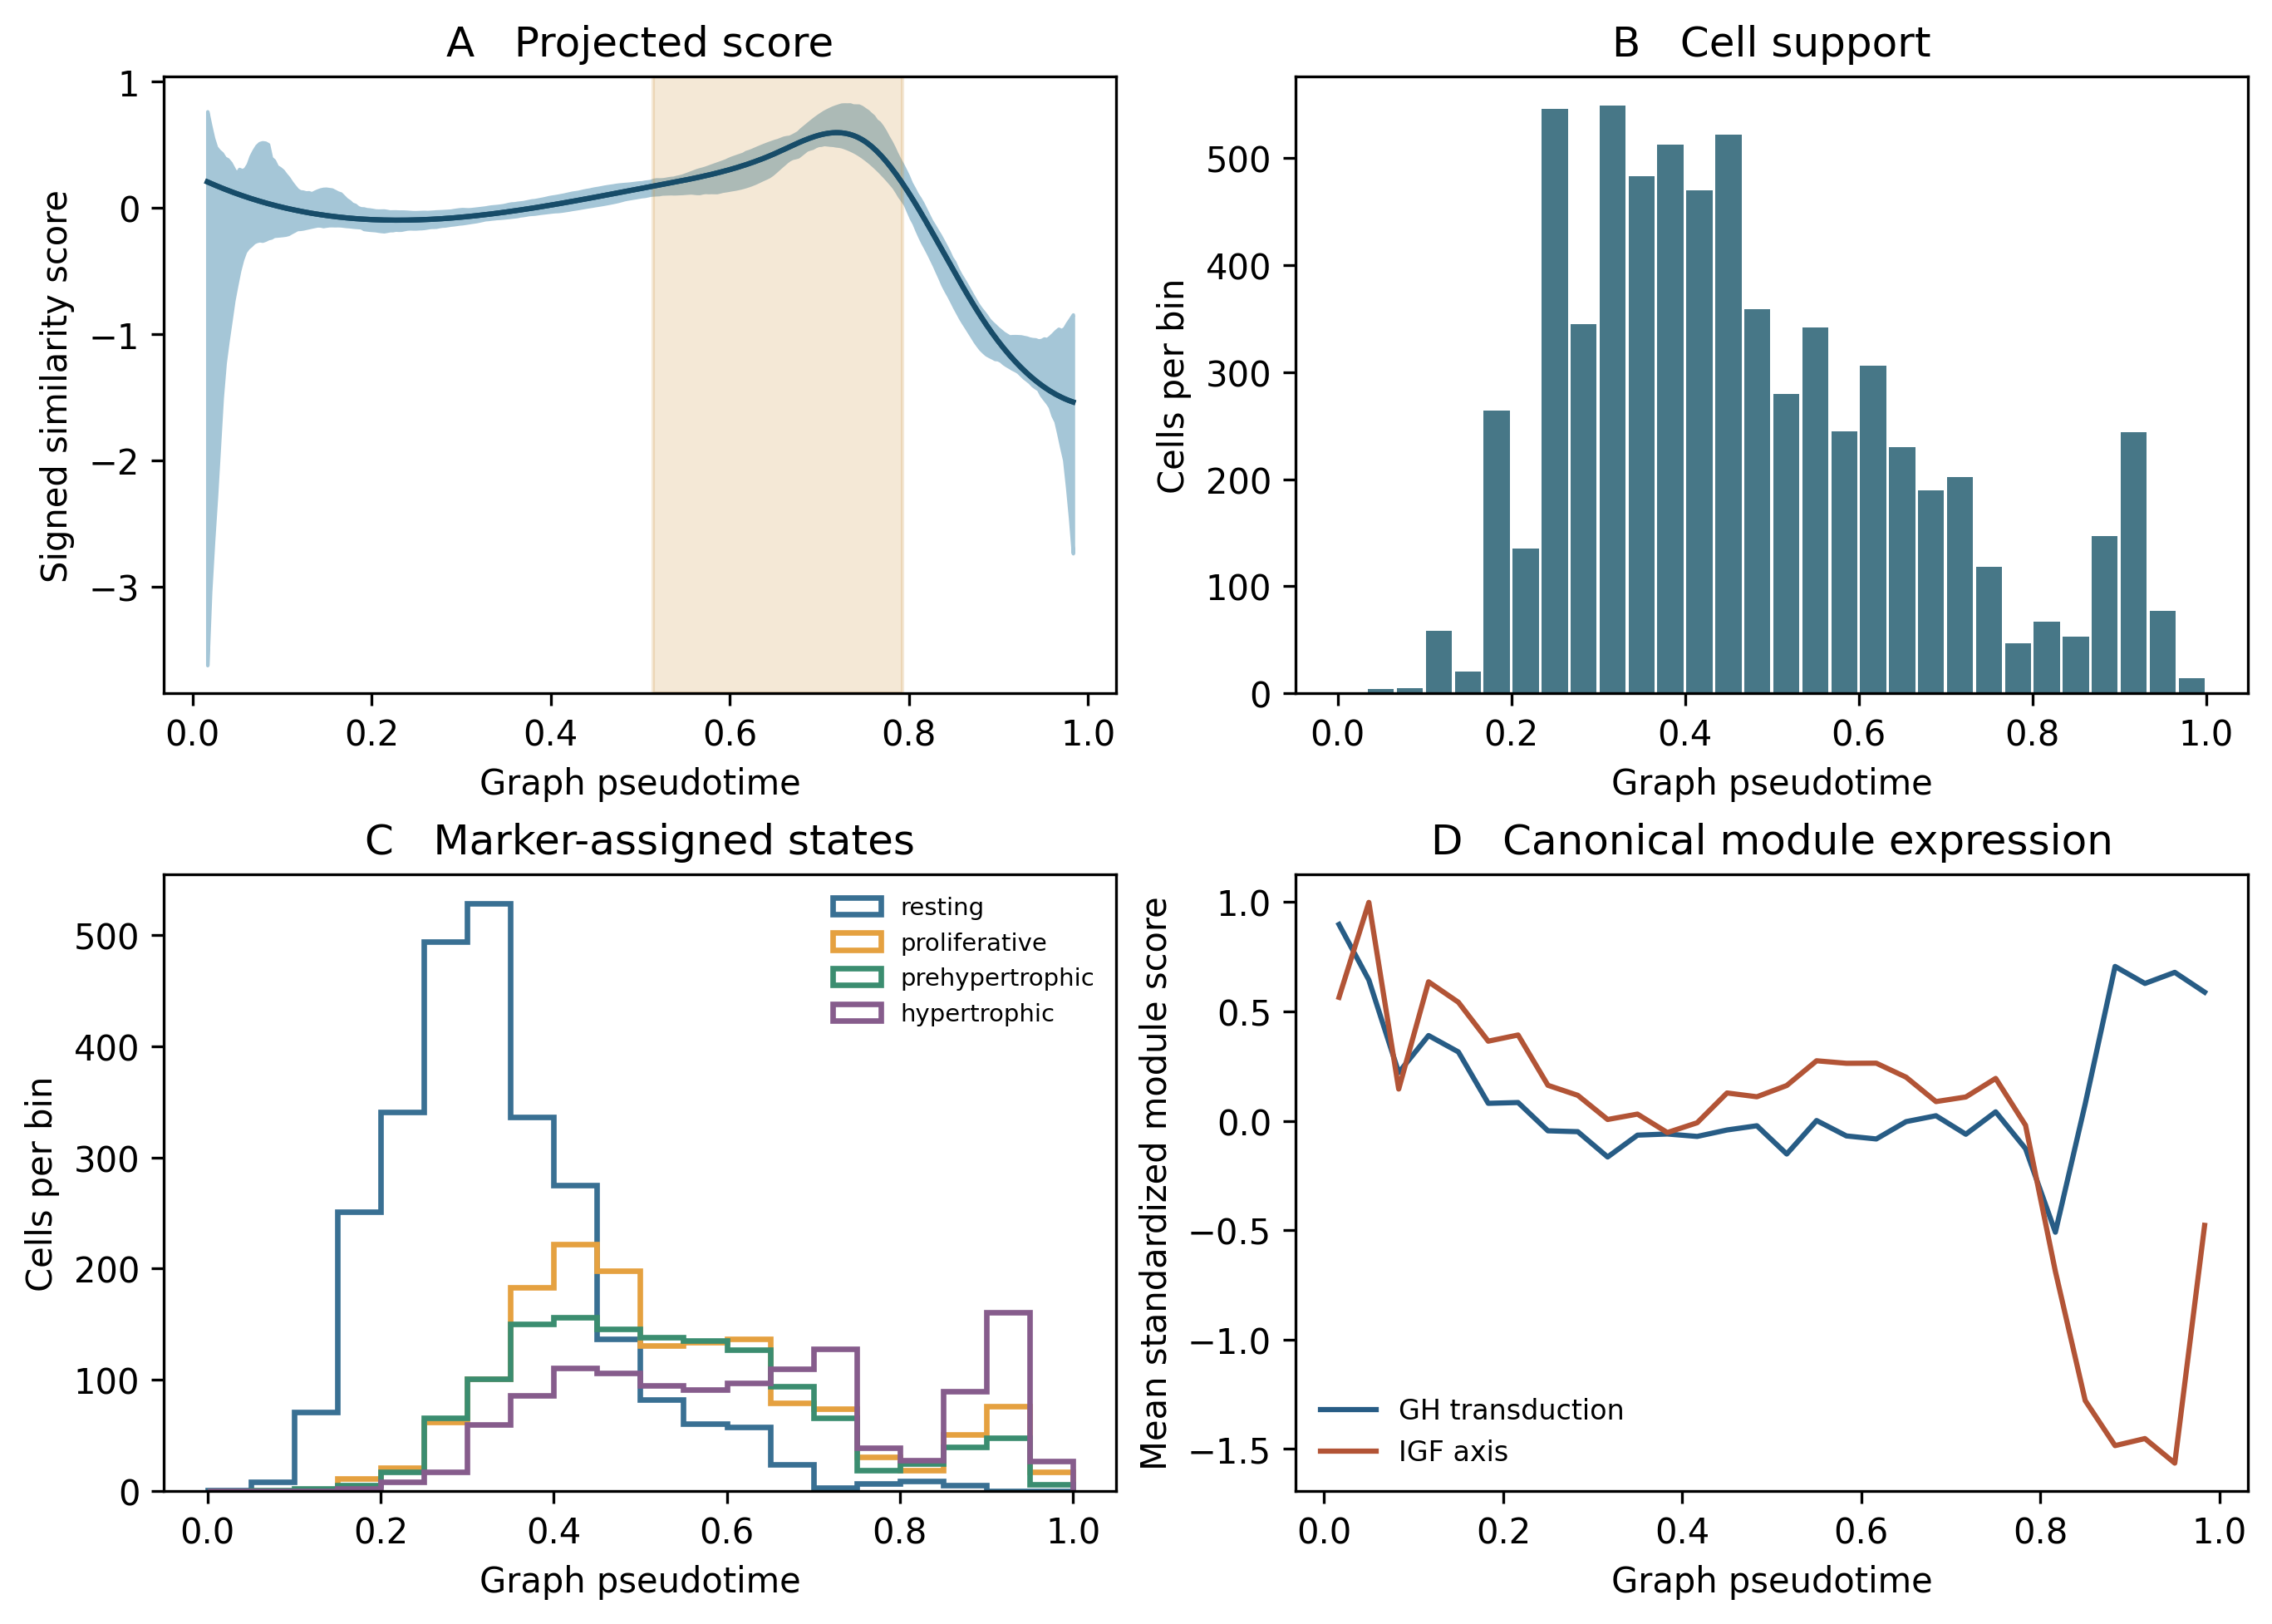

In [22]:
fig1, ax = plt.subplots(2, 2, figsize=(9, 6.4), layout="constrained")
a, b, c, e = ax.flat
a.plot(win["grid"], win["smooth"], color="#174c69")
a.fill_between(win["grid"], win["ci_low"], win["ci_high"], color="#a5c6d7")
a.plot(win["grid"], win["smooth"], color="#174c69")
a.axvspan(lo, hi, color="#cc8e36", alpha=0.2)
a.set(title="A   Projected score", ylabel="Signed similarity score")
b.bar(centers, nb[seen], width=0.03, color="#477787")
b.set(title="B   Cell support", ylabel="Cells per bin")
colors = ["#397093", "#e5a140", "#3b8d70", "#865c8c"]
for lab, col in zip(zones, colors):
    c.hist(
        t[(state == lab) & valid],
        bins=np.linspace(0, 1, 21),
        histtype="step",
        linewidth=1.6,
        label=lab,
        color=col,
    )
c.set(title="C   Marker-assigned states", ylabel="Cells per bin")
c.legend(fontsize=7, frameon=False)
for name, lab, col in [
    ("score_gh_transduction", "GH transduction", "#275c85"),
    ("score_igf_axis", "IGF axis", "#b25436"),
]:
    e.plot(centers, (B @ m[name].values)[seen], label=lab, color=col)
e.set(title="D   Canonical module expression", ylabel="Mean standardized module score")
e.legend(frameon=False, fontsize=8)
for a in ax.flat:
    a.set_xlabel("Graph pseudotime")
export_panel(fig1, "atlas")

### 23 · Locate the interior maximum after rebuilding the graph

Compare interior and full-grid maxima on the two E15 populations. The endpoints have unequal support, so both the score and the population on which its range is calculated matter.



In [23]:
gk = sk["grid"]
fk = sk["smooth"]
bounds = np.quantile(tk[np.isfinite(tk)], [0.1, 0.9])
mk = (gk >= bounds[0]) & (gk <= bounds[1])
im = np.flatnonzero(mk)[np.argmax(fk[mk])]
midcurve = curve(ids, w)[middle]
mi = midcurve.argmax()
mg = grid[middle]
above = midcurve >= midcurve.min() + 0.8 * np.ptp(midcurve)
l = r = mi
while l and above[l - 1]:
    l -= 1
while r + 1 < len(mg) and above[r + 1]:
    r += 1
print(
    "interior ref threshold (original spline)",
    mg[mi],
    mg[l],
    mg[r],
    "filtered interior peak, support",
    gk[im],
    bounds,
    np.histogram(tk, np.linspace(0, 1, 31))[0][:4],
)

interior ref threshold (original spline) 0.7214604236343366 0.6632664437012263 0.7505574136008918 filtered interior peak, support 0.7731884057971015 [0.33189279 0.77624009] [ 1  0 10  2]


### 24 · Draw the annotated embedding for Figure S2

Plot two identical SVD axes colored by assigned state and signed score. Scores saturate at the 99th percentile of absolute values for legibility; the numerical analyses use the untruncated scores.



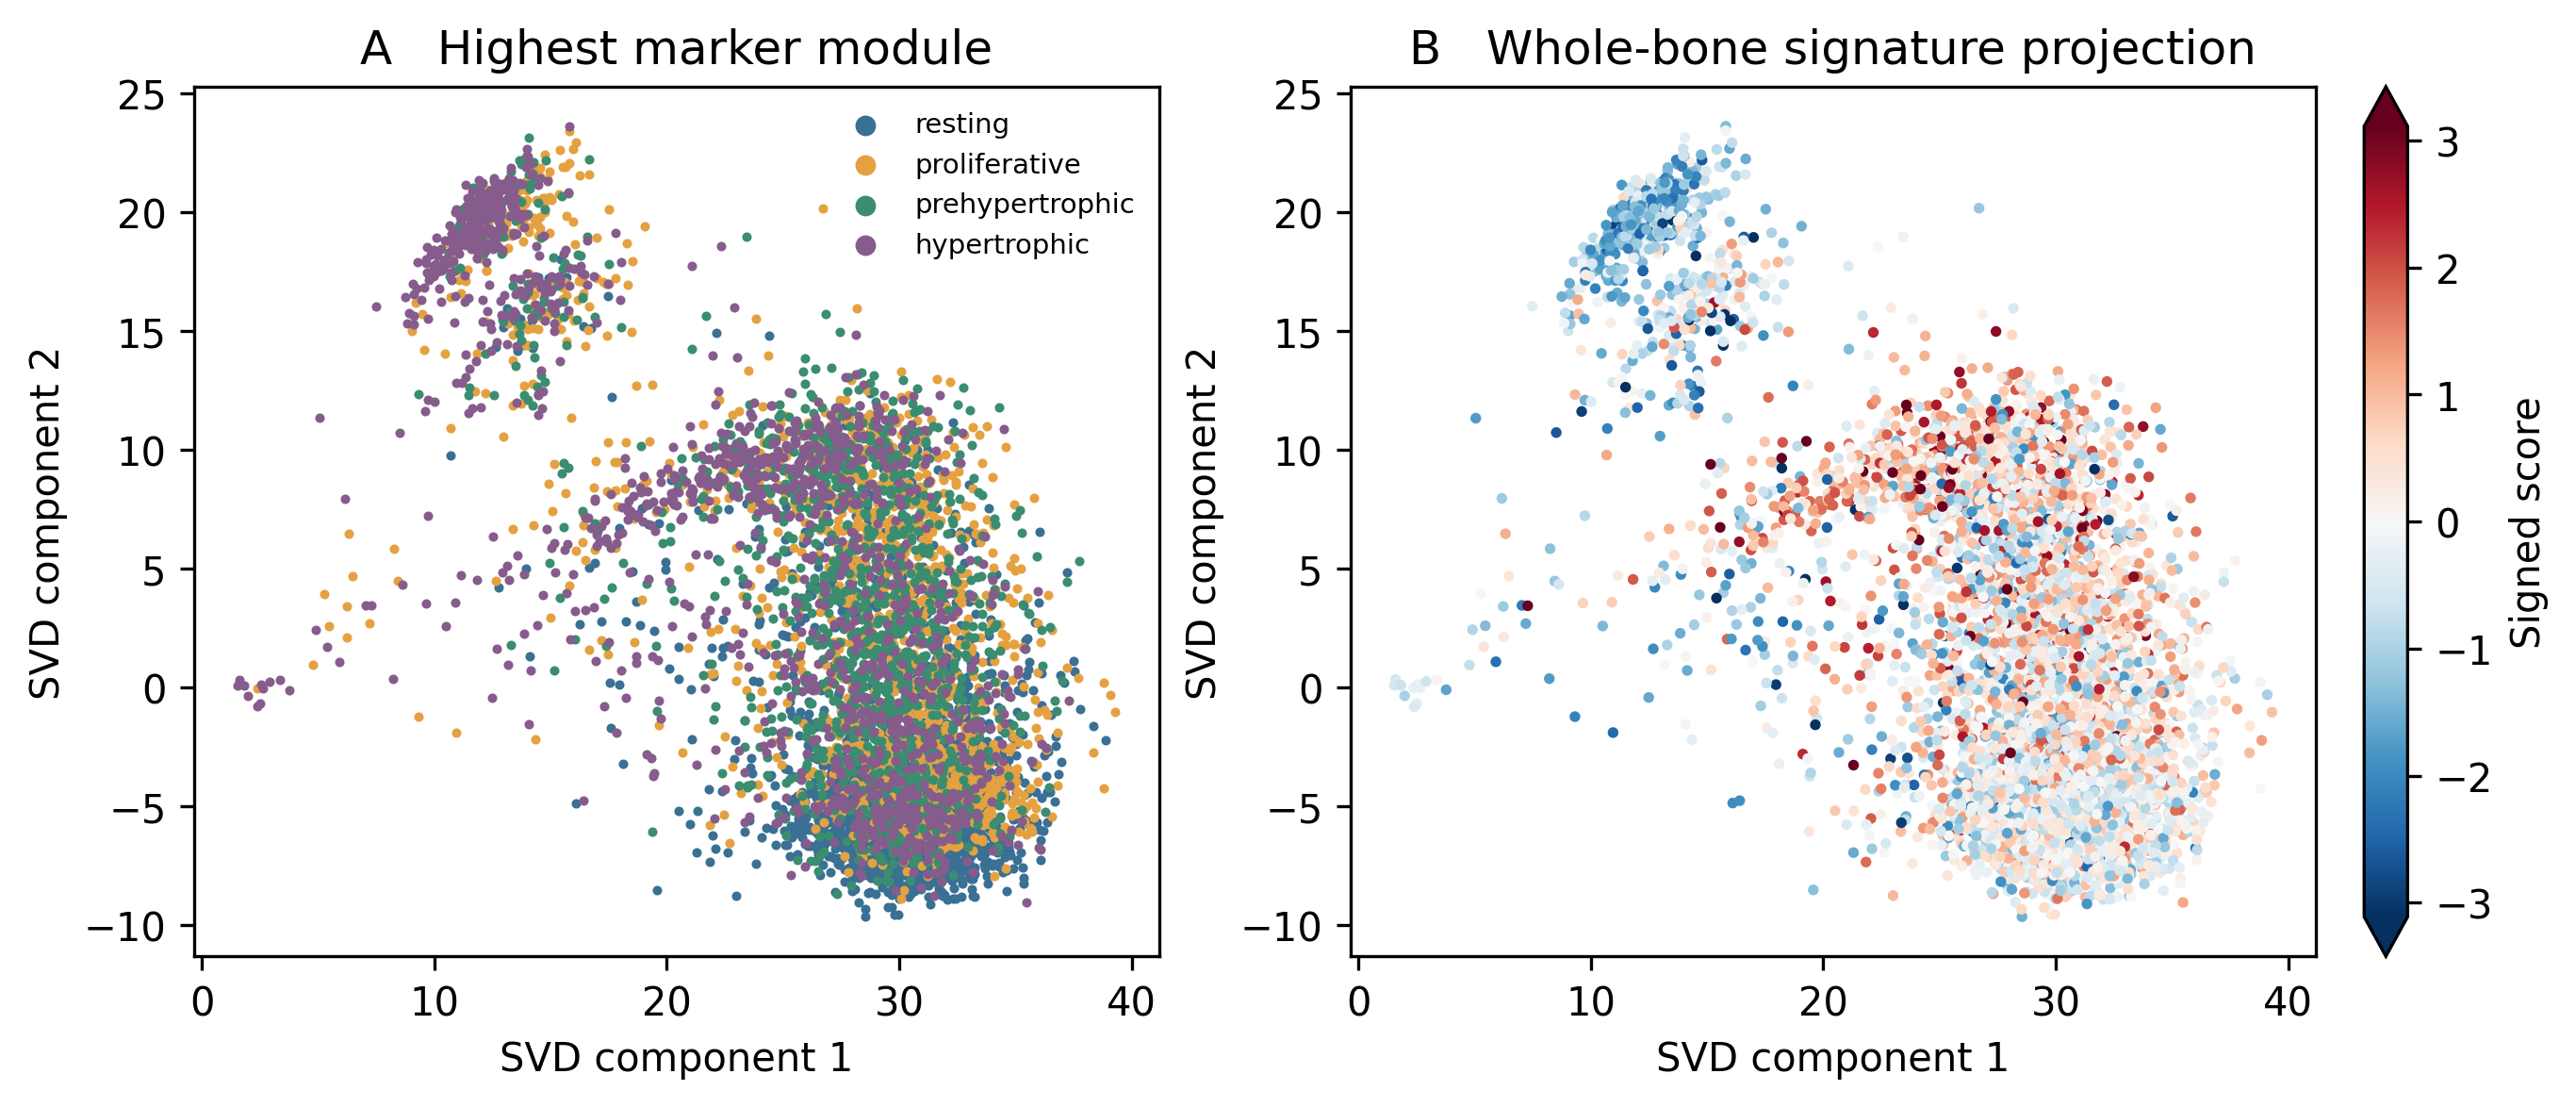

In [24]:
# Use the same PC axes in both panels for a labeled atlas map and a score map.
f, (a, b) = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
for lab, col in zip(zones, colors):
    mask = state == lab
    a.scatter(pcs[mask, 0], pcs[mask, 1], s=2, color=col, label=lab, rasterized=True)
a.legend(fontsize=7, markerscale=3, frameon=False)
a.set_title("A   Highest marker module")
lim = np.quantile(abs(score), 0.99)
art = b.scatter(
    pcs[:, 0], pcs[:, 1], c=score, cmap="RdBu_r", vmin=-lim, vmax=lim, s=3, rasterized=True
)
f.colorbar(art, ax=b, label="Signed score", extend="both")
b.set_title("B   Whole-bone signature projection")
for ax in [a, b]:
    ax.set(xlabel="SVD component 1", ylabel="SVD component 2")
export_panel(f, "embedding")

### 25 · Recover genome-wide and ortholog profiles

Generate similarity values directly from the independently reconstructed mouse and human zones. The primary analysis matches symbols. The sensitivity analysis reindexes those matrices with the embedded one-to-one IDs, normalizes each gene profile and computes one minus its total-variation distance. Export both gene-level tables.

The similarity is $1-\tfrac12\sum_z|\pi^m_{gz}-\pi^h_{gz}|$. The independent shuffle measures how much of a high raw similarity already follows from the marginal distributions.

In [25]:
cons, cs = cross_species_conservation(specs["GSE87605"], specs["GSE9160"])
cons.to_csv(out / "cross_species.csv")
mouse_spec = specs["GSE87605"]
human_spec = specs["GSE9160"]
om = mouse_spec.loc[ortholog_pairs.mouse_gene, zones3].to_numpy()
oh = human_spec.loc[ortholog_pairs.human_gene, zones3].to_numpy()
orth_sim = 1 - np.abs(om / om.sum(1)[:, None] - oh / oh.sum(1)[:, None]).sum(1) / 2
ortholog_pairs.assign(similarity=orth_sim).to_csv(out / "orthologs.csv", index=False)
print(cs, "ortholog mean", orth_sim.mean())

{'n_mouse_genes': 21495, 'n_human_genes': 22876, 'n_symbol_overlap_before_filter': 14499, 'n_ortholog_symbols': 14499, 'mean_gene_conservation': 0.8404665759509092, 'zone_profile_spearman': -1.0} ortholog mean 0.840548447343587


### 26 · Shuffle whole gene profiles and draw Figure S10

Shuffle complete human profiles 10,000 times using all shared genes, then repeat within signature genes only. Compare the observed dominant-zone fractions with human column margins. Keep within-profile zone labels fixed. A basal pairing excess is distinct from a cross-species GH treatment effect.



n, observed, null mean, quantiles, difference, p 14499 0.8404665759509092 0.8363716810131336 [0.83548099 0.83727436] 0.004094894937775595 9.999000099990002e-05
row fractions, human margins, overall agreement, expected agreement [[0.2720895  0.47838453 0.24952598]
 [0.26169984 0.47364174 0.26465842]
 [0.23497367 0.48066098 0.28436535]] [0.25532795 0.47803297 0.26663908] 0.32843644389268223 0.3167327131127113


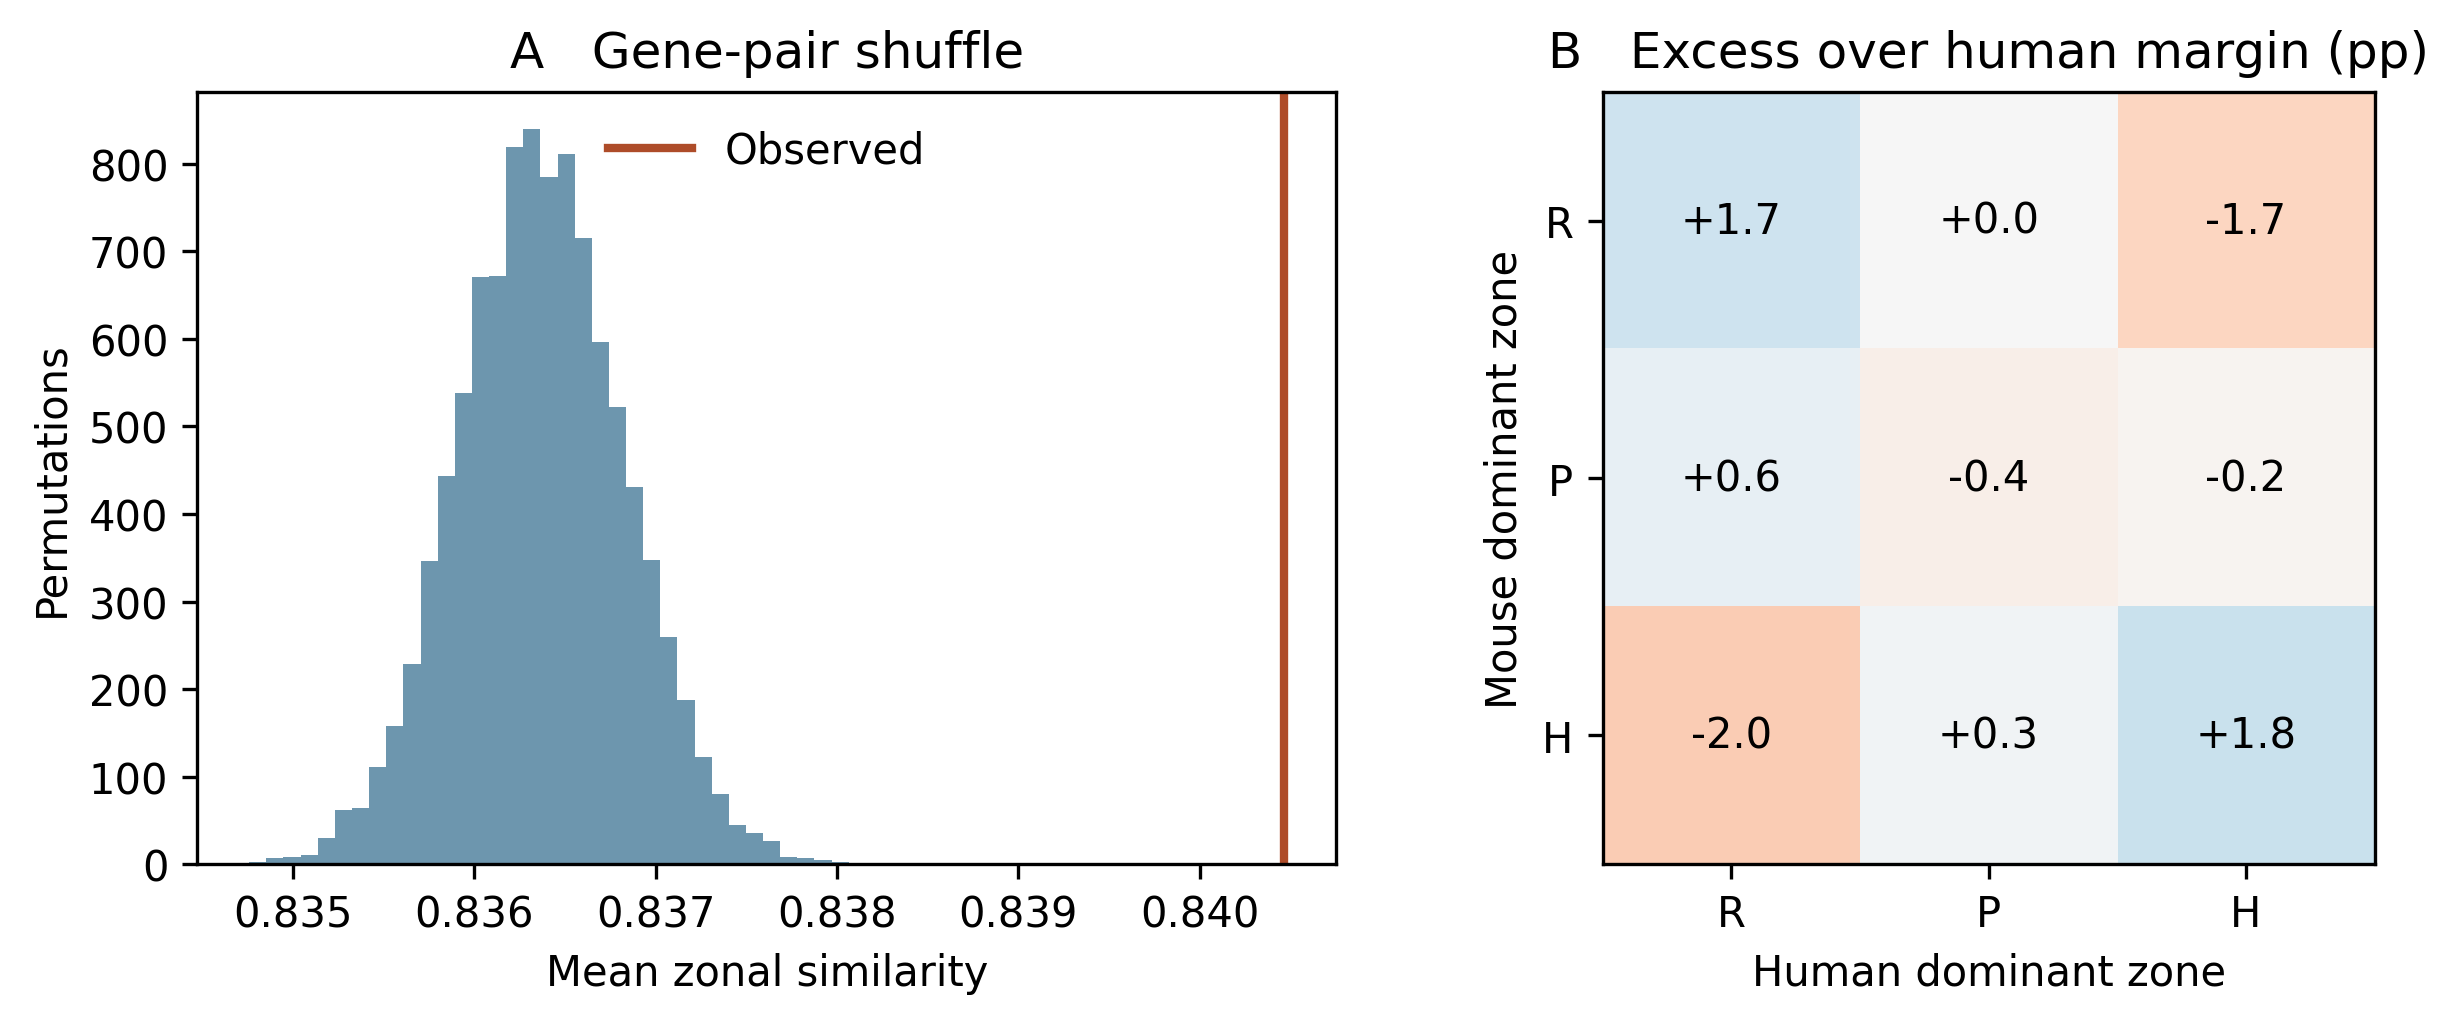

selected subset (n, observed, null mean, 95% interval, p) 144 0.8430452990442218 0.8316107252777325 [0.82236271 0.84132342] 0.0108989101089891


In [26]:
data = cons.rename_axis("gene").reset_index()
zones = ["resting", "proliferative", "hypertrophic"]
mouse, human = [
    data[[f"{species}_{zone}" for zone in zones]].to_numpy() for species in ("mouse", "human")
]
assert data.gene.is_unique and np.isfinite([mouse, human]).all()
similarity = lambda a, b: 1 - np.abs(a - b).sum(axis=1) / 2
assert np.allclose(similarity(mouse, human), data.conservation)
observed = similarity(mouse, human).mean()
rng = np.random.default_rng(271634)
null = np.array(
    [similarity(mouse, human[rng.permutation(len(human))]).mean() for _ in range(10000)]
)
m, h = mouse.argmax(1), human.argmax(1)
counts = np.zeros((3, 3), dtype=int)
np.add.at(counts, (m, h), 1)
fractions = counts / counts.sum(axis=1, keepdims=True)
margins = counts.sum(axis=0) / counts.sum()
print(
    "n, observed, null mean, quantiles, difference, p",
    len(data),
    observed,
    null.mean(),
    np.quantile(null, [0.025, 0.975]),
    observed - null.mean(),
    (1 + (null >= observed).sum()) / (1 + len(null)),
)
print(
    "row fractions, human margins, overall agreement, expected agreement",
    fractions,
    margins,
    counts.trace() / counts.sum(),
    (counts.sum(axis=1) * margins).sum() / counts.sum(),
)
fig, (a, b) = plt.subplots(
    1, 2, figsize=(8.7, 3.3), layout="constrained", gridspec_kw={"width_ratios": [1, 1.1]}
)
a.hist(null, bins=35, color="#6d96ae")
a.axvline(observed, color="#ae4c29", lw=2, label="Observed")
a.set(xlabel="Mean zonal similarity", ylabel="Permutations", title="A   Gene-pair shuffle")
a.legend(frameon=False)
delta = fractions - margins
im = b.imshow(delta, cmap="RdBu", vmin=-0.08, vmax=0.08)
for i, j in np.ndindex(3, 3):
    b.text(j, i, f"{100 * delta[i, j]:+.1f}", ha="center", va="center", color="black")
b.set(
    xticks=range(3),
    yticks=range(3),
    xticklabels=["R", "P", "H"],
    yticklabels=["R", "P", "H"],
    xlabel="Human dominant zone",
    ylabel="Mouse dominant zone",
    title="B   Excess over human margin (pp)",
)
export_panel(fig, "pairing")
# Separate exploratory subset: permute partners only within mapped selected genes.
weights = gh
used = data.gene.isin(weights.index[weights.weight != 0]).to_numpy()
a, b = mouse[used], human[used]
obs = similarity(a, b).mean()
rng = np.random.default_rng(271635)
draws = np.array([similarity(a, b[rng.permutation(len(b))]).mean() for _ in range(10000)])
print(
    "selected subset (n, observed, null mean, 95% interval, p)",
    len(a),
    obs,
    draws.mean(),
    np.quantile(draws, [0.025, 0.975]),
    (1 + (draws >= obs).sum()) / 10001,
)

pd.DataFrame({"all_pairs": null, "signature_pairs": draws}).to_csv(
    out / "pairing_nulls.csv", index=False
)

### 27 · Recover historical robustness and contribution ranks

Recompute size/threshold sensitivity, three weighting rules and twelve root/neighborhood combinations. Reselect the contributing genes and redetermine the interval for every candidate ranking. Export the full rankings, pairwise agreement and top-20 overlaps; inspect Wnt5a across constructions.



In [27]:
meta = atlas["meta"]
size_sens = response_window_sensitivity(X, genes, meta, gh)
weight_sens = signature_weighting_sensitivity(X, genes, meta, gh)
root_sens = pseudotime_root_knn_robustness(
    atlas["pcs"], meta.filter(regex="^score_"), meta.gh_response_score, meta.pseudotime
)
rank_long, rank_summary, rank_matrix = candidate_ranking_sensitivity(X, genes, meta, gh, cons)
for name, table in [
    ("signature_size", size_sens),
    ("weights", weight_sens),
    ("root_knn", root_sens),
    ("ranks", rank_long),
    ("rank_summary", rank_summary),
    ("rank_matrix", rank_matrix),
]:
    table.to_csv(out / f"{name}.csv")
display(rank_summary)
display(rank_matrix.head())
display(root_sens)

,weight_method,n_ranked,n_common_with_primary,rank_spearman_vs_primary,top_k,top_k_jaccard_vs_primary
0,primary,123,123,1.000000,20,1.000000
1,effect_only,121,61,0.714420,20,0.142857
2,evidence_only,123,58,0.169097,20,0.176471


,primary,effect_only,evidence_only
gene,,,
WNT5A,1.0,5.0,110.0
SCIN,2.0,54.0,22.0
NTRK3,3.0,29.0,15.0
KITL,4.0,36.0,NaN
MEG3,5.0,NaN,1.0


,root_strategy,k_neighbors,root_index,finite_fraction,pseudotime_spearman_vs_primary,peak,window_lower,window_upper,window_width
0,resting_centroid_medoid,10,249,1.0,0.936282,0.672965,0.424025,0.760256,0.336232
1,resting_centroid_medoid,15,249,1.0,0.938027,0.689130,0.533946,0.769955,0.236009
2,resting_centroid_medoid,20,249,1.0,0.927695,0.627703,0.356132,0.750557,0.394426
3,resting_centroid_medoid,30,249,1.0,0.931662,0.669732,0.427258,0.753790,0.326533
4,resting_minus_hypertrophic_max,10,4619,1.0,0.972388,0.705295,0.436957,0.773188,0.336232
5,resting_minus_hypertrophic_max,15,4619,1.0,1.000000,0.718227,0.514548,0.792586,0.278038
6,resting_minus_hypertrophic_max,20,4619,1.0,0.981556,0.689130,0.417559,0.760256,0.342698
7,resting_minus_hypertrophic_max,30,4619,1.0,0.974159,0.630936,0.469287,0.731159,0.261873
8,resting_score_max,10,4619,1.0,0.972388,0.705295,0.436957,0.773188,0.336232
9,resting_score_max,15,4619,1.0,1.000000,0.718227,0.514548,0.792586,0.278038


### 28 · Check the original simulation and draw Figure 1

Calibrate the central-range statistic on 1,000 noise-only profiles using the empirical cell density. Test 200 independent profiles with and without an imposed Gaussian peak. Then plot the actual 6-hour and 24-hour gene contrasts separately. Simulated profiles never enter the biological results.



0 17 0.2087606139592569
1 200 0.01632900357207767


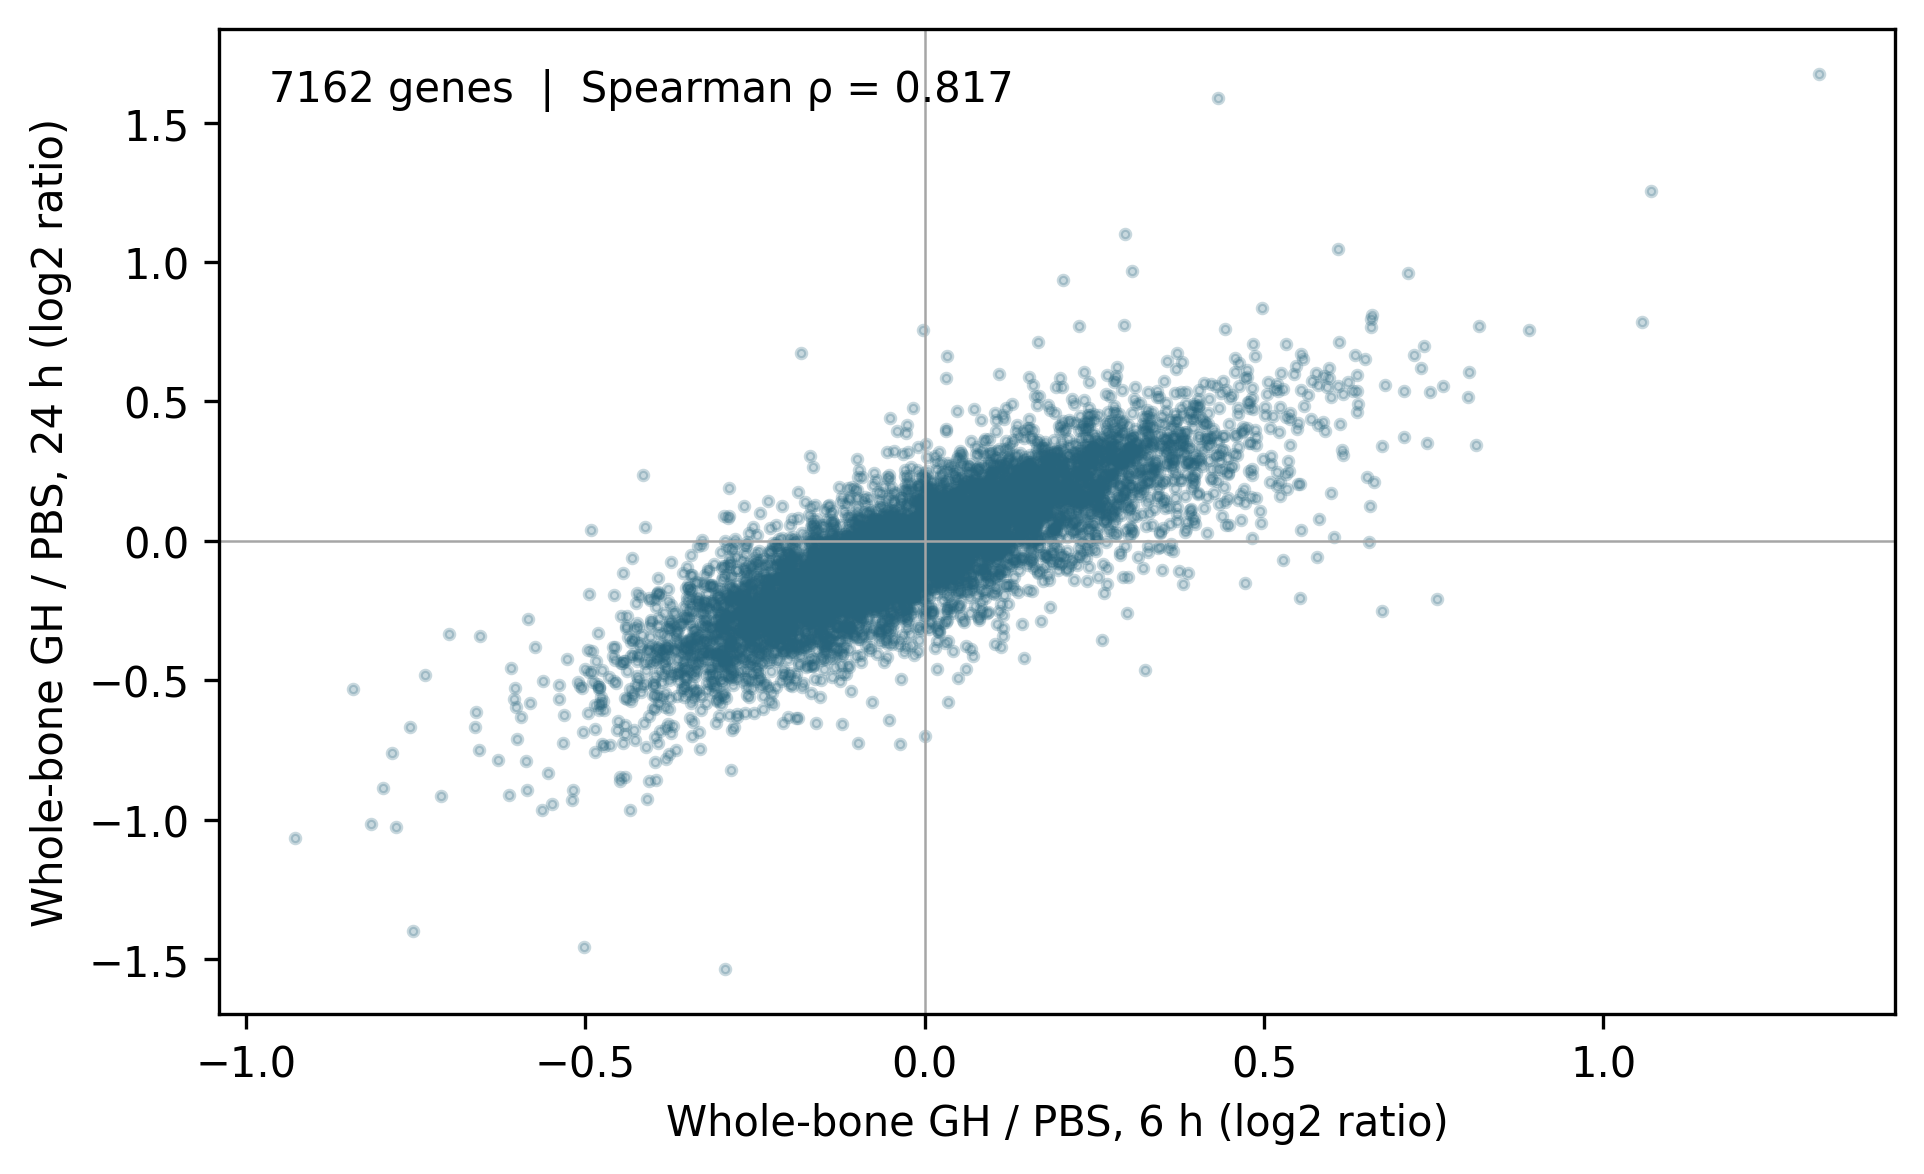

In [28]:
t = pd.read_csv(d / "cells.csv.gz").pseudotime.dropna().to_numpy()
bin_id = np.minimum((30 * t).astype(int), 29)
n = np.bincount(bin_id, minlength=30)
x = (np.flatnonzero(n) + 0.5) / 30
g = np.linspace(*np.quantile(t, [0.1, 0.9]), 200)


def summary(y):
    means = np.bincount(bin_id, weights=y, minlength=30)[n > 0] / n[n > 0]
    pred = UnivariateSpline(x, means, s=0.02 * len(x))(g)
    return np.ptp(pred), g[np.argmax(pred)]


rng = np.random.default_rng(71)
baseline = np.array([summary(rng.normal(size=len(t)))[0] for _ in range(1000)])
threshold = np.quantile(baseline, 0.95)
hits = []
for amplitude in [0, 1]:
    bump = amplitude * np.exp(-0.5 * ((t - 0.60) / 0.08) ** 2)
    results = np.array([summary(bump + rng.normal(size=len(t))) for _ in range(200)])
    hits.append(int((results[:, 0] > threshold).sum()))
    print(amplitude, (results[:, 0] > threshold).sum(), np.median(abs(results[:, 1] - 0.60)))
gh = pd.read_csv(d / "genes.csv", index_col=0)
x = gh.log2fc_6h
y = gh.log2fc_24h
f, a = plt.subplots(figsize=(6.3, 3.8), layout="constrained")
a.scatter(x, y, color="#27647c", s=5, alpha=0.25, rasterized=True)
a.axhline(0, color=".65", lw=0.6)
a.axvline(0, color=".65", lw=0.6)
a.set(
    xlabel="Whole-bone GH / PBS, 6 h (log2 ratio)", ylabel="Whole-bone GH / PBS, 24 h (log2 ratio)"
)
a.text(
    0.03,
    0.96,
    f"{len(gh)} genes  |  Spearman ρ = {x.corr(y, method='spearman'):.3f}",
    va="top",
    transform=a.transAxes,
)
export_panel(f, "time")

### 29 · Define the null-test and robustness figures

Each plot reads the observed or random draw summaries passed to it. Figure S4 prints the amplitude probabilities to four decimal places. The retained-cell robustness drawings are called only after the corresponding graphs have been rebuilt.



In [29]:
def fig_response_window_null_test(
    result: Mapping[str, object],
):
    """Figure 14: observed H1 developmental structure versus two formal null distributions."""
    null = result["null_stats"]
    win = result["observed_window"]
    env = result["envelopes"]
    summ = result["summary"]
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.0))
    ax = axes[0]
    grid = np.asarray(win["grid"], float)
    smooth = np.asarray(win["smooth"], float)
    ax.plot(grid, env["weight_perm_lo"], lw=1, ls=":", label="Weight-permutation 95% null envelope")
    ax.plot(grid, env["weight_perm_hi"], lw=1, ls=":")
    ax.plot(grid, smooth, lw=2, label="Observed GH projection")
    ax.axvline(float(win["peak"]), ls="--", lw=1)
    ax.set_xlabel("Pseudotime")
    ax.set_ylabel("Smoothed signed projection")
    ax.set_title("Observed developmental profile")
    ax.legend(fontsize=7)
    for ax, nt, title, pkey in [
        (
            axes[1],
            "weight_permutation",
            "Weight-permutation null",
            "weight_permutation_p_amplitude",
        ),
        (
            axes[2],
            "matched_random_genes",
            "Expression/detection-matched genes",
            "matched_gene_p_amplitude",
        ),
    ]:
        vals = (
            pd.to_numeric(null.loc[null.null_type == nt, "amplitude"], errors="coerce")
            .dropna()
            .to_numpy(float)
        )
        ax.hist(vals, bins=30)
        ax.axvline(float(summ["observed_amplitude"]), lw=2, ls="--")
        ax.set_xlabel(r"$T_{H1}=\max f-\min f$")
        ax.set_ylabel("Null realizations")
        ax.set_title(f"{title}\nempirical p={float(summ[pkey]):.4f}")
    fig.suptitle(
        "H1 formal null test: maturation-dependent structure of the GH-signature projection", y=1.03
    )
    fig.tight_layout()
    export_panel(fig, "fig14_h1_developmental_structure_null")
    plt.close(fig)


def fig_zonal_localization_null_test(
    result: Mapping[str, object], stem: str = "fig15_h2_zonal_localization_null"
):
    """Figure 15: H2 observed zonal burden versus label-permutation and matched-gene nulls."""
    summ = result["summary"]
    zs = result["zone_summary"]
    null = result["null_stats"]
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.0))
    x = np.arange(len(zs))
    obs = zs["observed_burden"].to_numpy(float)
    axes[0].bar(x, obs, width=0.55, label="Observed")
    axes[0].errorbar(
        x - 0.14,
        zs["label_null_median"],
        yerr=[
            zs["label_null_median"] - zs["label_null_lo"],
            zs["label_null_hi"] - zs["label_null_median"],
        ],
        fmt="o",
        capsize=3,
        label="Label-permutation null",
    )
    axes[0].errorbar(
        x + 0.14,
        zs["matched_null_median"],
        yerr=[
            zs["matched_null_median"] - zs["matched_null_lo"],
            zs["matched_null_hi"] - zs["matched_null_median"],
        ],
        fmt="s",
        capsize=3,
        label="Matched-gene null",
    )
    axes[0].set_xticks(x, zs["zone"], rotation=20)
    axes[0].set_ylabel("Unsigned GH-signature burden")
    axes[0].set_title("Observed burden and 95% null intervals")
    axes[0].legend(fontsize=7)
    for ax, nt, title, pkey in [
        (
            axes[1],
            "within_gene_zone_label_permutation",
            "Within-gene zone-label permutation",
            "label_permutation_p",
        ),
        (
            axes[2],
            "mean_expression_matched_random_genes",
            "Mean-expression-matched random genes",
            "matched_gene_p",
        ),
    ]:
        vals = (
            pd.to_numeric(null.loc[null.null_type == nt, "structure_statistic"], errors="coerce")
            .dropna()
            .to_numpy(float)
        )
        ax.hist(vals, bins=30)
        ax.axvline(float(summ["observed_structure_statistic"]), lw=2, ls="--")
        ax.set_xlabel(r"$T_{H2}=\|Q-1/K\|_2$")
        ax.set_ylabel("Null realizations")
        ax.set_title(f"{title}\nempirical p={float(summ[pkey]):.4f}")
    fig.suptitle("H2 formal null test: non-random growth-plate zonal localization", y=1.03)
    fig.tight_layout()
    export_panel(fig, stem)
    plt.close(fig)


def fig_response_window_sensitivity(
    sens: pd.DataFrame,
):
    """Publication-grade robustness figure used as primary Figure 8.

    Each point is the estimated peak pseudotime and each vertical segment is the corresponding
    high-response interval. Marker shape identifies the threshold definition. This replaces the
    former externally dependent height-candidate Figure 8.
    """
    if sens is None or sens.empty:
        raise ValueError("Response-window sensitivity table is empty")
    fig, ax = plt.subplots(figsize=(7.2, 5.2))
    thresholds = sorted(pd.unique(sens["threshold_fraction"]))
    markers = ["o", "s", "^"]
    for j, q in enumerate(thresholds):
        d = sens.loc[np.isclose(sens["threshold_fraction"].astype(float), float(q))].sort_values(
            "requested_signature_size"
        )
        x = d["requested_signature_size"].to_numpy(float)
        y = d["peak"].to_numpy(float)
        lower = y - d["window_lower"].to_numpy(float)
        upper = d["window_upper"].to_numpy(float) - y
        ax.errorbar(
            x,
            y,
            yerr=np.vstack([lower, upper]),
            marker=markers[j % len(markers)],
            capsize=4,
            linewidth=1.6,
            label=f"{int(round(100 * q))}% interval threshold",
        )
    ax.axhline(0.5, linestyle=":", linewidth=1)
    ax.set_xlabel("Requested number of ranked whole-bone genes")
    ax.set_ylabel("Geodesic pseudotime")
    ax.set_ylim(0, 1)
    ax.set_title("Fitted maximum across signature sizes and thresholds")
    ax.legend(frameon=False)
    ax.text(
        0.02,
        0.02,
        "Point: fitted maximum. Bar: connected high-score interval.",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=9,
    )
    export_panel(fig, "fig08_response_window_sensitivity")
    plt.close(fig)


def fig_signature_weighting_sensitivity(
    sens: pd.DataFrame,
):
    if sens is None or sens.empty:
        raise ValueError("Signature-weighting sensitivity table is empty")
    labels = {
        "primary": "Primary: Z x effect",
        "effect_only": "Effect only",
        "evidence_only": "Signed Z only",
    }
    d = sens.copy()
    x = np.arange(len(d))
    y = d["peak"].to_numpy(float)
    lower = y - d["window_lower"].to_numpy(float)
    upper = d["window_upper"].to_numpy(float) - y
    fig, ax = plt.subplots(figsize=(7.4, 5.0))
    ax.errorbar(x, y, yerr=np.vstack([lower, upper]), fmt="o", capsize=5, linewidth=1.6)
    ax.set_xticks(x, [labels.get(v, v) for v in d["weight_method"]], rotation=12, ha="right")
    ax.set_ylabel("Geodesic pseudotime")
    ax.set_ylim(0, 1)
    ax.set_title("Fitted maximum across whole-bone weight definitions")
    for i, row in d.reset_index(drop=True).iterrows():
        rho = row.get("score_spearman_vs_primary", np.nan)
        if np.isfinite(rho):
            ax.text(
                i, min(0.98, row["window_upper"] + 0.04), f"rho={rho:.2f}", ha="center", fontsize=9
            )
    export_panel(fig, "fig11_signature_weighting_sensitivity")
    plt.close(fig)


def fig_pseudotime_root_knn_robustness(
    sens: pd.DataFrame,
):
    if sens is None or sens.empty:
        raise ValueError("Pseudotime robustness table is empty")
    labels = {
        "resting_minus_hypertrophic_max": "Resting - hypertrophic max",
        "resting_score_max": "Resting-score max",
        "resting_centroid_medoid": "Resting top-decile medoid",
    }
    fig, ax = plt.subplots(figsize=(8.0, 5.2))
    markers = ["o", "s", "^"]
    for j, strategy in enumerate(pd.unique(sens["root_strategy"])):
        d = sens[sens["root_strategy"] == strategy].sort_values("k_neighbors")
        x = d["k_neighbors"].to_numpy(float)
        y = d["peak"].to_numpy(float)
        lower = y - d["window_lower"].to_numpy(float)
        upper = d["window_upper"].to_numpy(float) - y
        ax.errorbar(
            x,
            y,
            yerr=np.vstack([lower, upper]),
            marker=markers[j % len(markers)],
            capsize=4,
            linewidth=1.4,
            label=labels.get(strategy, strategy),
        )
    ax.set_xlabel("k in k-nearest-neighbor graph")
    ax.set_ylabel("Pseudotime of the fitted maximum")
    ax.set_ylim(0, 1)
    ax.set_title("Pseudotime robustness to root definition and neighborhood size")
    ax.legend(frameon=False, fontsize=9)
    export_panel(fig, "fig12_pseudotime_root_knn_robustness")
    plt.close(fig)

### 30 · Draw Figures S4 and S5 from the observed permutation runs

Write the previous six-target audit for comparison. Export the original H1 amplitude distributions and the newborn zonal nulls. The S4 probability labels and the manuscript macros use the same H1 summary.



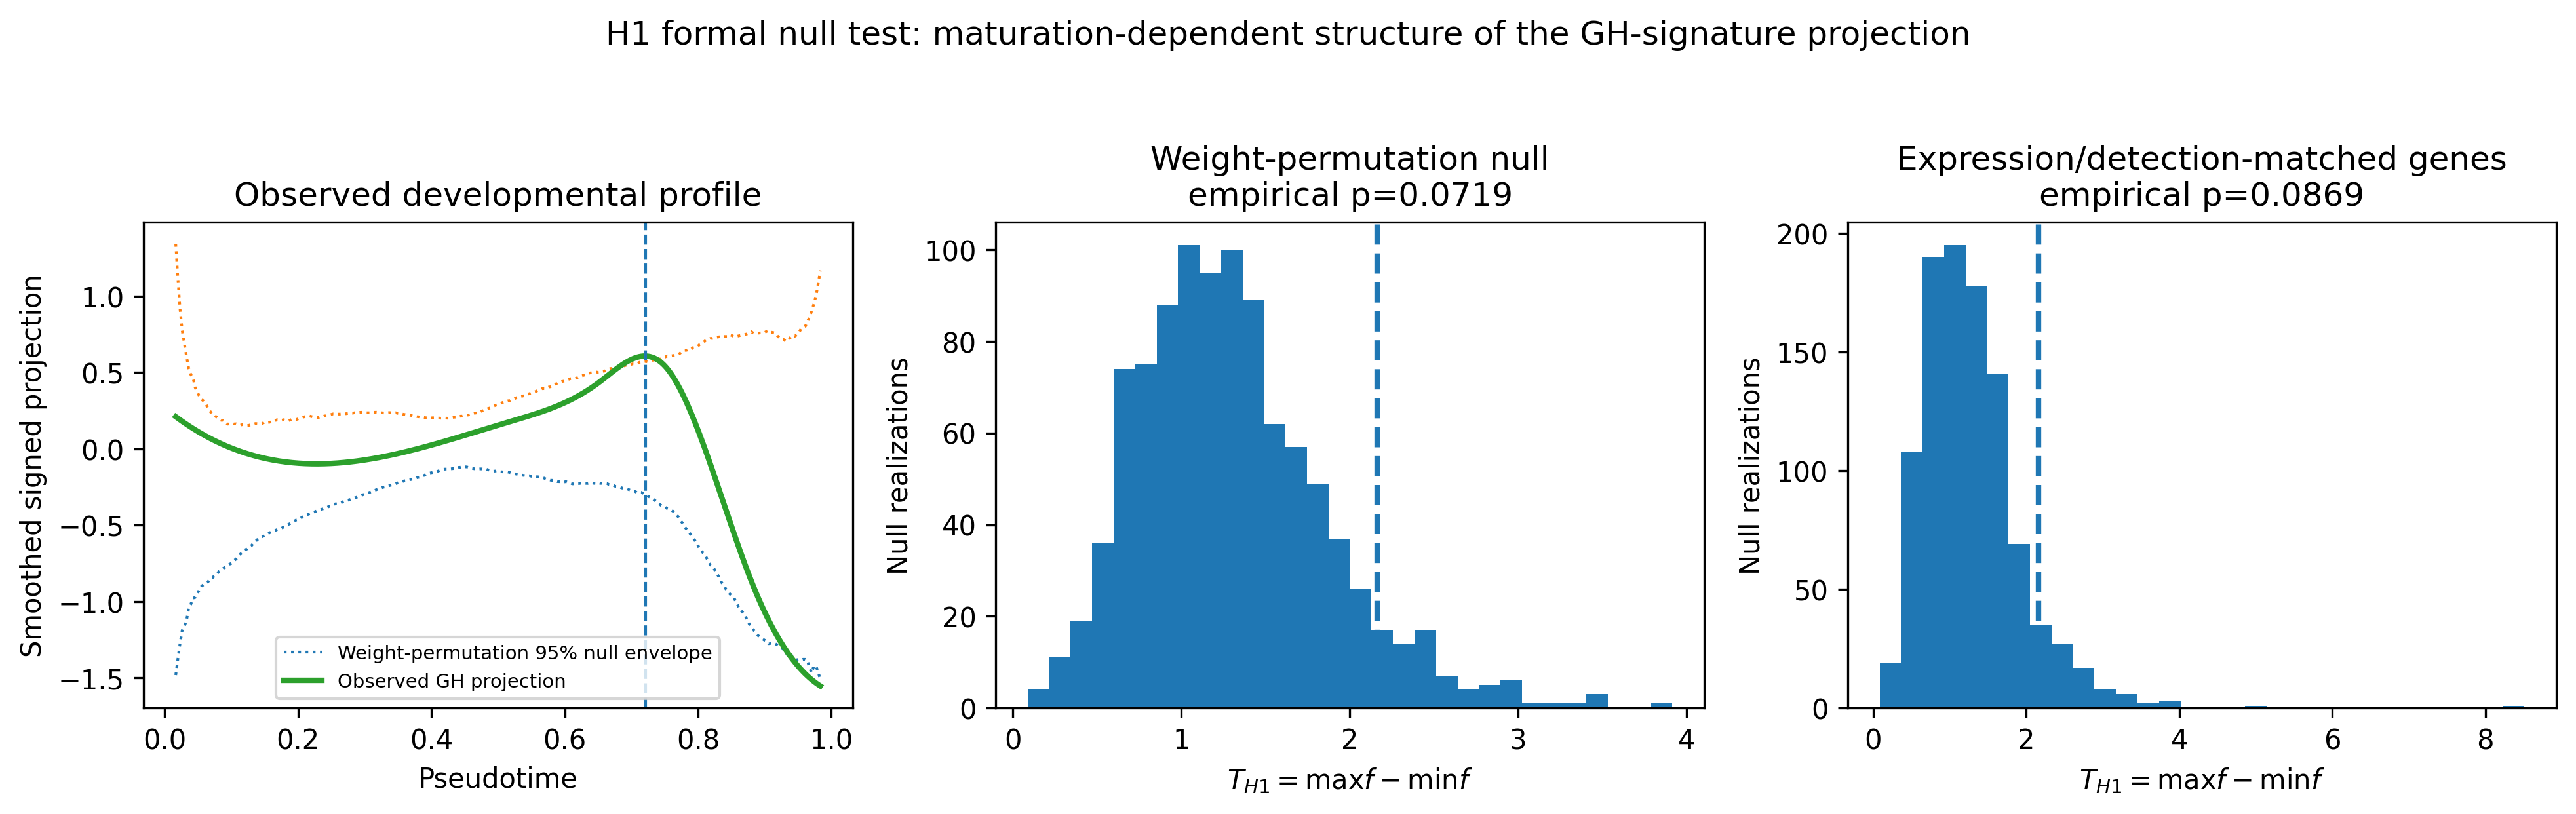

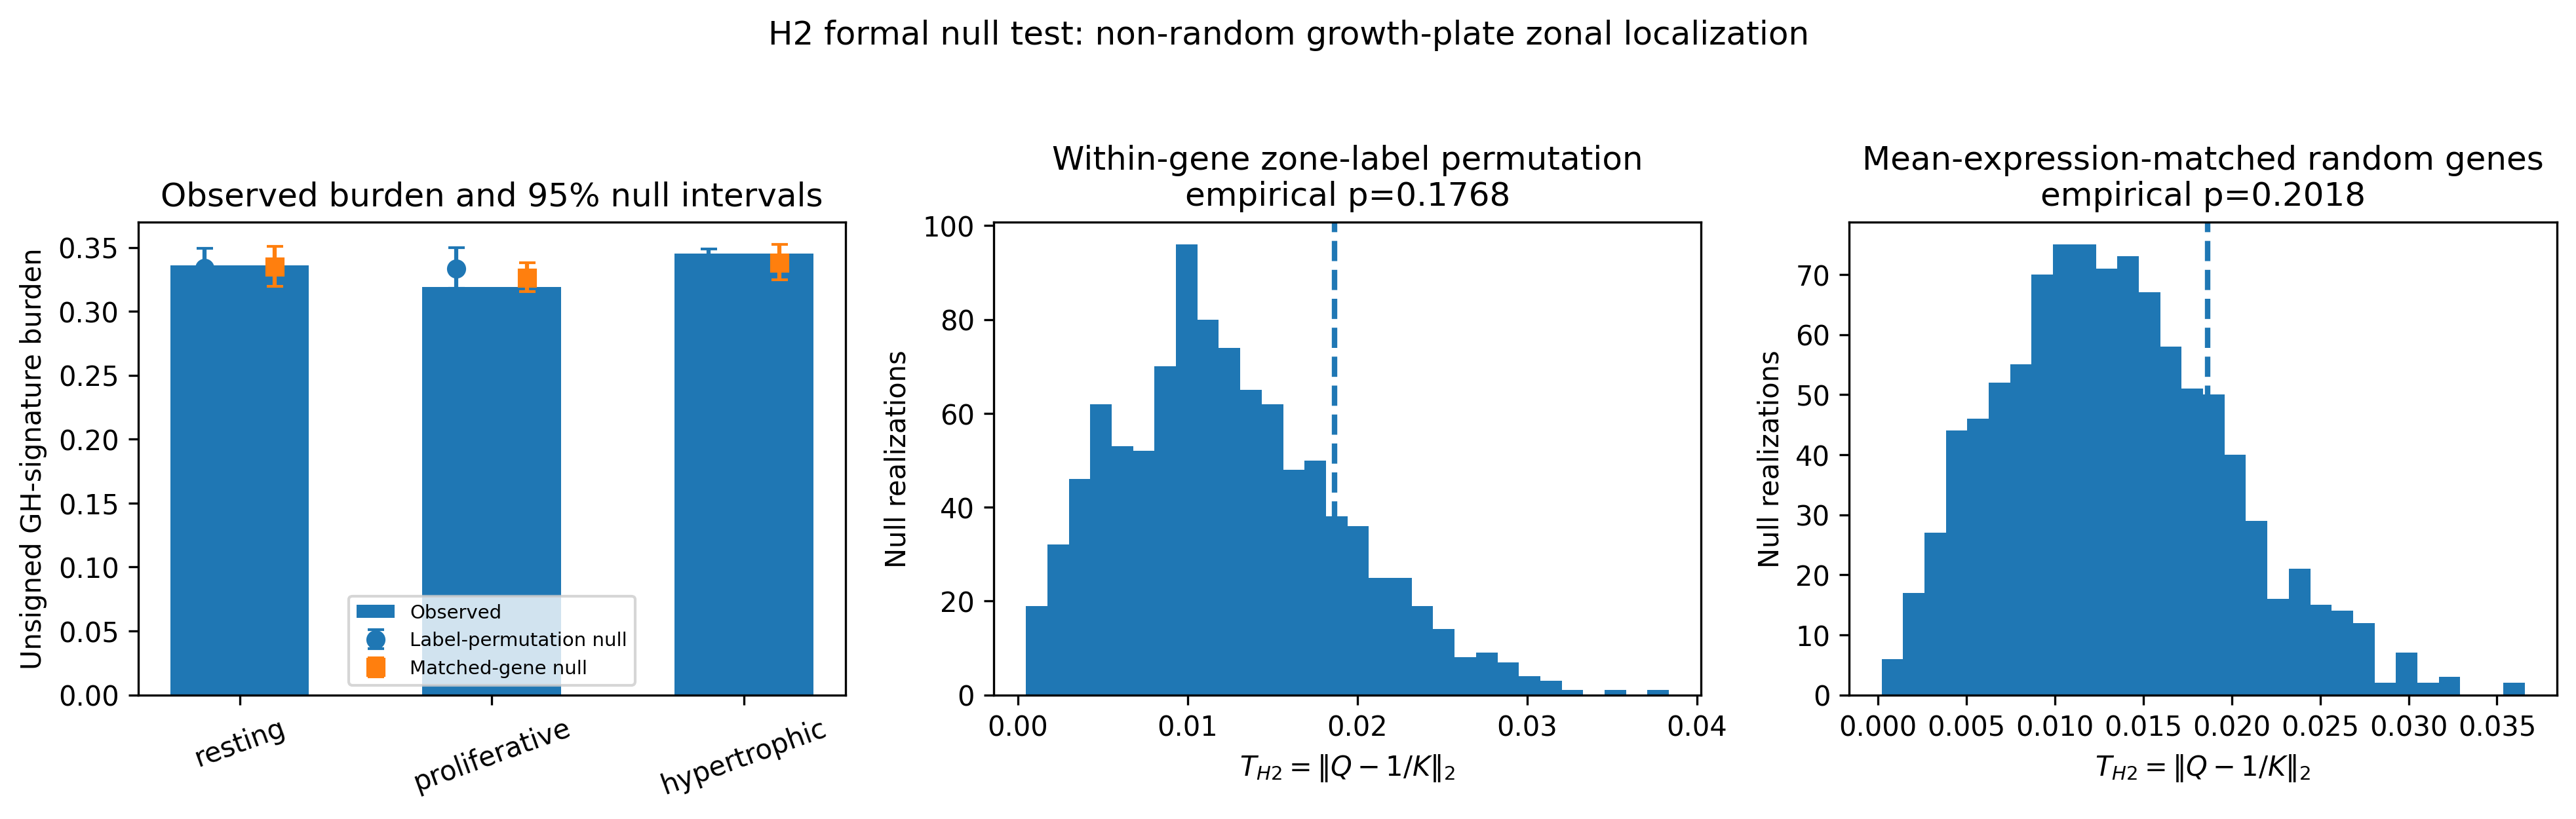

In [30]:
target_qc = gse3689_published_target_qc(gh)
target_qc.to_csv(out / "published_target_qc.csv", index=False)
fig_response_window_null_test(h1)
fig_zonal_localization_null_test(zonal_tests["GSE87605"])

### 31 · Verify 43 original and first-revision quantities

Audit published historical values with precision-specific tolerances. Subsequent cells test the new analyses and verify that every figure was exported.



In [31]:
checks = []


def check(name, computed, reported, tolerance):
    computed = float(computed)
    checks.append(
        dict(
            quantity=name,
            computed=computed,
            reported=reported,
            tolerance=tolerance,
            passed=bool(abs(computed - reported) <= tolerance),
        )
    )


for key, num in [("6h", 0), ("24h", 2), ("combined", 909)]:
    check("BH discoveries " + key, (gh["fdr_" + key] < 0.05).sum(), num, 0)
check("Selected passing combined BH", ((gh.weight != 0) & (gh.fdr_combined < 0.05)).sum(), 262, 0)
check("Temporal Spearman", gh.log2fc_6h.corr(gh.log2fc_24h, method="spearman"), 0.817, 0.0005)
check("Cells", len(meta), 6836, 0)
check("Mapped signature genes", len(selected), 153, 0)
check("Nonconstant genes", len(ids), 150, 0)
check("Inside interval", inside.sum(), 1833, 0)
check("Original peak", win["peak"], 0.718, 0.0005)
check("Original lower edge", win["window_lower"], 0.515, 0.0005)
check("Original upper edge", win["window_upper"], 0.793, 0.0005)
check("Cartilage-cluster cells", len(tk), 5457, 0)
check("Restricted peak", sk["peak"], 0.017, 0.0005)
check("Interior amplitude", metrics(curve(ids, w))[1], 0.70, 0.005)
check("Three-variable matched interior p", revision_null_p[1, 1], 0.141, 0.0005)
for key, n in [
    ("weight_permutation_p_amplitude", 0.0719),
    ("matched_gene_p_amplitude", 0.0869),
    ("weight_permutation_p_variance", 0.038),
    ("matched_gene_p_variance", 0.036),
]:
    check(key, h1["summary"][key], n, 0.0005)
for acc, expect in [
    ("GSE87605", (0.0186, 0.177, 0.202)),
    ("GSE14007", (0.0817, 1 / 1001, 1 / 1001)),
]:
    for k, v0 in zip(
        ["observed_structure_statistic", "label_permutation_p", "matched_gene_p"], expect
    ):
        check(acc + " " + k, h2[acc][k], v0, 0.0005)
check("Shared symbols", len(cons), 14499, 0)
check("Paired similarity", cons.conservation.mean(), 0.84047, 0.000005)
check("Shuffled mean", null.mean(), 0.83637, 0.000005)
check("Ortholog pairs", len(orth_sim), 13680, 0)
check("Ortholog similarity", orth_sim.mean(), 0.84054845, 0.00000001)
check("Signature subset n", used.sum(), 144, 0)
check("Signature subset shuffle p", (1 + (draws >= obs).sum()) / 10001, 0.0109, 0.00005)
for name, df, target, tol in [
    ("Size", size_sens, 0.00323, 0.000005),
    ("Weight", weight_sens, 0.133, 0.0005),
    ("Graph", root_sens, 0.0905, 0.00005),
]:
    check(name + " peak range", np.ptp(df.peak), target, tol)
for method, rank in [("primary", 1), ("effect_only", 5), ("evidence_only", 110)]:
    check("Wnt5a " + method, rank_matrix.loc["WNT5A", method], rank, 0)
alternatives = rank_summary[rank_summary.weight_method != "primary"]
check("Candidate rank correlation", alternatives.rank_spearman_vs_primary.median(), 0.442, 0.0005)
check("Top-20 Jaccard", alternatives.top_k_jaccard_vs_primary.median(), 0.16, 0.005)
check("Noise positives", hits[0], 17, 0)
check("Signal positives", hits[1], 200, 0)
audit = pd.DataFrame(checks)
audit.to_csv(out / "reproduction_audit.csv", index=False)
(root / "environment.json").write_text(
    json.dumps({"python": sys.version, "versions": versions}, indent=2)
)
display(audit)
assert audit.passed.all(), audit.loc[~audit.passed].to_string(index=False)
print(f"{len(audit)} checks passed. Results: {display_path(root)}")

,quantity,computed,reported,tolerance,passed
0,BH discoveries 6h,0.000000,0.000000,0.000000e+00,True
1,BH discoveries 24h,2.000000,2.000000,0.000000e+00,True
2,BH discoveries combined,909.000000,909.000000,0.000000e+00,True
3,Selected passing combined BH,262.000000,262.000000,0.000000e+00,True
4,Temporal Spearman,0.817326,0.817000,5.000000e-04,True
5,Cells,6836.000000,6836.000000,0.000000e+00,True
6,Mapped signature genes,153.000000,153.000000,0.000000e+00,True
7,Nonconstant genes,150.000000,150.000000,0.000000e+00,True
8,Inside interval,1833.000000,1833.000000,0.000000e+00,True
9,Original peak,0.718227,0.718000,5.000000e-04,True


43 checks passed. Results: GHIR_reproduction


### 32 · Define atlas inputs and independent anatomical controls

Read the deposited P28 counts and apply the same QC and lineage rules as at E15. Resolve unambiguous MGI aliases separately from direct matches. Rank genes using only the newborn anatomical arrays and exclude marker and exposure genes before selecting 50 per program.

Python opens the HDF5 file in binary read mode and passes the open stream to h5py. This lets the postnatal analysis read folders with non-ASCII names on Windows.

In [32]:
"""Cartilage populations, historical symbols and independent anatomical controls."""
from dataclasses import dataclass
from pathlib import Path
import hashlib
import os
from collections import Counter
import numpy as np
import pandas as pd
import h5py
from scipy import sparse
from scipy.interpolate import UnivariateSpline
from scipy.stats import spearmanr, binomtest
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

LINEAGES = {
    "cartilage": ["Col2a1", "Acan", "Sox9", "Comp", "Col9a1"],
    "immune": ["Ptprc", "Lyz2", "Tyrobp"],
    "endothelial": ["Pecam1", "Cdh5", "Kdr"],
    "bone/perichondrium": ["Col1a1", "Col1a2", "Sp7", "Bglap"],
    "interzone": ["Gdf5", "Wnt9a", "Prg4"],
    "epithelial": ["Epcam", "Krt8", "Krt18"],
}
SEX_PANEL = ["Xist", "Ddx3y", "Kdm5d", "Eif2s3y", "Uty"]
DATA_P28 = "GSM8769462_3402_filtered_feature_bc_matrix.h5"


def read_postnatal(inputs):
    """Recover sparse gene-expression counts from the deposited 10x HDF5 file."""
    path = inputs / DATA_P28
    # Python opens the Unicode path. h5py receives a binary stream and closes first.
    with path.open("rb") as source, h5py.File(source, "r") as f:
        m = f["matrix"]
        X = sparse.csc_matrix(
            (m["data"][:], m["indices"][:], m["indptr"][:]), shape=tuple(m["shape"][:])
        ).T.tocsr()
        features = m["features/name"].asstr()[:]
        use = m["features/feature_type"].asstr()[:] == "Gene Expression"
        bc = m["barcodes"].asstr()[:]
    return qc_and_normalize_sc(X[:, use], features[use], bc, max_cells=None)


def subset_lineages(X, genes, meta, dataset, out):
    """Choose clusters before scoring the exposure signature, with the same rule at both ages."""
    pcs, _, _ = select_hvg_and_pca(X, genes)
    labels = KMeans(n_clusters=18, n_init=10, random_state=42).fit_predict(pcs)
    lookup = gene_lookup(genes)
    scores = pd.DataFrame(
        {
            k: np.asarray(
                X[:, [lookup[g.upper()] for g in gs if g.upper() in lookup]].mean(axis=1)
            ).ravel()
            for k, gs in LINEAGES.items()
        }
    )
    profile = scores.groupby(labels).mean()
    profile["assignment"] = profile.idxmax(axis=1)
    profile["n"] = np.bincount(labels)
    lineage = profile.loc[labels, "assignment"].to_numpy()
    keep = lineage == "cartilage"
    profile.rename_axis("cluster").to_csv(out / f"{dataset}_lineages.csv")
    pd.DataFrame(
        {"barcode": meta.barcode, "cluster": labels, "lineage": lineage, "retained": keep}
    ).to_csv(out / f"{dataset}_selection.csv.gz", index=False)
    return keep, lineage


def selected_mappings(gh, mgi, genes):
    """Audit source labels individually and sum signed weights when aliases converge."""
    lookup = gene_lookup(genes)
    official = mgi[mgi.match == "official"].set_index("array_label").official.to_dict()
    aliases = mgi.groupby("array_label").official.agg(lambda x: tuple(sorted(set(x)))).to_dict()
    ids = []
    for gene, w in gh.loc[gh.weight.ne(0), "weight"].items():
        key = str(gene).upper()
        candidates = (official[key],) if key in official else aliases.get(key, ())
        if key in lookup:
            target, rule = key, "direct"
        elif len(candidates) == 1 and candidates[0] in lookup:
            target, rule = candidates[0], "unique_alias"
        else:
            target, rule = None, ("ambiguous" if len(candidates) > 1 else "unmapped")
        ids.append((key, w, rule, target, "|".join(candidates)))
    return pd.DataFrame(ids, columns=["source", "weight", "rule", "target", "mgi_candidates"])


def training_controls(zmeans, gh, alias_table):
    """Select zone-specific controls using only newborn array means and fixed marker exclusions."""
    excluded = {
        g.upper()
        for panel in list(LINEAGES.values()) + list(MARKER_MODULES.values())
        for g in panel
    }
    excluded.update(g.upper() for g in SEX_PANEL)
    excluded.update(gh.index[gh.weight.ne(0)])
    excluded.update(
        alias_table.loc[alias_table.array_label.isin(gh.index[gh.weight.ne(0)]), "official"]
    )
    data = zmeans.drop(index=list(excluded), errors="ignore").dropna()
    frames = []
    for zone in ("resting", "hypertrophic"):
        competitors = data.drop(columns=zone).max(axis=1)
        ratio = np.log2((data[zone] + 1) / (competitors + 1))
        tab = pd.DataFrame({"score": ratio, "source_intensity": data[zone]})
        top = (
            tab.loc[(tab.source_intensity >= 100) & (tab.score > 0)]
            .sort_index()
            .sort_values("score", ascending=False, kind="stable")
            .head(50)
            .copy()
        )
        assert len(top) == 50
        top["signature"] = zone
        frames.append(top.rename_axis("gene").reset_index())
    controls = pd.concat(frames, ignore_index=True)
    assert controls.gene.is_unique
    return controls

### 33 · Define the common graph, interior amplitude and directional tests

Within each population refit the graph and spline. The amplitude is $\max_{I} f-\min_{I} f$ for $I=[Q_{.10},Q_{.90}]$ of cells. The signed contrast averages late (70–90%) minus early (10–30%) grid values. Sampling without replacement within joint abundance, detection and developmental-variability strata gives a comparator with similar zero counts and developmental structure.

In [33]:
@dataclass
class Population:
    name: str
    X: object
    genes: list
    meta: object
    pcs: object
    grid: object
    centers: object
    z_bins: object
    mean: object
    sd: object
    detection: object
    strata: object
    eligible: object
    central: object
    early: object
    late: object


def prepare_population(name, X, genes, meta, exclude_graph=()):
    """Build an independent graph and cache sufficient statistics for gene-set curves."""
    if exclude_graph:
        mask = np.array([g.upper() not in exclude_graph for g in genes])
        pcs, _, _ = select_hvg_and_pca(X[:, mask], list(np.asarray(genes)[mask]))
    else:
        pcs, _, _ = select_hvg_and_pca(X, genes)
    scores, _ = annotate_states(X, genes)
    pt, _, _ = graph_geodesic_pseudotime(pcs, scores)
    meta = (
        meta[["barcode", "total_counts", "n_genes", "pct_mt"]].reset_index(drop=True).join(scores)
    )
    meta["pseudotime"] = pt
    meta["PC1"], meta["PC2"] = pcs[:, 0], pcs[:, 1]
    mean, sd, det = _sparse_gene_moments(X)
    ok = np.isfinite(pt)
    ix = np.flatnonzero(ok)
    bins = np.clip(np.digitize(pt[ok], np.linspace(0, 1, 31)) - 1, 0, 29)
    n = np.bincount(bins, minlength=30)
    avg = sparse.csr_matrix((1 / n[bins], (bins, ix)), shape=(30, len(pt)))
    used = n > 0
    z = ((avg @ X).toarray()[used] - mean) / np.maximum(sd, EPS)
    centers = (np.flatnonzero(used) + 0.5) / 30
    grid = np.linspace(centers.min(), centers.max(), 300)
    q10, q30, q70, q90 = np.quantile(pt[ok], [0.1, 0.3, 0.7, 0.9])
    eligible = (sd > EPS) & (det > 0)
    variability = np.sqrt(
        np.average((z - np.average(z, axis=0, weights=n[used])) ** 2, axis=0, weights=n[used])
    )
    strata = np.zeros(len(genes), int)
    for j, v in enumerate((mean, det, variability)):
        strata[eligible] += 4**j * _rank_quantile_bins(v[eligible], 4)
    return Population(
        name,
        X,
        list(genes),
        meta,
        pcs,
        grid,
        centers,
        z,
        mean,
        sd,
        det,
        strata,
        eligible,
        (grid >= q10) & (grid <= q90),
        (grid >= q10) & (grid <= q30),
        (grid >= q70) & (grid <= q90),
    )


def standardized_curve(pop, idx, weights):
    b = pop.z_bins[:, idx] @ weights / np.linalg.norm(weights)
    return smooth_binned_profile(pop.centers, b, pop.grid)


def high_interval(grid, curve):
    peak = int(np.argmax(curve))
    above = curve >= curve.min() + 0.8 * np.ptp(curve)
    start = end = peak
    while start > 0 and above[start - 1]:
        start -= 1
    while end + 1 < len(curve) and above[end + 1]:
        end += 1
    return grid[peak], grid[start], grid[end]


def signature_test(pop, weights, label, seed, out, direction=0, n_draws=1000):
    """Matched random gene sets and optional weight permutations on a fixed graph.

    The sign of the directional contrast is specified by the source zone. For GH
    only nondirectional amplitudes are interpreted. Calibration draws are independent
    of the matched negative-control draws used to set the reference distribution.
    """
    lookup = gene_lookup(pop.genes)
    mapped = [g for g in weights.index if g in lookup and pop.eligible[lookup[g]]]
    idx = np.array([lookup[g] for g in mapped])
    w = weights.loc[mapped].to_numpy(float)
    assert len(idx) > 4 and len(np.unique(idx)) == len(idx)
    control = pop.eligible.copy()
    control[idx] = False
    pools = [
        (np.flatnonzero(control & (pop.strata == s)), int((pop.strata[idx] == s).sum()))
        for s in np.unique(pop.strata[idx])
    ]
    assert all(len(pool) >= n for pool, n in pools)
    metrics = lambda y: np.array(
        [np.ptp(y), np.ptp(y[pop.central]), y[pop.late].mean() - y[pop.early].mean()]
    )
    observed_curve = standardized_curve(pop, idx, w)
    obs = metrics(observed_curve)
    rng = np.random.default_rng(seed)

    def matched():
        sample = np.concatenate([rng.choice(pool, n, replace=False) for pool, n in pools])
        return metrics(standardized_curve(pop, sample, rng.permutation(w)))

    historical_null = pop.name == "original" and label == "GH"
    if historical_null:
        # Preserve the submission follow-up's published seed and draw order.
        rng = np.random.default_rng(42017)
        shuffles = []
        draws = []
        for _ in range(n_draws):
            shuffles.append(metrics(standardized_curve(pop, idx, rng.permutation(w))))
            draws.append(matched())
        shuffles = np.vstack(shuffles)
        draws = np.vstack(draws)
    else:
        draws = np.vstack([matched() for _ in range(n_draws)])

    def probability(a, b):
        return (1 + np.count_nonzero(a >= b)) / (1 + len(a))

    peak, lo, hi = high_interval(pop.grid, observed_curve)
    midpeak, midlo, midhi = high_interval(pop.grid[pop.central], observed_curve[pop.central])
    row = dict(
        atlas=pop.name,
        signature=label,
        n_active=len(idx),
        peak=peak,
        lower=lo,
        upper=hi,
        interior_peak=midpeak,
        interior_lower=midlo,
        interior_upper=midhi,
        full_amplitude=obs[0],
        amplitude=obs[1],
        late_minus_early=obs[2],
        full_matched_p=probability(draws[:, 0], obs[0]),
        matched_p=probability(draws[:, 1], obs[1]),
    )
    null = pd.DataFrame(draws, columns=["full", "interior", "late_minus_early"])
    null["null"] = "matched"
    if direction:
        row["direction_p"] = probability(direction * draws[:, 2], direction * obs[2])
        neg = np.vstack([matched() for _ in range(200)])
        row["negative_hits"] = sum(probability(draws[:, 1], a) < 0.05 for a in neg[:, 1])
        nc = pd.DataFrame(neg, columns=["full", "interior", "late_minus_early"])
        nc["null"] = "negative_control"
        null = pd.concat([null, nc])
    else:
        if not historical_null:
            shuffles = np.vstack(
                [metrics(standardized_curve(pop, idx, rng.permutation(w))) for _ in range(n_draws)]
            )
        row["shuffle_p"] = probability(shuffles[:, 1], obs[1])
        ndf = pd.DataFrame(shuffles, columns=["full", "interior", "late_minus_early"])
        ndf["null"] = "weight_shuffle"
        null = pd.concat([null, ndf])
    key = pop.name + "_" + label
    null.to_csv(out / (key + "_draws.csv.gz"), index=False)
    pd.DataFrame(
        {"pseudotime": pop.grid, "fitted": observed_curve, "interior": pop.central}
    ).to_csv(out / (key + "_curve.csv"), index=False)
    return row

### 34 · Define transcript detection, historical probe audits and gene omission

For each omitted gene, remove its term and squared norm contribution, find a new interval, and measure its standardized expression contrast inside and outside that interval. This removes direct self-inclusion. Other correlated genes can still predict the held-out transcript. Inspect historical probe names, including Cish2, before reading current gene symbols.

In [34]:
def expression_evidence(pop, bounds, out):
    """Summarize measured transcripts and depth-stratified marker evidence without assigning donors."""
    m = pop.meta.copy()
    pt = m.pseudotime.to_numpy()
    inside = (pt >= bounds[0]) & (pt <= bounds[1])
    ix = gene_lookup(pop.genes)
    genes = ["Ghr", "Jak2", "Stat5a", "Stat5b", "Cish", "Socs2", "Igf1", "Igf1r"]
    rows = []
    for name, mask in [("inside", inside), ("outside", np.isfinite(pt) & ~inside)]:
        for g in genes:
            vals = pop.X[mask, ix[g.upper()]]
            rows.append(
                (pop.name, name, g, int(vals.getnnz()), int(mask.sum()), float((vals > 0).mean()))
            )
    pd.DataFrame(rows, columns=["atlas", "group", "gene", "detected", "total", "fraction"]).to_csv(
        out / f"{pop.name}_receptors.csv", index=False
    )
    for g in SEX_PANEL:
        m[g] = pop.X[:, ix[g.upper()]].toarray().ravel() > 0 if g.upper() in ix else False
    y = m[SEX_PANEL[1:]].sum(axis=1)
    m["evidence"] = np.select(
        [m.Xist & y.eq(0), ~m.Xist & y.ge(2), m.Xist & y.gt(0)],
        ["Xist only", "multiple Y", "mixed"],
        default="indeterminate",
    )
    m["interval"] = inside
    m["quartile"] = pd.qcut(pt, 4, labels=False, duplicates="drop")
    m["depth_bin"] = pd.qcut(m.total_counts.rank(method="first"), 10, labels=False)
    m.to_csv(out / f"{pop.name}_cells.csv.gz", index=False)
    tab = pd.crosstab(m.quartile, m.evidence).reindex(
        columns=["Xist only", "multiple Y", "mixed", "indeterminate"], fill_value=0
    )
    tab.to_csv(out / f"{pop.name}_sex_by_quartile.csv")
    m.loc[np.isfinite(pt)].groupby("interval")[
        ["score_gh_transduction", "score_igf_axis"]
    ].mean().to_csv(out / f"{pop.name}_modules.csv")
    supported = m[m.evidence.isin(["Xist only", "multiple Y"]) & m.pseudotime.notna()].reset_index(
        drop=True
    )
    sexrow = dict(atlas=pop.name, **m.evidence.value_counts().to_dict())
    if supported.evidence.nunique() == 2 and supported.evidence.value_counts().min() >= 10:
        t = supported.pseudotime.to_numpy()
        flag = supported.evidence.eq("multiple Y").to_numpy()
        groups = list(supported.groupby("depth_bin").indices.values())
        diff = lambda mask: t[mask].mean() - t[~mask].mean()
        delta = diff(flag)
        rng = np.random.default_rng(1118)
        n = 0
        for _ in range(999):
            b = flag.copy()
            for inds in groups:
                b[inds] = rng.permutation(flag[inds])
            # Conditional null preserves group imbalances across depth strata.
            expected = (
                sum(t[inds].mean() * flag[inds].sum() for inds in groups) / flag.sum()
                - sum(t[inds].mean() * (~flag[inds]).sum() for inds in groups) / (~flag).sum()
            )
            n += abs(diff(b) - expected) >= abs(delta - expected)
        sexrow.update(
            mean_pt_difference=delta,
            depth_expected_difference=expected,
            conditional_p=(1 + n) / 1000,
        )
    return m, sexrow


def array_marker_audit(inputs, gh, mgi, out):
    """Trace official/legacy symbols to platform probes and their eligibility. Inspect zonal sex probes separately."""
    table = parse_geo_family_soft(inputs / "GSE3689_family.soft.gz")["platforms"]["GPL922"]["table"]
    mapping = platform_probe_to_gene(table).str.upper()
    reference = {
        "IGF1": (2.60, 2.29),
        "WNT5A": (1.87, 2.03),
        "BMP2": (0.74, 0.78),
        "BMP7": (None, 0.51),
        "STAT5A": (None, 0.60),
        "TBX3": (2.0, 2.5),
        "IGFBP3": (1.37, 1.54),
        "IGF2BP1": (2.11, 2.55),
        "DVL2": (0.83, 0.81),
        "STAT1": (None, 0.44),
        "STAT4": (None, 0.40),
        "STAT6": (None, 1.42),
        "FBXW4": (1.43, None),
        "SMAD5": (None, 2.77),
    }
    rows = []
    qc = []
    for gene in sorted(CANONICAL_GH_IGF | set(reference)):
        records = mgi.loc[mgi.official.eq(gene)]
        labels = sorted(set(records.array_label) | {gene})
        eligible = []
        for label in labels:
            candidates = set(mgi.loc[mgi.array_label.eq(label), "official"])
            if label != gene and (candidates != {gene}):
                continue
            probes = mapping[mapping.eq(label)]
            if label == gene or len(probes):
                x = gh.loc[label] if label in gh.index else {}
                rows.append(
                    dict(
                        gene=gene,
                        source_label=label,
                        probe_count=len(probes),
                        probe_ids="|".join(probes.index.astype(str)),
                        n6=x.get("n_valid_6h", 0),
                        n24=x.get("n_valid_24h", 0),
                        selected=bool(x.get("selected_signature", False)),
                        rank=x.get("rank_abs_weight", np.nan),
                        weight=x.get("weight", np.nan),
                    )
                )
                if label in gh.index:
                    eligible.append(label)
        if gene in reference:
            for time, fc in zip(["6h", "24h"], reference[gene]):
                if fc is None:
                    continue
                vals = [
                    gh.loc[g, "log2fc_" + time]
                    for g in eligible
                    if gh.loc[g, "n_valid_" + time] >= 2
                ]
                qc.append(
                    dict(
                        gene=gene,
                        time=time,
                        published_log2fc=np.log2(fc),
                        estimated_log2fc=float(np.median(vals)) if vals else np.nan,
                        source_labels="|".join(eligible),
                        published_ratio=fc,
                    )
                )
    pd.DataFrame(rows).to_csv(out / "canonical_probe_audit.csv", index=False)
    pd.DataFrame(qc).to_csv(out / "expanded_target_qc.csv", index=False)
    sex = []
    for acc in ["GSE87605", "GSE14007"]:
        soft = parse_geo_family_soft(inputs / f"{acc}_family.soft.gz")
        probes = platform_probe_to_gene(soft["platforms"]["GPL1261"]["table"]).str.upper()
        for gsm, v in soft["samples"].items():
            df = v["table"].set_index("ID_REF")
            values = pd.to_numeric(df[extract_value_column(df)], errors="coerce")
            for g in SEX_PANEL:
                p = probes[probes.eq(g.upper())].index.intersection(values.index)
                sex.append(
                    dict(
                        accession=acc,
                        sample=gsm,
                        title=v["metadata"]["Sample_title"][0],
                        gene=g,
                        n_probes=len(p),
                        signal=values.loc[p].median() if len(p) else np.nan,
                        relative_to_array_median=values.loc[p].median() / values.median()
                        if len(p)
                        else np.nan,
                    )
                )
    pd.DataFrame(sex).to_csv(out / "zonal_sex_probes.csv", index=False)


def leave_gene_out(pop, gh, out, historical=False):
    """Refit the interval after deleting each gene and measure only its held-out contrast."""
    selected = gh.loc[gh.weight.ne(0)]
    ix = gene_lookup(pop.genes)
    used = [g for g in selected.index if g in ix and pop.eligible[ix[g]]]
    idx = np.array([ix[g] for g in used])
    w = selected.loc[used, "weight"].to_numpy()
    t = pop.meta.pseudotime.to_numpy()
    # Historical estimates use the original full range. In the new population,
    # comparison uses the improved interior threshold because of sparse ends.
    gridmask = np.ones(len(pop.grid), bool) if historical else pop.central
    grid = pop.grid[gridmask]
    z = pop.z_bins[:, idx]
    numerator = z @ w
    denominator_sq = np.dot(w, w)
    if historical:
        mapped_weights = selected.loc[[g for g in selected.index if g in ix], "weight"].to_numpy()
        denominator_sq = np.dot(mapped_weights, mapped_weights)
    dense = pop.X[:, idx].toarray()
    rows = []
    for j, g in enumerate(used):
        y = (numerator - w[j] * z[:, j]) / np.sqrt(denominator_sq - w[j] ** 2)
        curve = smooth_binned_profile(pop.centers, y, grid)
        pk, lo, hi = high_interval(grid, curve)
        a = (t >= lo) & (t <= hi)
        b = np.isfinite(t) & ~a
        x = dense[:, j]
        row = dict(
            gene=g,
            weight=abs(selected.loc[g, "weight_raw"]),
            peak=pk,
            lower=lo,
            upper=hi,
            n_inside=a.sum(),
            n_outside=b.sum(),
            smd=np.nan,
            prevalence=np.nan,
        )
        if min(a.sum(), b.sum()) >= 10:
            v1 = x[a]
            v0 = x[b]
            pooled = np.sqrt(
                ((len(v1) - 1) * v1.var() + (len(v0) - 1) * v0.var()) / (len(v1) + len(v0) - 2)
            )
            row.update(
                smd=(v1.mean() - v0.mean()) / (pooled + EPS),
                prevalence=max(np.mean(v1 > 0), np.mean(v0 > 0)),
            )
        rows.append(row)
    df = pd.DataFrame(rows).set_index("gene")
    if historical:
        ranks = pd.read_csv(out / "ranks.csv")
        fixed = ranks.loc[ranks.weight_method.eq("primary")].set_index("gene").candidate_rank
        eligible = df.index.isin(fixed.index) & df.smd.notna()
        df["original_rank"] = fixed.reindex(df.index)
    else:
        eligible = df.prevalence.ge(0.05) & df.smd.notna()
    raw = df.loc[eligible, "weight"]
    effect = df.loc[eligible, "smd"].abs()
    df.loc[eligible, "contribution"] = np.sqrt(
        percentile_score(raw).clip(lower=EPS) * percentile_score(effect).clip(lower=EPS)
    )
    df["heldout_rank"] = df.contribution.rank(ascending=False, method="min")
    df.sort_values("heldout_rank").to_csv(out / f"{pop.name}_gene_omissions.csv")
    return df

### 35 · Define age transfer, negative controls and signal calibration

Use the same test for the whole-bone and anatomical inputs. Repeat with all tested programs excluded from graph-feature selection. Four expected-direction comparisons form a Holm family. The simulation injects a profile of known amplitude while resampling residuals in their original pseudotime bins. The simulation and matched-gene tests answer different questions.

In [35]:
def age_and_control_analysis(inputs, out, gh, mgi):
    """Run fixed analysis settings on the original population and two cartilage-dominant populations."""
    base = pd.read_csv(out / "cells.csv.gz")
    genes = pd.read_csv(out / "features.csv").iloc[:, 0].tolist()
    X = sparse.load_npz(out / "logcounts.npz")
    keep, lineage = subset_lineages(X, genes, base, "E15", out)
    Xp, gp, mp = read_postnatal(inputs)
    kp, lp = subset_lineages(Xp, gp, mp, "P28", out)
    zmeans = pd.read_csv(out / "GSE87605_zone_means.csv", index_col=0)
    zones = training_controls(zmeans, gh, mgi)
    zones.to_csv(out / "zone_control_genes.csv", index=False)
    scoresets = {"GH": gh.loc[gh.weight.ne(0), "weight"]}
    for zone, grp in zones.groupby("signature"):
        scoresets[zone] = pd.Series(1.0, index=grp.gene)
    holdout = set(zones.gene) | set(scoresets["GH"].index)
    results = []
    sex = []
    aliasrows = []
    composition = []
    for name, x, features, m in [
        ("original", X, genes, base),
        ("E15", X[keep], genes, base.loc[keep]),
        ("P28", Xp[kp], gp, mp.loc[kp]),
    ]:
        pop = prepare_population(name, x, features, m)
        mapping = selected_mappings(gh, mgi, features)
        mapping.to_csv(out / f"{name}_symbol_mapping.csv", index=False)
        w_alias = mapping.dropna(subset=["target"]).groupby("target").weight.sum()
        for label, weights in {**scoresets, "GH_alias": w_alias}.items():
            direction = {"resting": -1, "hypertrophic": 1}.get(label, 0)
            res = signature_test(
                pop,
                weights,
                label,
                701 + list(scoresets.keys()).index(label) if label in scoresets else 705,
                out,
                direction,
            )
            results.append(res)
            if label == "GH":
                gh_res = res
        # Simultaneous omission tests the graph's dependence on the input programs.
        if name != "original":
            hp = prepare_population(name + "_heldout", x, features, m, holdout | set(w_alias.index))
            for label in scoresets:
                results.append(
                    signature_test(
                        hp,
                        scoresets[label],
                        label,
                        711,
                        out,
                        {"resting": -1, "hypertrophic": 1}.get(label, 0),
                    )
                )
            del hp
        bounds = (gh_res["interior_lower"], gh_res["interior_upper"])
        if name == "original":
            historical_fit = fit_response_window(base.pseudotime, base.gh_response_score, n_boot=0)
            bounds = historical_fit["window_lower"], historical_fit["window_upper"]
        meta, sx = expression_evidence(pop, bounds, out)
        sex.append(sx)
        meta["gh_response_score"] = weighted_gh_score(x, features, gh)[0]
        if name == "original":
            meta["screen"] = lineage
            # Restore actual submitted labels to document the forced labels of excluded cells.
            assert np.array_equal(meta.cell_state.to_numpy(), base.cell_state.to_numpy())
            pd.crosstab([meta.screen, meta.cell_state], meta.interval).to_csv(
                out / "original_interval_lineages.csv"
            )
        counts = (
            meta.loc[meta.pseudotime.notna()]
            .groupby(["cell_state", "interval"])
            .size()
            .unstack(fill_value=0)
        )
        for state, row in counts.iterrows():
            composition.append(
                dict(
                    atlas=name,
                    state=state,
                    inside=row.get(True, 0),
                    outside=row.get(False, 0),
                    q25=meta.loc[meta.cell_state.eq(state), "pseudotime"].quantile(0.25),
                    median=meta.loc[meta.cell_state.eq(state), "pseudotime"].median(),
                    q75=meta.loc[meta.cell_state.eq(state), "pseudotime"].quantile(0.75),
                )
            )
        if name != "P28":
            leave_gene_out(pop, gh, out, historical=name == "original")
        if name == "E15":
            response_window_sensitivity(x, features, meta, gh).to_csv(
                out / "retained_size.csv", index=False
            )
            signature_weighting_sensitivity(x, features, meta, gh).to_csv(
                out / "retained_weights.csv", index=False
            )
            pseudotime_root_knn_robustness(
                pop.pcs, meta.filter(regex="^score_"), meta.gh_response_score, meta.pseudotime
            ).to_csv(out / "retained_graph.csv", index=False)
        ref_ids = gene_lookup(features)
        for cutoff in (0, 0.01, 0.05, 0.10):
            w = scoresets["GH"]
            sel = [
                g
                for g in w.index
                if g in ref_ids and pop.eligible[ref_ids[g]] and pop.detection[ref_ids[g]] >= cutoff
            ]
            ids = np.array([ref_ids[g] for g in sel])
            curve = standardized_curve(pop, ids, w.loc[sel].to_numpy())
            aliasrows.append(
                dict(
                    atlas=name,
                    cutoff=cutoff,
                    n=len(sel),
                    peak=pop.grid[curve.argmax()],
                    interior_amplitude=np.ptp(curve[pop.central]),
                )
            )
        marker_bins(pop, out)
        if name == "P28":
            calibrated_simulation(pop, meta.gh_response_score.to_numpy(), out)
        print("Finished", name, len(meta), flush=True)
    results = pd.DataFrame(results)
    # Adjust four age-by-zone directional checks, with graph-omission results as a separate sensitivity family.
    from statsmodels.stats.multitest import multipletests

    for family in (["E15", "P28"], ["E15_heldout", "P28_heldout"]):
        mask = results.atlas.isin(family) & results.direction_p.notna()
        results.loc[mask, "direction_holm"] = multipletests(
            results.loc[mask, "direction_p"], method="holm"
        )[1]
    results.to_csv(out / "trajectory_tests.csv", index=False)
    pd.DataFrame(sex).to_csv(out / "sex_marker_summary.csv", index=False)
    pd.DataFrame(aliasrows).to_csv(out / "detection_sensitivity.csv", index=False)
    pd.DataFrame(composition).to_csv(out / "state_composition.csv", index=False)
    return results


def marker_bins(pop, out):
    lookup = gene_lookup(pop.genes)
    names = ["Col2a1", "Pthlh", "Ihh", "Col10a1", "Mmp13"]
    tab = pd.DataFrame({g: pop.z_bins[:, lookup[g.upper()]] for g in names})
    tab["center"] = pop.centers
    counts = np.histogram(pop.meta.pseudotime.dropna(), bins=np.linspace(0, 1, 31))[0]
    tab["n"] = counts[counts > 0]
    tab.to_csv(out / f"{pop.name}_marker_bins.csv", index=False)


def calibrated_simulation(pop, score, out):
    """A conditional detectability benchmark using observed P28 support, shape and residuals."""
    t = pop.meta.pseudotime.to_numpy()
    ok = np.isfinite(t)
    t = t[ok]
    score = score[ok]
    bins = np.clip(np.digitize(t, np.linspace(0, 1, 31)) - 1, 0, 29)
    groups = [np.where(bins == i)[0] for i in np.unique(bins)]
    residuals = [score[i] - score[i].mean() for i in groups]
    ctrl = pd.read_csv(out / "P28_hypertrophic_curve.csv")
    inside = ctrl.loc[ctrl.interior]
    shape = (inside.fitted.to_numpy() - inside.fitted.min()) / np.ptp(inside.fitted)
    basis = np.interp(t, inside.pseudotime, shape)
    bin_shape = np.array([basis[i].mean() for i in groups])
    gh_curve = pd.read_csv(out / "P28_GH_curve.csv")
    scale = np.ptp(gh_curve.loc[gh_curve.interior, "fitted"])

    def simulate(amplitude, reps, rng):
        # Each column receives a vector of independently resampled bin means.
        b = np.zeros((reps, len(groups)))
        for j, r in enumerate(residuals):
            for lo in range(0, reps, 50):
                n = min(50, reps - lo)
                b[lo : lo + n, j] = (
                    rng.choice(r, (n, len(r))).mean(axis=1) + amplitude * bin_shape[j]
                )
        return np.array(
            [np.ptp(smooth_binned_profile(pop.centers, row, pop.grid[pop.central])) for row in b]
        )

    rng = np.random.default_rng(120026)
    threshold = np.quantile(simulate(0, 1000, rng), 0.95)
    rows = []
    for label, amp in [
        ("null", 0),
        ("half GH", scale / 2),
        ("GH", scale),
        ("hypertrophic control", np.ptp(inside.fitted)),
    ]:
        x = simulate(amp, 500, rng)
        hits = int((x > threshold).sum())
        ci = binomtest(hits, len(x)).proportion_ci()
        rows.append((label, amp, threshold, hits, len(x), hits / len(x), ci.low, ci.high))
    pd.DataFrame(
        rows,
        columns=[
            "signal",
            "input_interior_amplitude",
            "threshold",
            "hits",
            "trials",
            "fraction",
            "exact_lo",
            "exact_hi",
        ],
    ).to_csv(out / "calibrated_simulation.csv", index=False)

### 36 · Define the two-format count audit and sample checks

Compare every nonzero entry, feature ID, symbol and barcode in the HDF5 and Matrix Market deposits. Test external anatomical enrichment within each P9 mouse. Examine marker-category frequencies across pseudotime within library-size strata. These measurements do not assign genetic sex or animal identity.

The independent audit opens its own binary stream the same way. The HDF5 reader closes before Python closes the underlying file.

In [36]:
def validate_postnatal_formats(inputs, out):
    """Stream Matrix Market triplets and compare every nonzero, both axes and gene IDs with HDF5."""
    import gzip

    folder = inputs / "P28"
    paths = {
        name: folder / ("GSM8769462_" + name)
        for name in ("barcodes.tsv.gz", "features.tsv.gz", "matrix.mtx.gz")
    }
    feat = pd.read_csv(
        paths["features.tsv.gz"], sep="\t", header=None, dtype=str, keep_default_na=False
    )
    bc = pd.read_csv(paths["barcodes.tsv.gz"], header=None, dtype=str).iloc[:, 0]
    with (
        (inputs / DATA_P28).open("rb") as source,
        h5py.File(source, "r") as h,
        gzip.open(paths["matrix.mtx.gz"], "rt") as f,
    ):
        m = h["matrix"]
        assert np.array_equal(bc, m["barcodes"].asstr()[:])
        for j, col in enumerate(["id", "name", "feature_type"]):
            assert np.array_equal(feat[j].to_numpy(), m["features/" + col].asstr()[:])
        line = next(f)
        while line.startswith("%"):
            line = next(f)
        nr, nc, nnz = map(int, line.split())
        assert (nr, nc) == tuple(m["shape"][:]) and nnz == len(m["data"])
        ptr = m["indptr"][:]
        offset = 0
        for tab in pd.read_csv(f, sep=" ", header=None, chunksize=500000, dtype=np.int32):
            a = tab.to_numpy()
            end = offset + len(a)
            assert np.array_equal(a[:, 0] - 1, m["indices"][offset:end])
            assert np.array_equal(
                a[:, 1] - 1, np.searchsorted(ptr[1:], np.arange(offset, end), side="right")
            )
            assert np.array_equal(a[:, 2], m["data"][offset:end])
            offset = end
        assert offset == nnz
    pd.DataFrame(
        [dict(features=nr, barcodes=nc, nonzeros=nnz, axes_agree=True, counts_agree=True)]
    ).to_csv(out / "P28_format_audit.csv", index=False)


def anatomical_transfer(inputs, out):
    """Test the two newborn signatures on physically dissected zones within each P9 donor."""
    geo = parse_geo_family_soft(inputs / "GSE14007_family.soft.gz")
    p2g = platform_probe_to_gene(geo["platforms"]["GPL1261"]["table"]).str.upper()
    samples = pd.read_csv(out / "GSE14007_samples.csv")
    features = pd.read_csv(out / "zone_control_genes.csv")
    arrays = {}
    for gsm, info in geo["samples"].items():
        a = info["table"].set_index("ID_REF")
        signal = pd.to_numeric(a[extract_value_column(a)], errors="coerce")
        arrays[gsm] = (signal / signal.median()).groupby(p2g).median()
    matrix = pd.DataFrame(arrays)
    rows = []
    for donor in ["1", "2"]:
        s = samples[
            samples.zone_text.str.contains("mouse " + donor, case=False)
            & samples.zone.isin(["resting", "proliferative", "hypertrophic"])
        ]
        x = matrix[s["sample"]].copy()
        x.columns = s.zone
        x = x.div(x.sum(axis=1), axis=0)
        for label, labels in features.groupby("signature"):
            selected = x.reindex(labels.gene).dropna()
            for zone in x.columns:
                rows.append((donor, label, zone, len(selected), selected[zone].mean()))
    pd.DataFrame(
        rows, columns=["donor", "signature", "zone", "n_genes", "mean_specificity"]
    ).to_csv(out / "P9_control_transfer.csv", index=False)


def marker_composition_test(out):
    """Condition on count-depth deciles and permute marker evidence within each library."""
    rows = []
    for atlas, category in [("E15", "Xist only"), ("P28", "multiple Y")]:
        d = (
            pd.read_csv(out / f"{atlas}_cells.csv.gz")
            .dropna(subset=["quartile"])
            .reset_index(drop=True)
        )
        q = d.quartile.to_numpy(int)
        flag = d.evidence.eq(category).to_numpy()
        sizes = np.bincount(q)
        groups = list(d.groupby("depth_bin").indices.values())

        def spread(mask):
            proportions = np.bincount(q, weights=mask, minlength=4) / sizes
            return np.ptp(proportions)

        obs = spread(flag)
        rng = np.random.default_rng(7721)
        hits = 0
        for _ in range(999):
            perm = flag.copy()
            for i in groups:
                perm[i] = rng.permutation(flag[i])
            hits += spread(perm) >= obs
        rows.append((atlas, category, len(d), obs, (hits + 1) / 1000))
    pd.DataFrame(
        rows, columns=["atlas", "evidence", "reachable", "quartile_range", "depth_conditional_p"]
    ).to_csv(out / "marker_composition_test.csv", index=False)

### 37 · Define the revised figures and publication tables

Create the figures from run-generated curves, counts and permutation distributions. Figure 3 places the GH signature beside both anatomical controls. The final audit checks the rounded manuscript quantities, file headers and expected output count.

In [37]:
def analysis_figures(out):
    """Regenerate each revised panel directly from this run's tables."""
    tests = pd.read_csv(out / "trajectory_tests.csv").set_index(["atlas", "signature"])
    palette = {"GH": "#753f28", "resting": "#167b70", "hypertrophic": "#7353a0"}
    labels = {
        "original": "Submitted E15 population",
        "E15": "E15 cartilage-dominant",
        "P28": "P28 cartilage-dominant",
    }

    def read_curve(age, sig):
        return pd.read_csv(out / f"{age}_{sig}_curve.csv")

    def caption_style(ax):
        ax.spines[["right", "top"]].set_visible(False)
        ax.tick_params(labelsize=8)

    f, axes = plt.subplots(
        2,
        3,
        figsize=(10, 5.3),
        layout="constrained",
        sharex="col",
        gridspec_kw={"height_ratios": [1.35, 1]},
    )
    for j, age in enumerate(labels):
        m = pd.read_csv(out / f"{age}_cells.csv.gz")
        if age == "original":
            h = pd.read_csv(out / "cells.csv.gz")
            fit = fit_response_window(h.pseudotime, h.gh_response_score, n_boot=0)
            x, y = fit["grid"], fit["smooth"]
        else:
            c = read_curve(age, "GH")
            x, y = c.pseudotime, c.fitted
        a, b = axes[:, j]
        bounds = m.pseudotime.quantile([0.1, 0.9])
        a.axvspan(*bounds, facecolor="#e5edeb")
        a.plot(x, y, color=palette["GH"], lw=1.8)
        pk = int(np.argmax(y))
        a.scatter(np.asarray(x)[pk], np.asarray(y)[pk], color=palette["GH"], s=24, zorder=3)
        a.set(title=labels[age], ylabel="Signed projection" if j == 0 else "")
        b.hist(
            m.pseudotime.dropna(),
            bins=np.linspace(0, 1, 31),
            color="#59869b",
            edgecolor="white",
            linewidth=0.3,
        )
        b.set(xlabel="Graph pseudotime", ylabel="Number of cells" if j == 0 else "", xlim=(0, 1))
        for ax in [a, b]:
            caption_style(ax)
    export_panel(f, "lineage_profiles")
    f, axes = plt.subplots(2, 3, figsize=(10.5, 5.2), layout="constrained", sharex=True)
    for i, age in enumerate(["E15", "P28"]):
        for j, sig in enumerate(["resting", "hypertrophic", "GH"]):
            ax = axes[i, j]
            c = read_curve(age, sig)
            z = tests.loc[(age, sig)]
            mid = c[c.interior]
            ax.plot(c.pseudotime, c.fitted, color="#a9acad", lw=1)
            ax.plot(mid.pseudotime, mid.fitted, color=palette[sig], lw=2.4)
            ax.set_title(
                f"{age}   {sig.capitalize() if sig != 'GH' else 'Whole-bone GH'}", fontsize=11
            )
            ax.set(
                xlabel="Graph pseudotime" if i else "", ylabel="Signed projection" if j == 0 else ""
            )
            ptxt = "<0.001" if z.matched_p < 0.001 else f"= {z.matched_p:.3f}"
            ax.text(
                0.03,
                0.04,
                f"Interior amplitude {z.amplitude:.2f}\nMatched p {ptxt}",
                transform=ax.transAxes,
                fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=2),
            )
            caption_style(ax)
    export_panel(f, "zone_controls")
    f, axes = plt.subplots(1, 3, figsize=(10, 3.1), layout="constrained")
    for ax, age in zip(axes, labels):
        b = pd.read_csv(out / f"{age}_marker_bins.csv")
        for g in ["Col2a1", "Pthlh", "Ihh", "Col10a1", "Mmp13"]:
            ax.plot(b.center, b[g], label=g, lw=1.25)
        ax.set(title=labels[age], xlabel="Graph pseudotime")
        caption_style(ax)
    axes[0].set_ylabel("Mean standardized expression")
    axes[-1].legend(fontsize=7, frameon=False)
    export_panel(f, "maturation_markers")
    f, ax = plt.subplots(figsize=(5.9, 4.2), layout="constrained")
    q = pd.read_csv(out / "expanded_target_qc.csv").dropna(subset=["estimated_log2fc"])
    for time, symbol, color in [("6h", "o", "#277584"), ("24h", "s", "#ac5938")]:
        u = q[q.time == time]
        ax.scatter(
            u.published_log2fc, u.estimated_log2fc, label=time, marker=symbol, color=color, s=35
        )
    r = 1.08 * max(abs(q.published_log2fc).max(), abs(q.estimated_log2fc).max())
    ax.plot([-r, r], [-r, r], ls="--", color="0.55")
    ax.axhline(0, color=".75", lw=0.6)
    ax.axvline(0, color=".75", lw=0.6)
    for gene, time in [("IGF1", "6h"), ("STAT6", "24h"), ("BMP7", "24h")]:
        v = q[(q.gene == gene) & (q.time == time)].iloc[0]
        ax.annotate(
            gene,
            (v.published_log2fc, v.estimated_log2fc),
            xytext=(4, -9),
            textcoords="offset points",
            fontsize=8,
        )
    ax.set(
        xlabel="Published log₂ fold change",
        ylabel="Reconstructed log₂ fold change",
        xlim=(-r, r),
        ylim=(-r, r),
    )
    ax.legend(frameon=False)
    caption_style(ax)
    export_panel(f, "array_audit")
    f, axes = plt.subplots(1, 2, figsize=(8.8, 3.8), layout="constrained")
    d = pd.read_csv(out / "original_gene_omissions.csv").dropna(
        subset=["original_rank", "heldout_rank"]
    )
    axes[0].scatter(d.original_rank, d.heldout_rank, s=11, color="#407082")
    axes[0].plot([1, len(d)], [1, len(d)], color="#888", lw=0.8)
    axes[0].set(
        xlabel="Submitted contribution rank", ylabel="Held-out gene rank", title="Original interval"
    )
    d = (
        pd.read_csv(out / "E15_gene_omissions.csv")
        .dropna(subset=["heldout_rank"])
        .nsmallest(10, "heldout_rank")
        .sort_values("contribution")
    )
    axes[1].barh(d.gene, d.contribution, color="#497b75")
    axes[1].set(title="E15 cartilage-dominant interval", xlabel="Contribution score")
    for ax in axes:
        caption_style(ax)
    export_panel(f, "heldout_ranking")
    f, axes = plt.subplots(
        1, 3, figsize=(10.2, 3.6), layout="constrained", gridspec_kw={"width_ratios": [1, 1, 1.4]}
    )
    colors = ["#407e94", "#ce7647", "#8f6da7", "#c9ced0"]
    for ax, age in zip(axes[:2], ["E15", "P28"]):
        df = pd.read_csv(out / f"{age}_sex_by_quartile.csv", index_col=0)
        cols = ["Xist only", "multiple Y", "mixed", "indeterminate"]
        d = df[cols].div(df.sum(axis=1), axis=0)
        bottom = np.zeros(len(d))
        for col, color in zip(cols, colors):
            ax.bar(np.arange(1, 5), d[col], bottom=bottom, label=col, color=color)
            bottom += d[col].to_numpy()
        ax.set(title=age, xlabel="Pseudotime quartile", xticks=[1, 2, 3, 4], ylim=(0, 1))
    axes[0].set_ylabel("Fraction of cells")
    axes[1].legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=7, frameon=False
    )
    s = pd.read_csv(out / "zonal_sex_probes.csv")
    s = s[s.accession == "GSE14007"]
    mat = s.pivot(index="gene", columns="sample", values="relative_to_array_median").reindex(
        SEX_PANEL
    )
    im = axes[2].imshow(
        np.log2(mat.clip(lower=0.01)), vmin=-7, vmax=7, cmap="RdBu_r", aspect="auto"
    )
    axes[2].set(
        yticks=range(5),
        yticklabels=SEX_PANEL,
        xticks=range(8),
        xticklabels=["R1", "R2", "P1", "P2", "M1", "M2", "H1", "H2"],
        title="P9 zonal arrays",
        xlabel="Dissected zone and mouse",
    )
    f.colorbar(im, ax=axes[2], label="log₂(signal / array median)", shrink=0.8)
    export_panel(f, "sex_evidence")


FIGURE_STEMS = {
    "1": "time",
    "2": "lineage_profiles",
    "3": "zone_controls",
    "S1": "maturation_markers",
    "S2": "embedding",
    "S3": "array_audit",
    "S4": "fig14_h1_developmental_structure_null",
    "S5": "fig15_h2_zonal_localization_null",
    "S6": "fig08_response_window_sensitivity",
    "S7": "fig11_signature_weighting_sensitivity",
    "S8": "fig12_pseudotime_root_knn_robustness",
    "S9": "heldout_ranking",
    "S10": "pairing",
    "S11": "sex_evidence",
    "S12": "atlas",
}


def publication_tables(out, h1):
    """Build both printed tables and the exact S4 numbers from the run underlying the panels."""
    from scipy.stats import binomtest

    f = pd.read_csv(out / "state_composition.csv")
    old = pd.read_csv(out / "original_interval_lineages.csv")
    labels = ["resting", "proliferative", "prehypertrophic", "hypertrophic"]
    orig = f[f.atlas == "original"].set_index("state").reindex(labels)
    e = f[f.atlas == "E15"].set_index("state").reindex(labels)
    excluded = old[old.screen != "cartilage"].groupby("cell_state")["True"].sum()
    counts = pd.DataFrame(
        {
            "submitted_inside": orig.inside,
            "removed_from_submitted_inside": excluded,
            "retained_from_submitted_inside": orig.inside - excluded,
            "E15_new_inside": e.inside,
            "E15_new_outside": e.outside,
            "E15_median": e["median"],
            "E15_q25": e.q25,
            "E15_q75": e.q75,
        }
    )
    counts.index.name = "state"
    counts.to_csv(out / "table1.csv")
    alltests = pd.read_csv(out / "trajectory_tests.csv")
    primary = alltests[
        alltests.atlas.isin(["E15", "P28"])
        & alltests.signature.isin(["GH", "hypertrophic", "resting"])
    ]
    primary.to_csv(out / "table2.csv", index=False)
    # Recount exceedances independently of the plotting call, using its archived draws.
    kmap = {"Weight": "weight_permutation", "Matched": "matched_random_genes"}
    summ = h1["summary"]
    drawn = h1["null_stats"]
    report = []
    for label, key in kmap.items():
        group = drawn.loc[drawn.null_type.eq(key), "amplitude"]
        exceed = int((group >= summ["observed_amplitude"]).sum())
        value = (1 + exceed) / (1 + len(group))
        field = (
            "weight_permutation_p_amplitude" if label == "Weight" else "matched_gene_p_amplitude"
        )
        assert value == summ[field]
        report.append(
            dict(null=key, draws=len(group), exceedances=exceed, p=value, display=f"{value:.4f}")
        )
    pd.DataFrame(report).to_csv(out / "H1_figure_values.csv", index=False)
    (out / "reported_values.tex").write_text(
        "".join(
            "\\newcommand{\\HOne" + key + "P}{" + row["display"] + "}\n"
            for key, row in zip(kmap, report)
        ),
        encoding="utf-8",
    )
    noise = binomtest(17, 200, 0.05)
    ci = noise.proportion_ci()
    pd.DataFrame(
        [
            dict(
                hits=17,
                trials=200,
                fraction=0.085,
                exact_lo=ci.low,
                exact_hi=ci.high,
                nominal=0.05,
                upper_binomial_probability=binomtest(17, 200, 0.05, alternative="greater").pvalue,
            )
        ]
    ).to_csv(out / "original_simulation_reference.csv", index=False)


def verify_revision(out, figdir, root):
    """Check observed results against rounded publication values and all export signatures."""
    cums = []

    def audit(name, obs, ref, tol=0):
        obs = float(obs)
        cums.append(
            dict(
                quantity=name,
                computed=obs,
                reported=ref,
                tolerance=tol,
                passed=abs(obs - ref) <= tol,
            )
        )

    table = pd.read_csv(out / "table1.csv")
    for k, v in {
        "submitted_inside": 1833,
        "removed_from_submitted_inside": 782,
        "E15_new_inside": 425,
        "E15_new_outside": 5032,
    }.items():
        audit(k, table[k].sum(), v)
    p = pd.read_csv(out / "trajectory_tests.csv").set_index(["atlas", "signature"])
    for age, sig, key, value in [
        ("E15", "GH", "matched_p", 0.5445),
        ("P28", "GH", "matched_p", 0.7542),
        ("E15", "GH_alias", "matched_p", 0.6334),
        ("P28", "GH_alias", "matched_p", 0.9021),
        ("P28", "hypertrophic", "direction_holm", 0.0040),
        ("E15", "hypertrophic", "direction_holm", 0.7493),
        ("P28", "resting", "direction_holm", 1.0),
        ("E15", "resting", "direction_holm", 1.0),
        ("P28_heldout", "hypertrophic", "direction_holm", 0.0040),
        ("E15", "GH", "amplitude", 0.2609),
        ("P28", "GH", "amplitude", 0.1867),
    ]:
        audit(f"{age} {sig} {key}", p.loc[(age, sig), key], value, 0.0001)
    for age, n in [("original", 123), ("E15", 120)]:
        t = pd.read_csv(out / f"{age}_gene_omissions.csv").dropna(subset=["heldout_rank"])
        audit(age + " ranked held-out genes", len(t), n)
        for gene, r in [("WNT5A", 1), ("MEG3", 2)]:
            audit(
                age + " " + gene + " omission rank",
                t.set_index("gene").loc[gene, "heldout_rank"],
                r,
            )
    q = pd.read_csv(out / "expanded_target_qc.csv").dropna(subset=["estimated_log2fc"])
    audit("Evaluable published target/time pairs", len(q), 19)
    audit(
        "Direction agreement",
        np.sum(np.sign(q.estimated_log2fc) == np.sign(q.published_log2fc)),
        18,
    )
    audit(
        "Absolute effect attenuation",
        np.sum(q.estimated_log2fc.abs() < q.published_log2fc.abs()),
        19,
    )
    m = pd.read_csv(out / "E15_symbol_mapping.csv")
    for key, n in [("direct", 153), ("unique_alias", 107), ("ambiguous", 2), ("unmapped", 38)]:
        audit("E15 symbol " + key, m.rule.eq(key).sum(), n)
    dat = pd.read_csv(out / "P28_format_audit.csv").iloc[0]
    audit("HDF5 and Matrix Market identical nonzero entries", dat.nonzeros, 45599673)
    sx = pd.read_csv(out / "sex_marker_summary.csv").set_index("atlas")
    audit("P28 multi-Y without Xist", sx.loc["P28", "multiple Y"], 5787)
    audit("E15 Xist only", sx.loc["E15", "Xist only"], 5339)
    for label, n in [("null", 15), ("half GH", 134), ("GH", 361), ("hypertrophic control", 500)]:
        sim = pd.read_csv(out / "calibrated_simulation.csv", keep_default_na=False).set_index(
            "signal"
        )
        audit("Signal simulation " + label, sim.loc[label, "hits"], n)
    old = pd.read_csv(out / "H1_figure_values.csv")
    for i, v in enumerate([0.0719, 0.0869]):
        audit("Figure S4 " + old.iloc[i]["null"], old.iloc[i].p, v, 0.00005)
    values = pd.DataFrame(cums)
    values.to_csv(out / "revision_audit.csv", index=False)
    assert values.passed.all(), values.loc[~values.passed].to_string(index=False)
    idx = []
    for name, stem in FIGURE_STEMS.items():
        for ext, header in [("pdf", b"%PDF"), ("png", b"\x89PNG"), ("eps", b"%!PS")]:
            path = figdir / f"{stem}.{ext}"
            with path.open("rb") as handle:
                assert handle.read(len(header)) == header, path
            idx.append(dict(figure=name, filename=path.name, bytes=path.stat().st_size))
    pd.DataFrame(idx).to_csv(root / "figure_index.csv", index=False)
    print(f"Passed {len(values)} revision checks and verified {len(idx)} figure exports.")

### 38 · Recover the historical mouse gene-symbol annotation

The notebook carries the platform-specific MGI lookup as a compressed payload. This cell verifies its SHA-256 digest and reads it in memory. Both analysis routes therefore use the same historical symbol mapping, including when the GEO cache is read-only.


In [38]:
mgi_digest = "966575a12e72f61c7d5a23f3844ee2f2f11d1fa22ef044c0ec58597de4d9a05f"
mgi_bytes = gzip.decompress(
    base64.b64decode(
        "..."
    )
)
assert hashlib.sha256(mgi_bytes).hexdigest() == mgi_digest
mgi = pd.read_csv(io.BytesIO(mgi_bytes), sep="\t")
print(len(mgi), "source-label to approved-symbol records")

6613 source-label to approved-symbol records


### 39 · Audit the perturbation probes and rerun both anatomical controls

Rebuild the E15 and P28 populations and carry out the matched tests, size/weight/root sensitivities, receptor detection, all-gene deletions and empirical simulation. The three-variable null and fixed smoothing are identical for whole-bone and anatomical programs.

In [39]:
array_marker_audit(inputs, gh, mgi, out)
age_results = age_and_control_analysis(inputs, out, gh, mgi)
display(
    age_results.loc[
        age_results.atlas.isin(["E15", "P28"]),
        [
            "atlas",
            "signature",
            "n_active",
            "amplitude",
            "matched_p",
            "late_minus_early",
            "direction_holm",
        ],
    ]
)

Finished original 6836


Finished E15 5457


Finished P28 9915


,atlas,signature,n_active,amplitude,matched_p,late_minus_early,direction_holm
4,E15,GH,150,0.260855,0.544456,0.198943,NaN
5,E15,hypertrophic,45,0.730311,0.084915,0.433643,0.749251
6,E15,resting,48,0.511940,0.468531,0.340636,1.000000
7,E15,GH_alias,255,0.226118,0.633367,0.191488,NaN
11,P28,GH,149,0.186659,0.754246,0.100984,NaN
12,P28,hypertrophic,45,0.806380,0.000999,0.671633,0.003996
13,P28,resting,48,0.954038,0.054945,0.552255,1.000000
14,P28,GH_alias,256,0.143413,0.902098,-0.106434,NaN


### 40 · Verify the P28 deposit and the P9 anatomical checks

Independently read the complete alternative P28 file format. Repeat the newborn signature test against each P9 donor’s physical zones and quantify changes in marker evidence across quartiles conditional on sequencing depth. Inspect the results before interpreting sex or age.

In [40]:
validate_postnatal_formats(inputs, out)
anatomical_transfer(inputs, out)
marker_composition_test(out)
display(pd.read_csv(out / "P9_control_transfer.csv"))
display(pd.read_csv(out / "marker_composition_test.csv"))

,donor,signature,zone,n_genes,mean_specificity
0,1,hypertrophic,resting,50,0.129507
1,1,hypertrophic,proliferative,50,0.210443
2,1,hypertrophic,hypertrophic,50,0.660050
3,1,resting,resting,50,0.387902
4,1,resting,proliferative,50,0.302632
5,1,resting,hypertrophic,50,0.309466
6,2,hypertrophic,resting,50,0.158250
7,2,hypertrophic,proliferative,50,0.121806
8,2,hypertrophic,hypertrophic,50,0.719945
9,2,resting,resting,50,0.375868


,atlas,evidence,reachable,quartile_range,depth_conditional_p
0,E15,Xist only,5457,0.049125,0.001
1,P28,multiple Y,9876,0.176995,0.001


### 41 · Recreate the remaining figures and both manuscript tables

The curves, displayed values, panel labels and export files are built from the tables calculated above. A positive one-sided control must both localize in the predicted direction and survive the four-comparison correction. The historical S4 labels are independently counted from the 1,000 stored amplitudes.

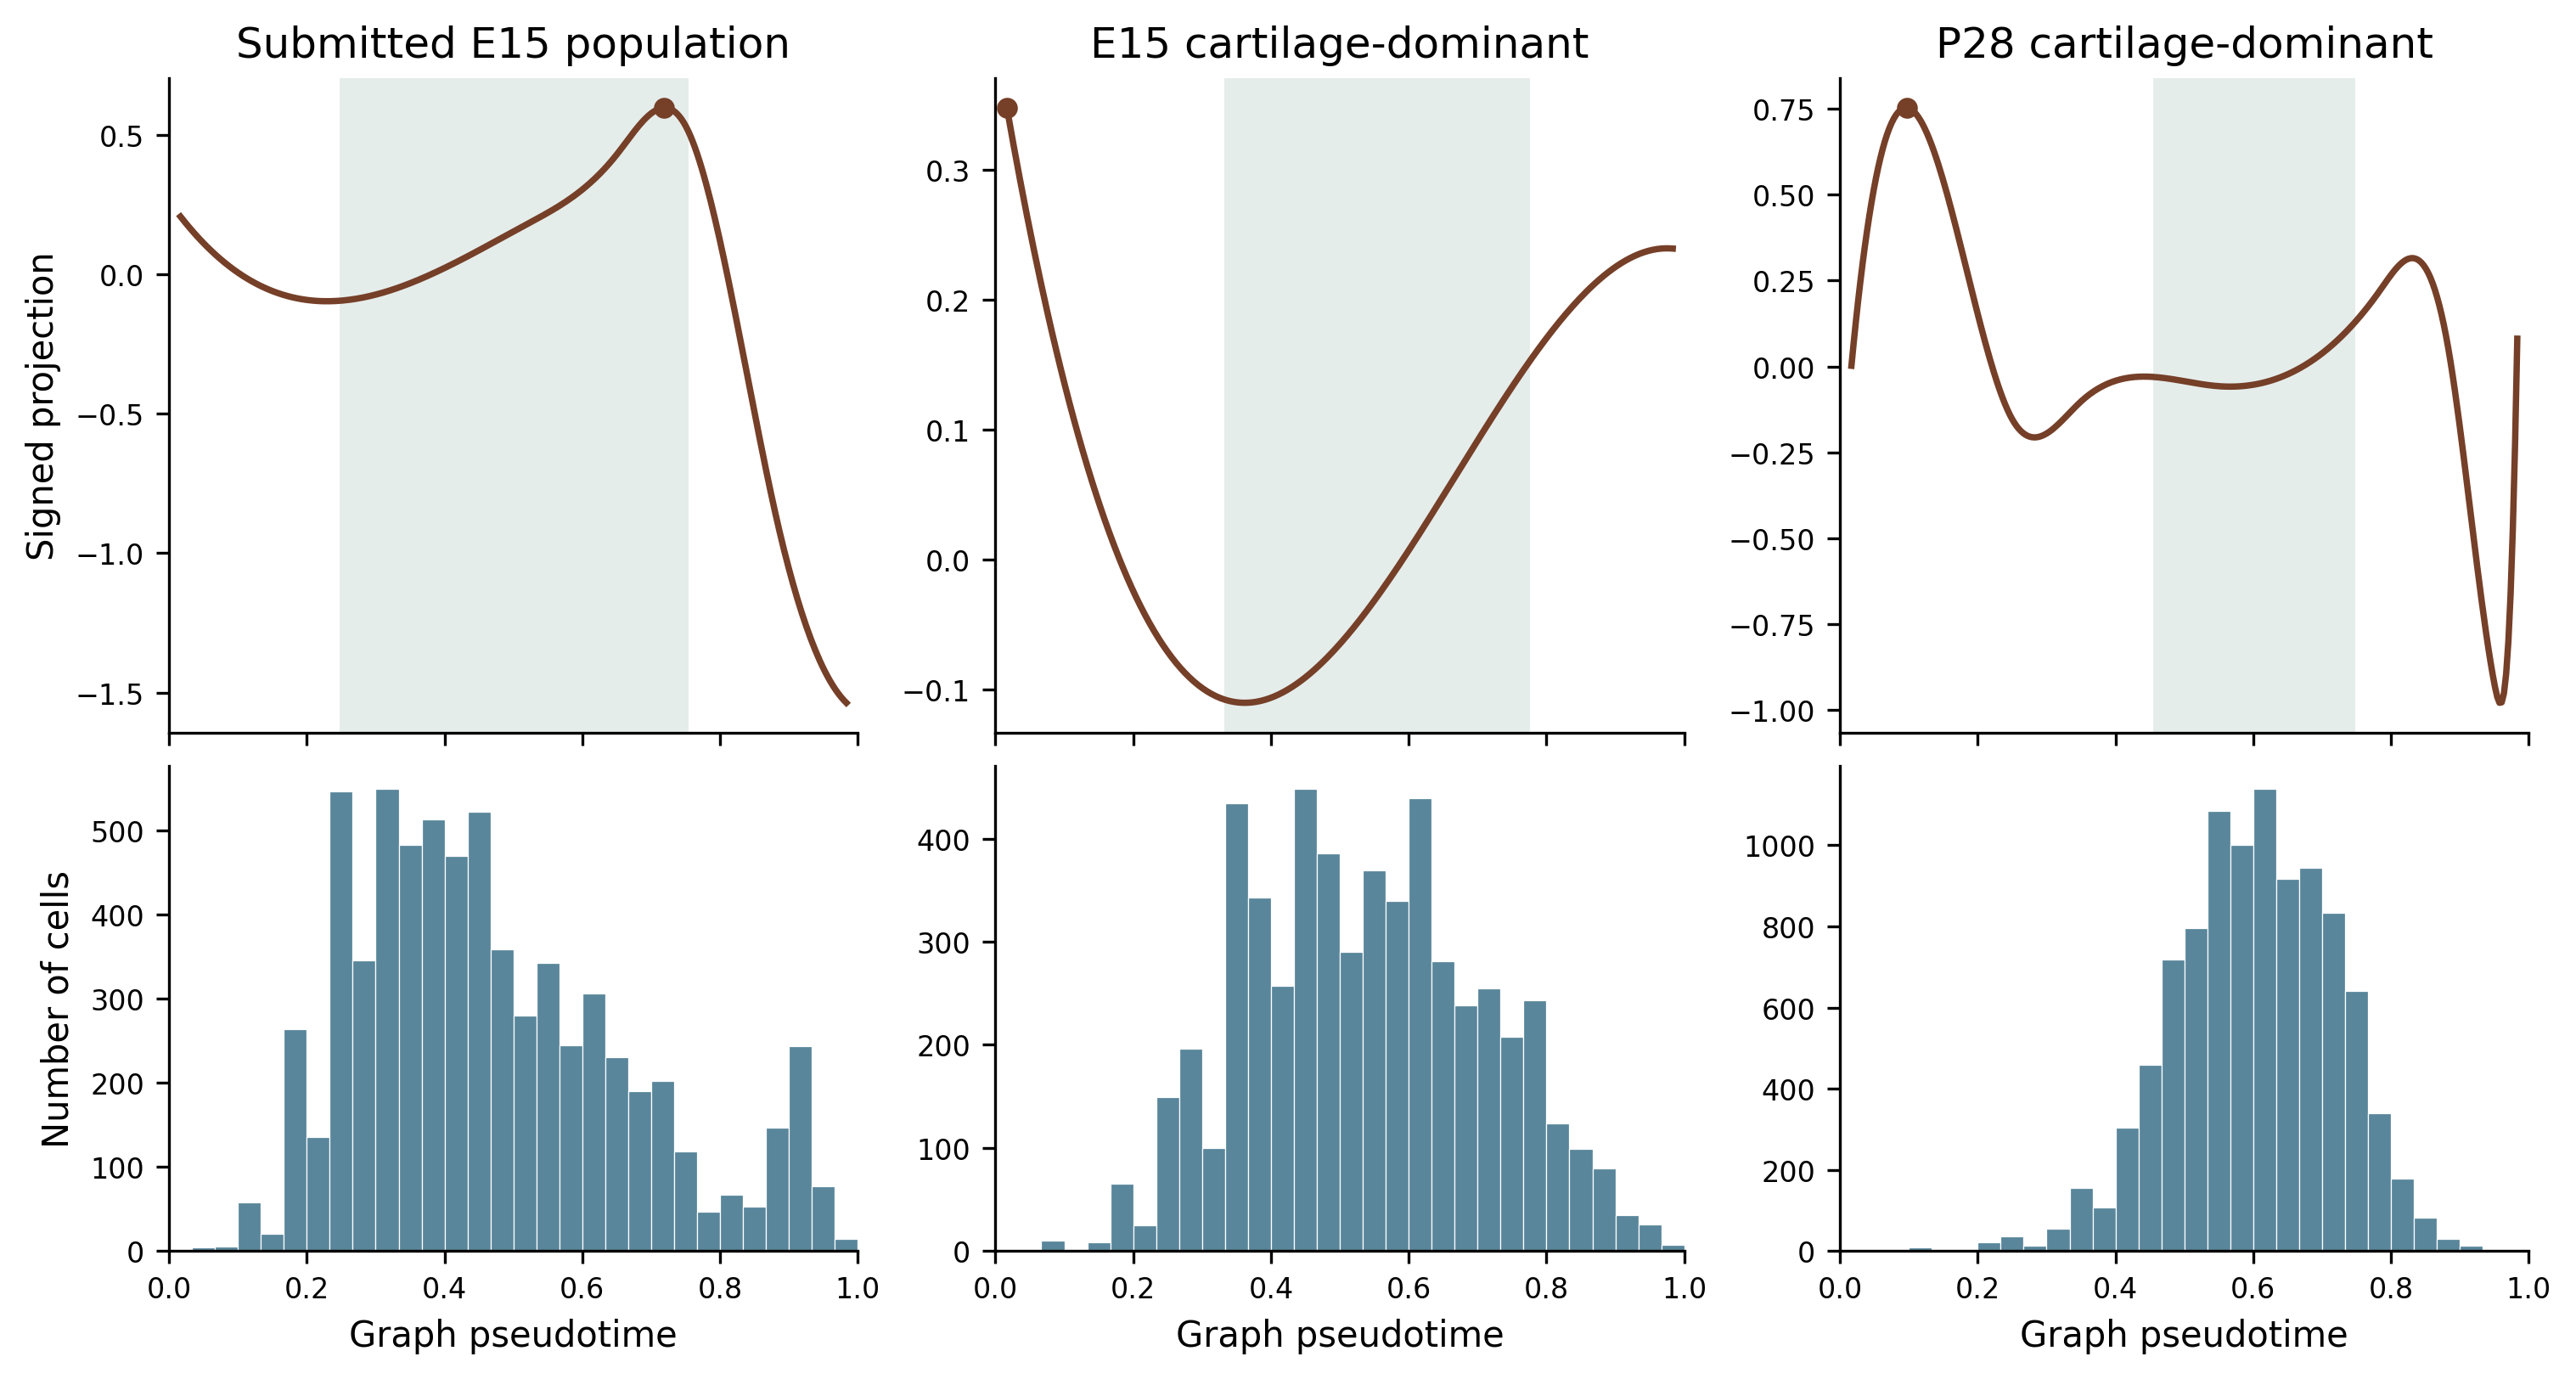

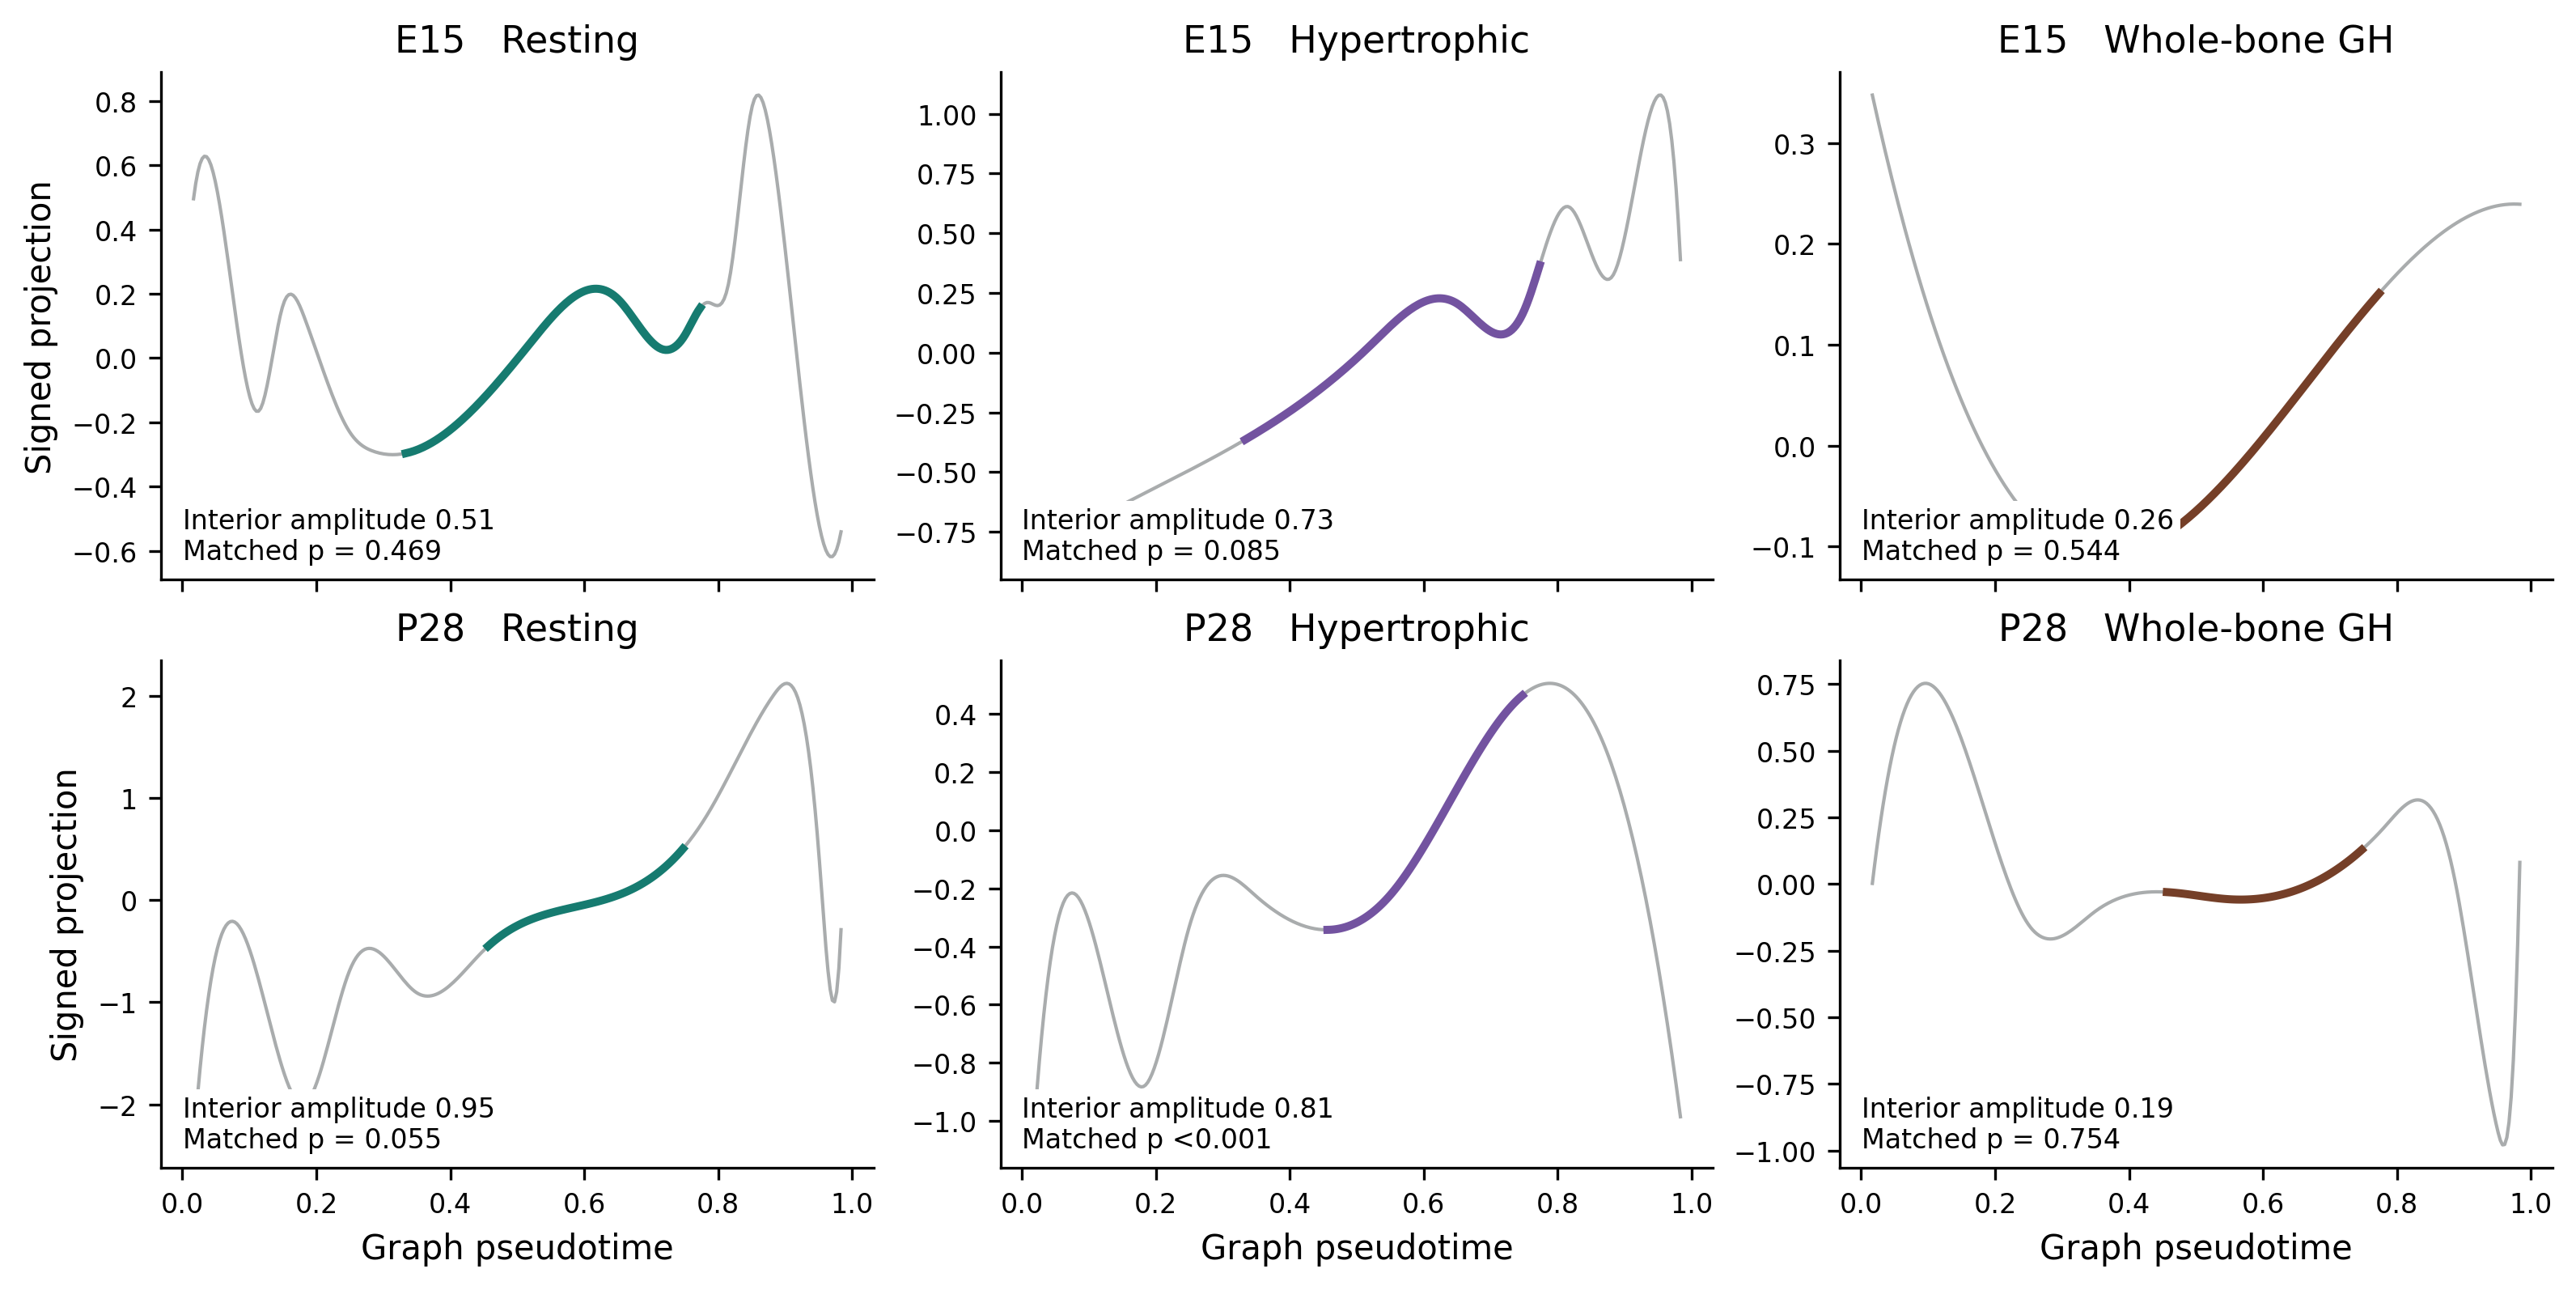

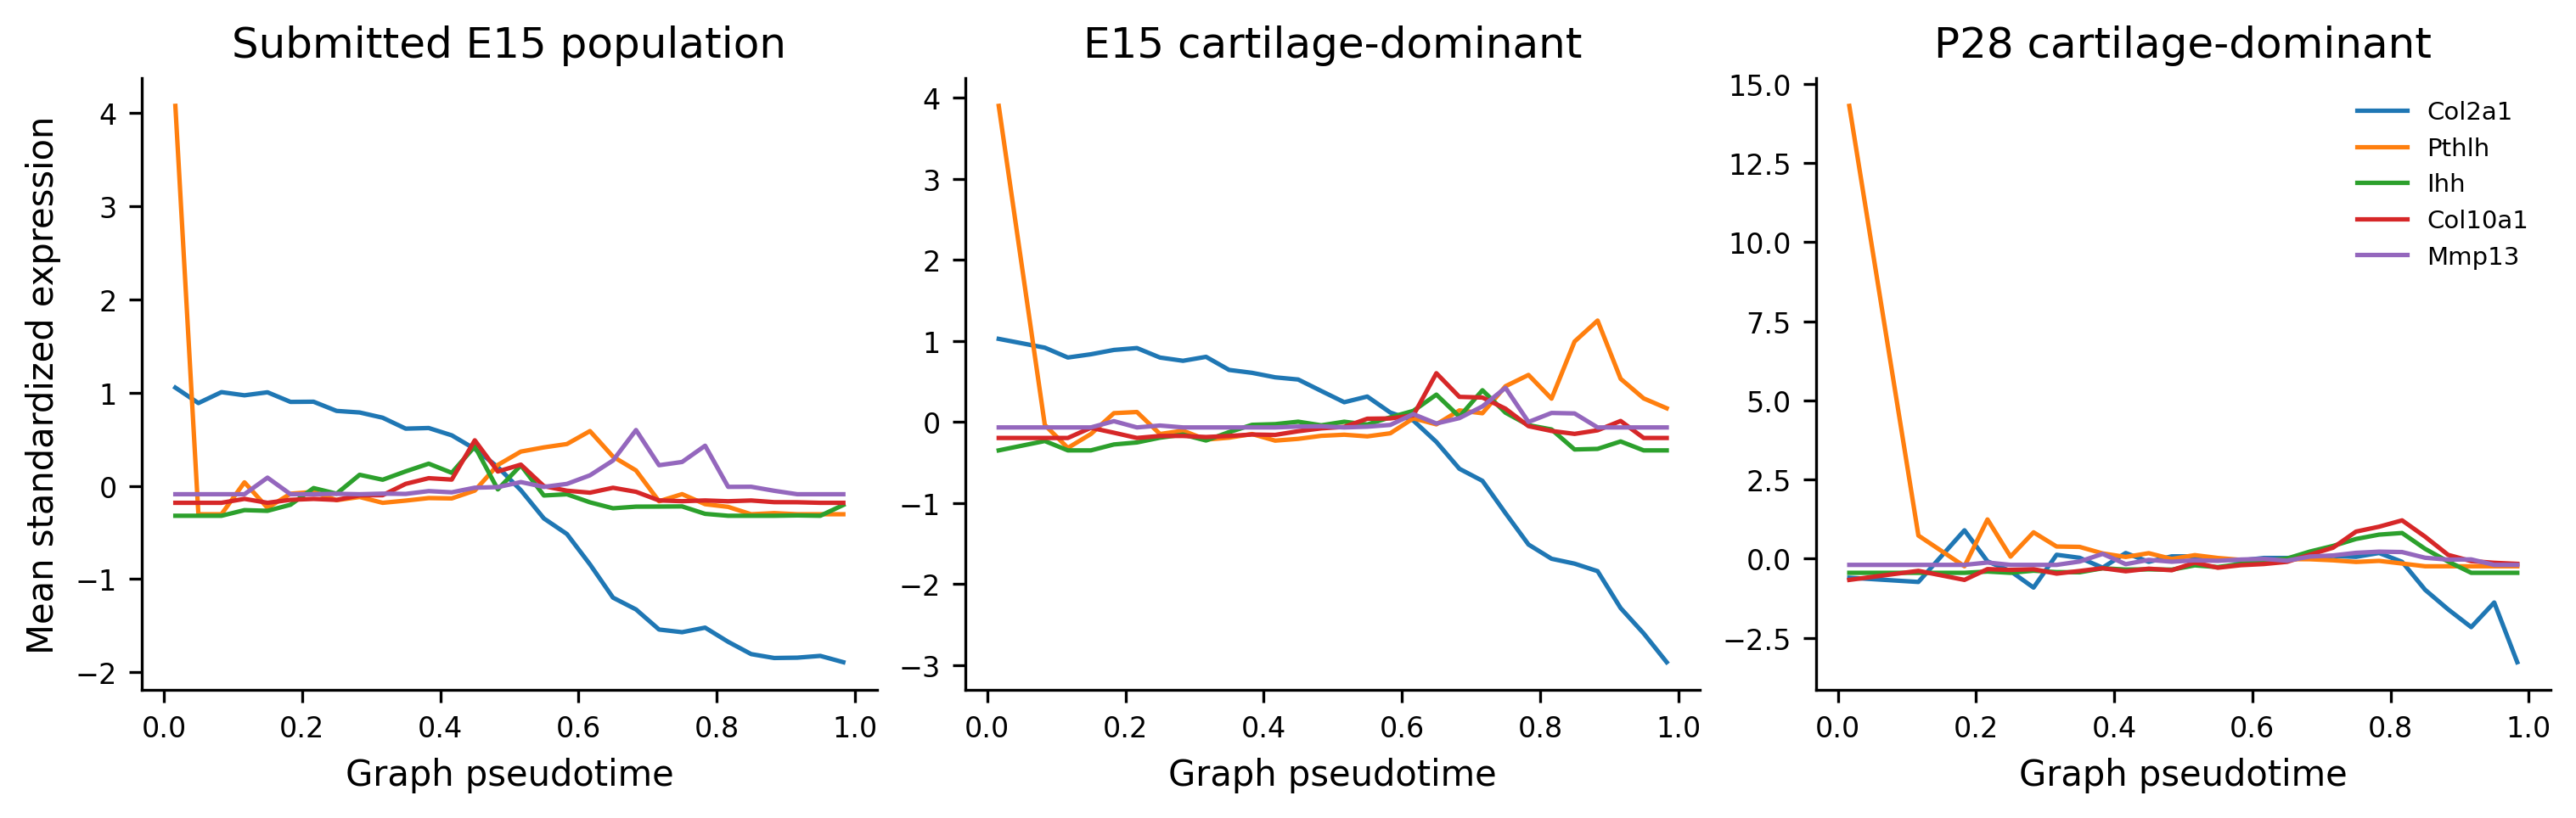

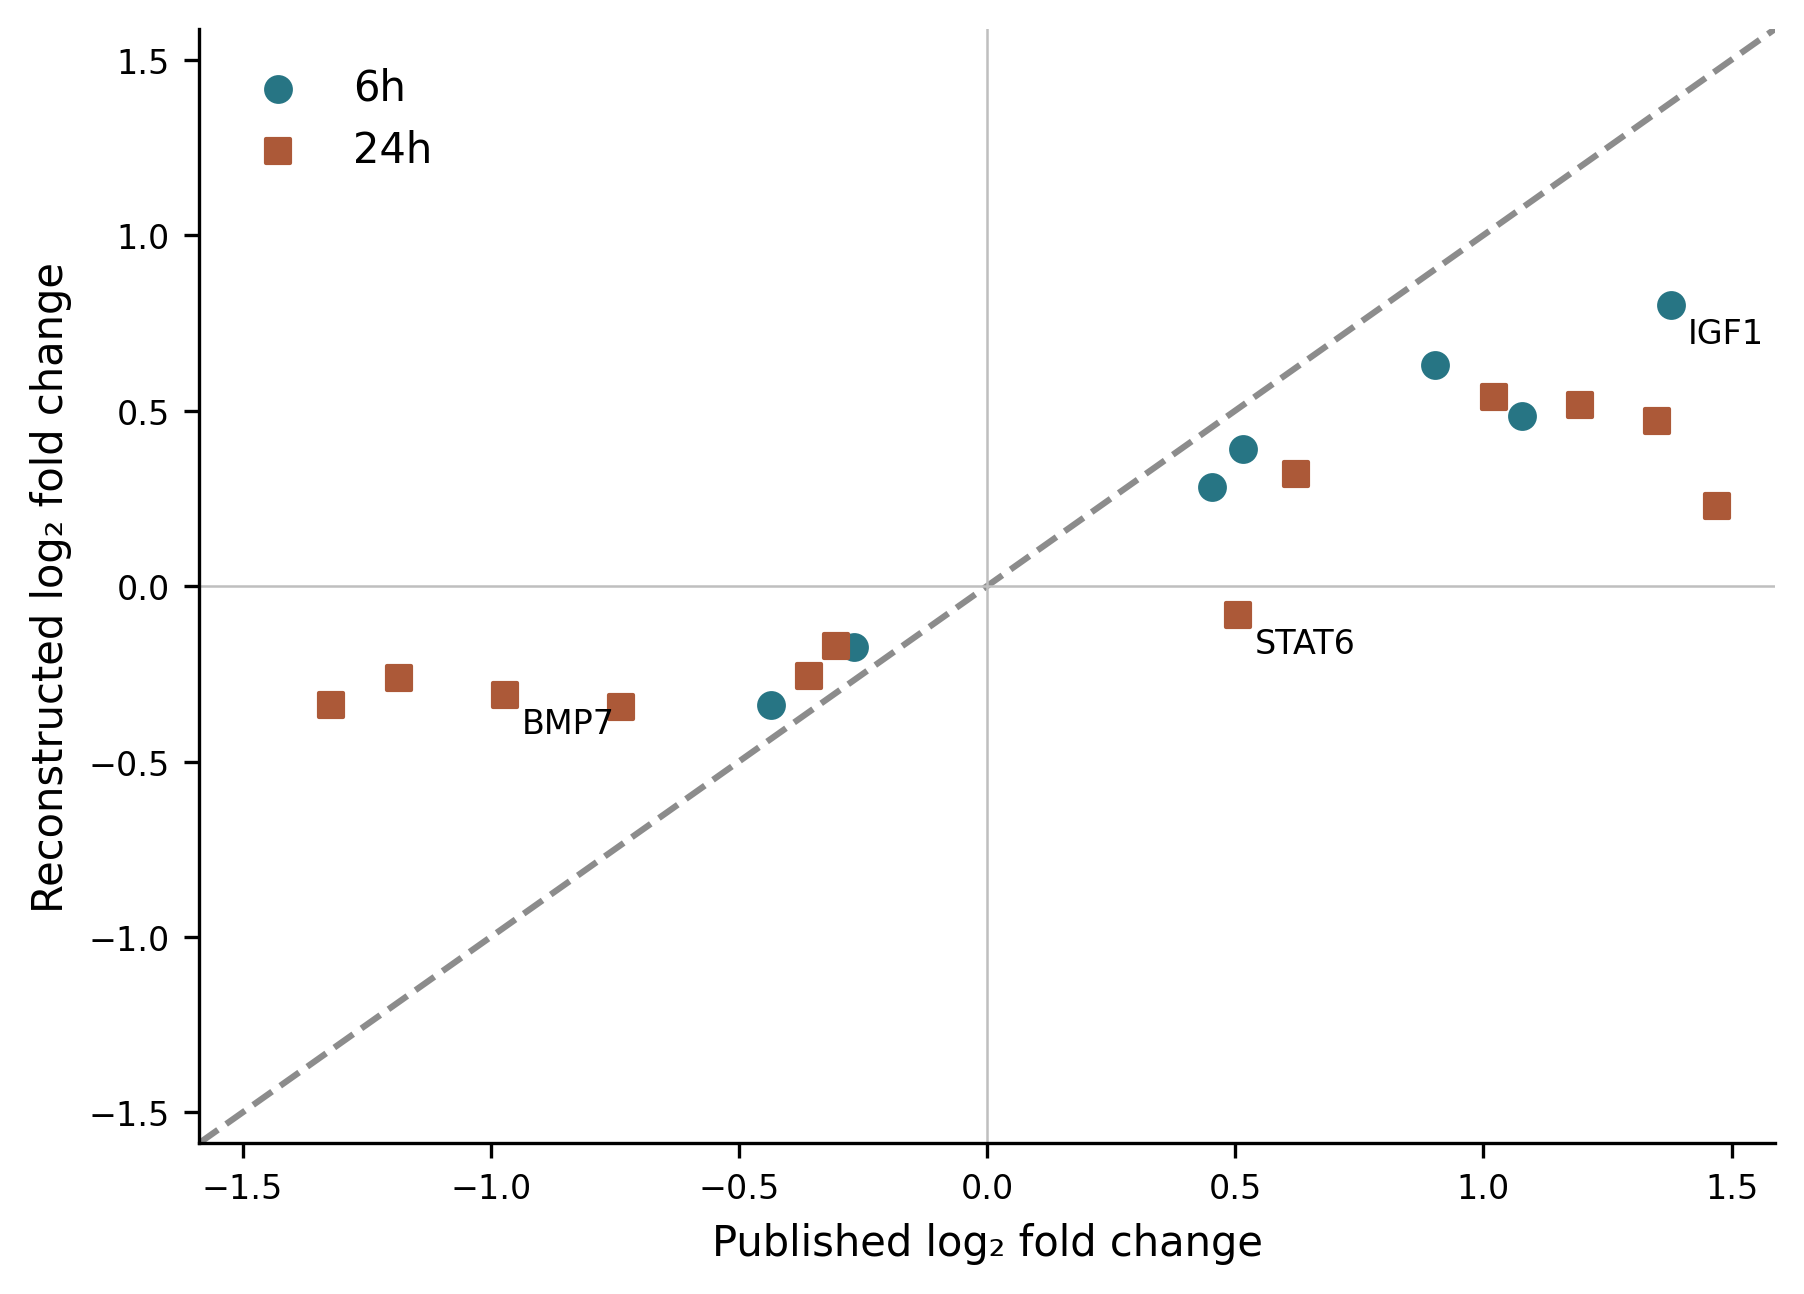

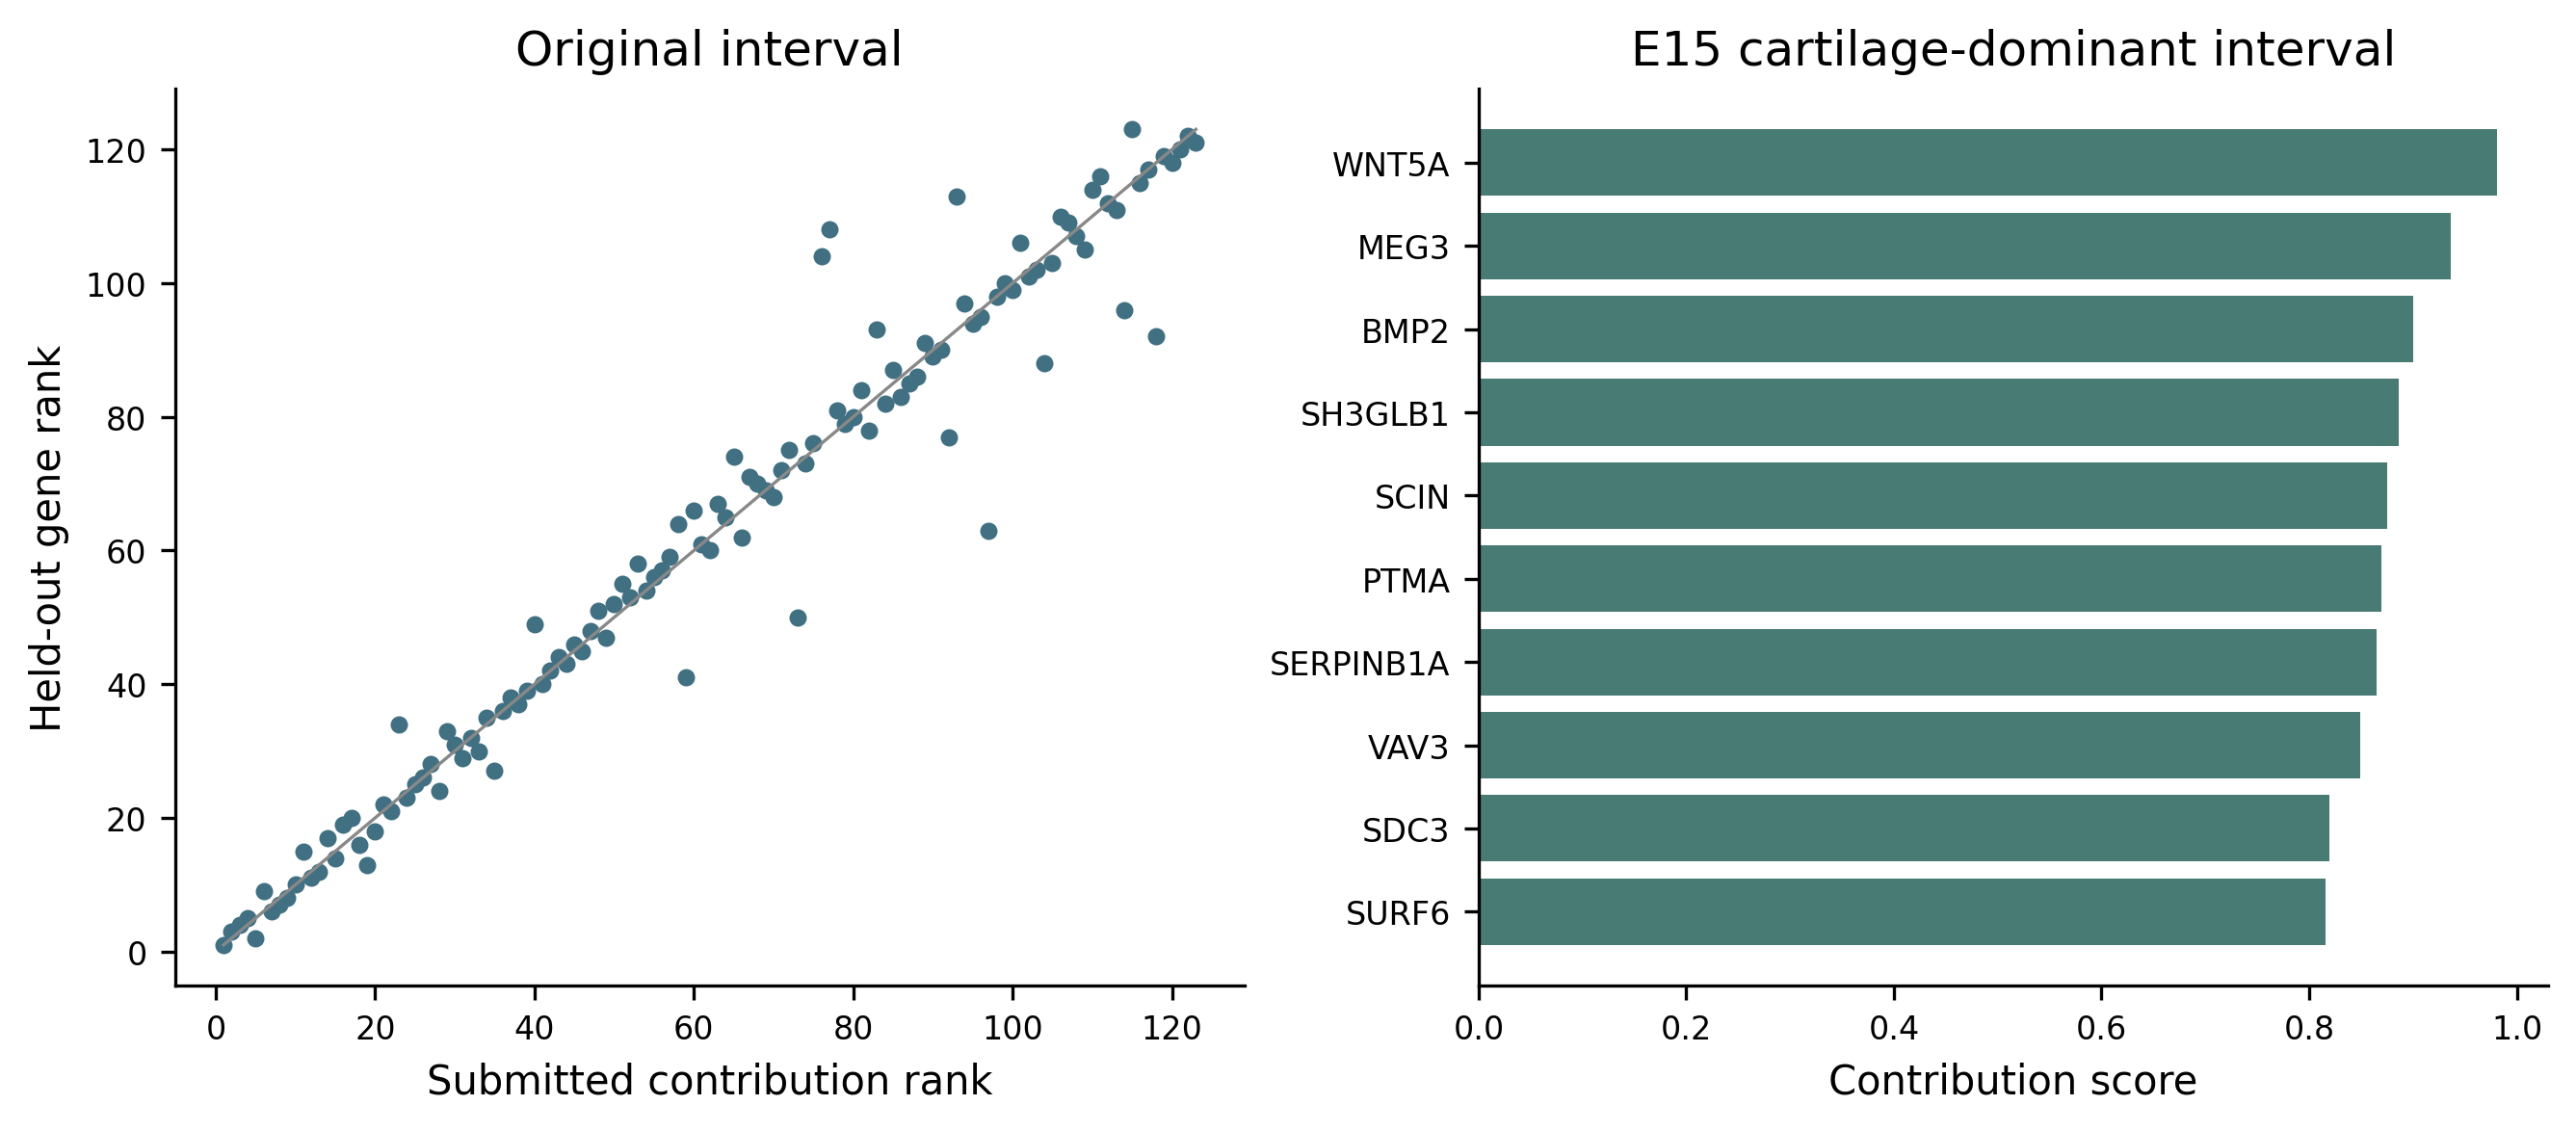

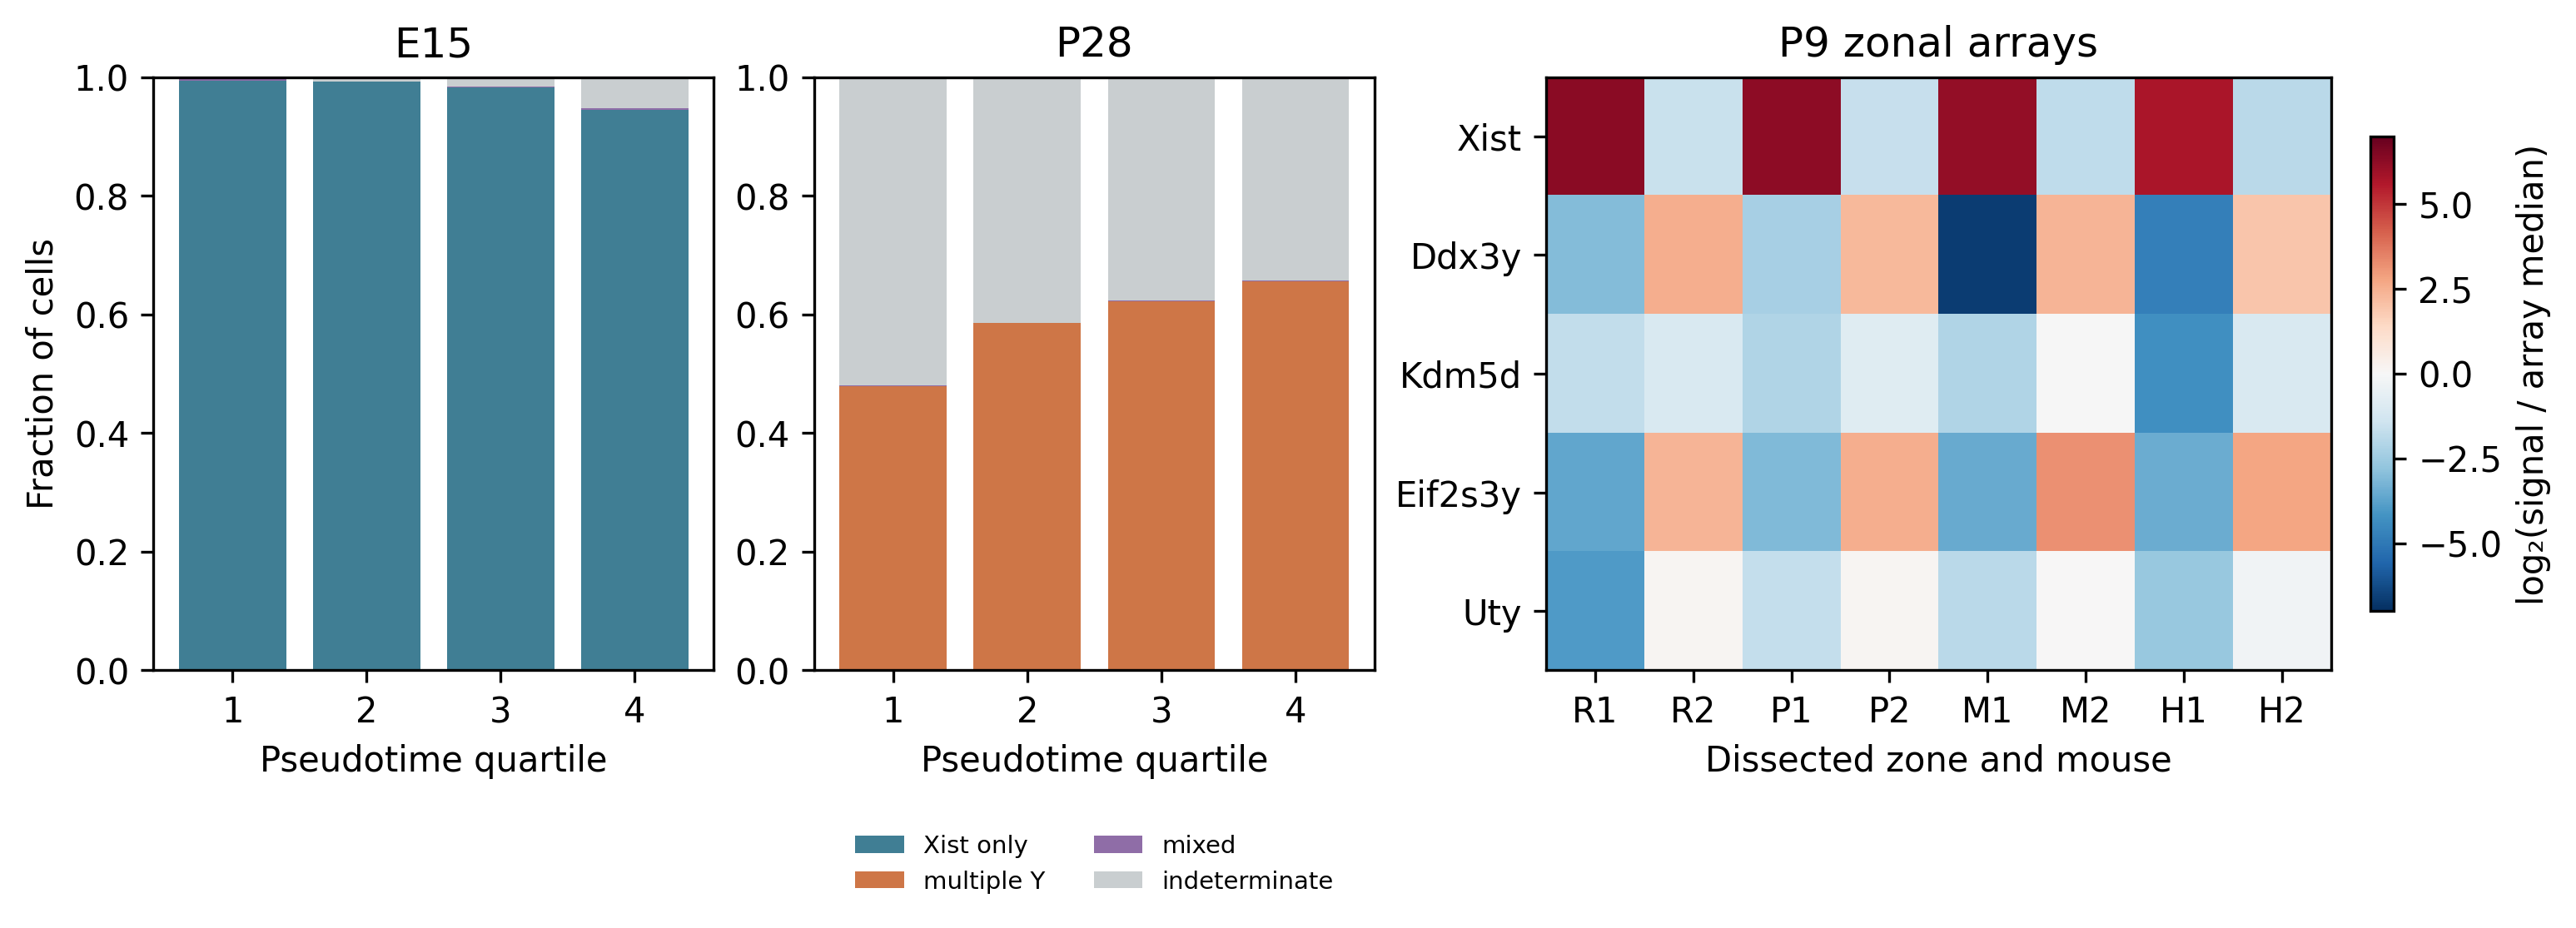

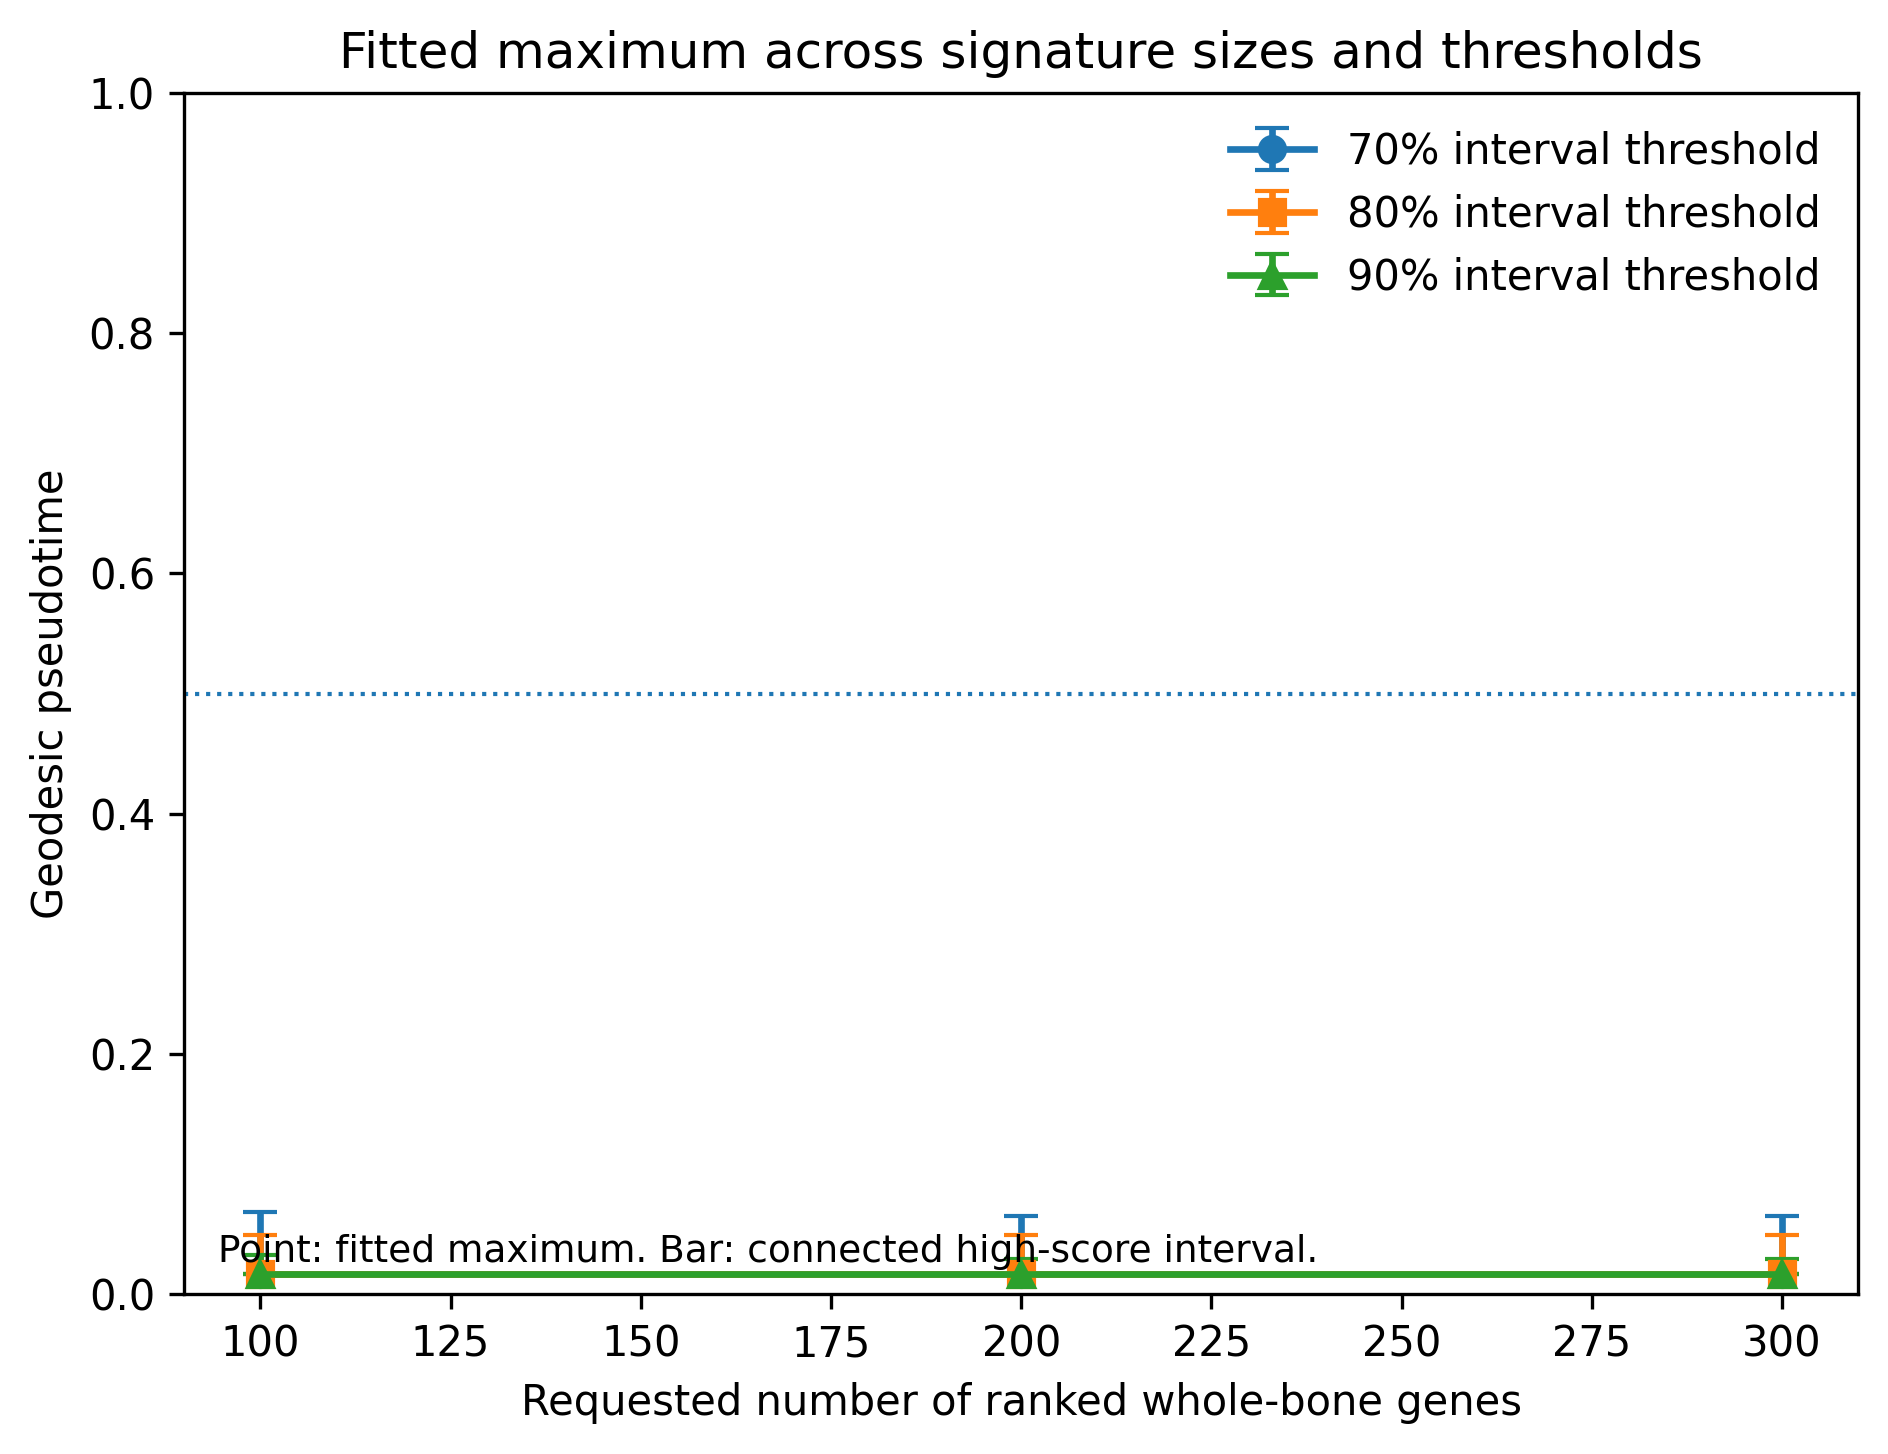

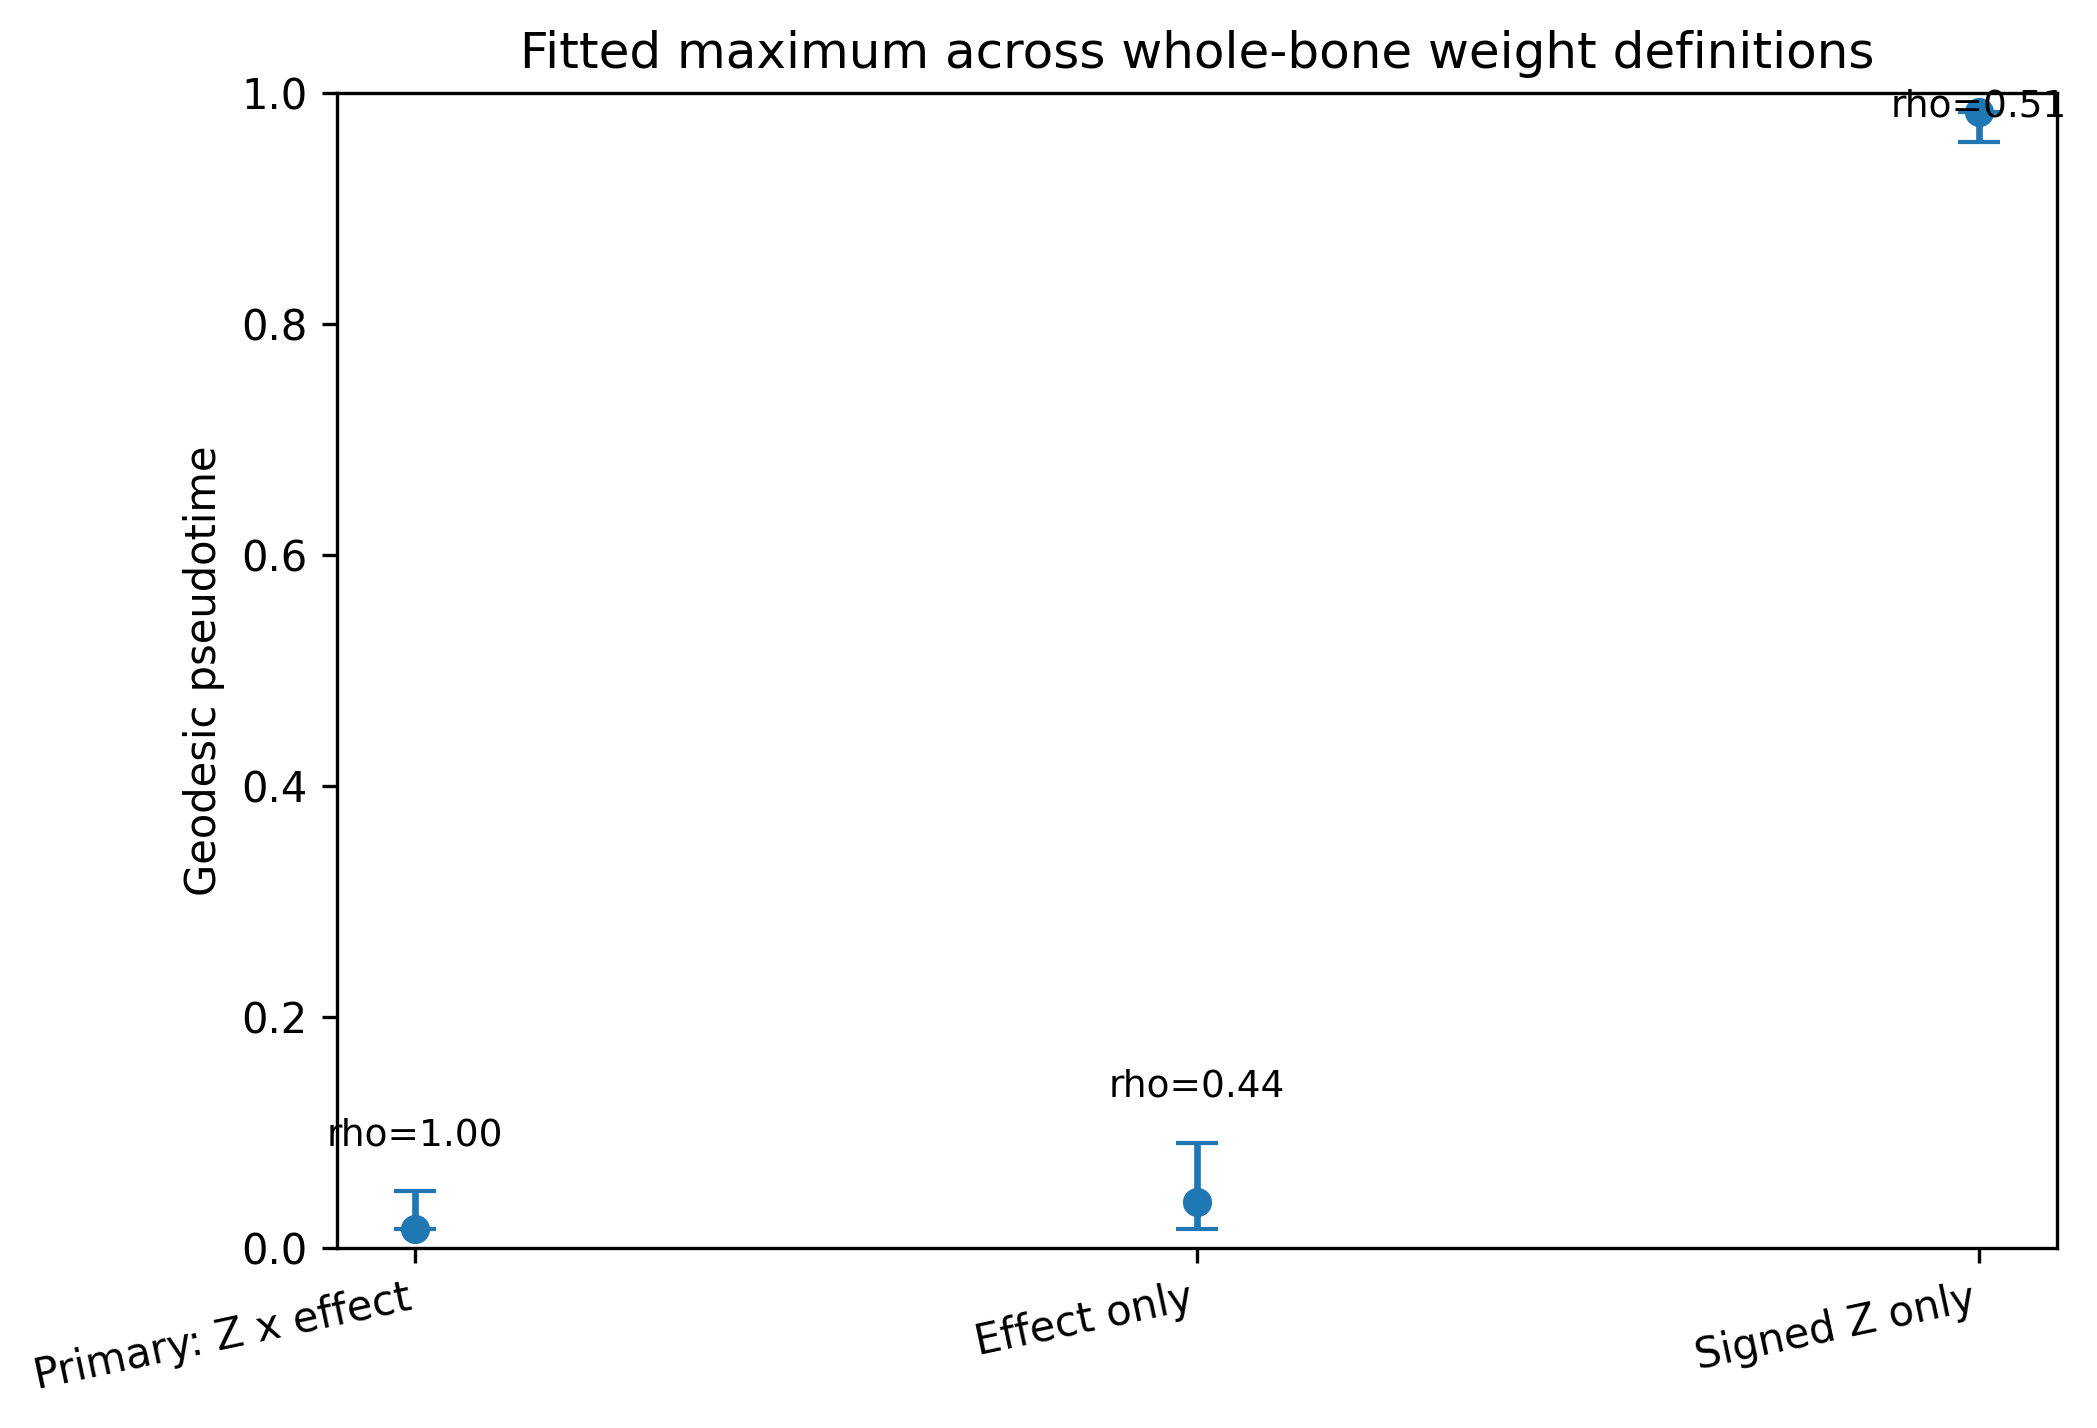

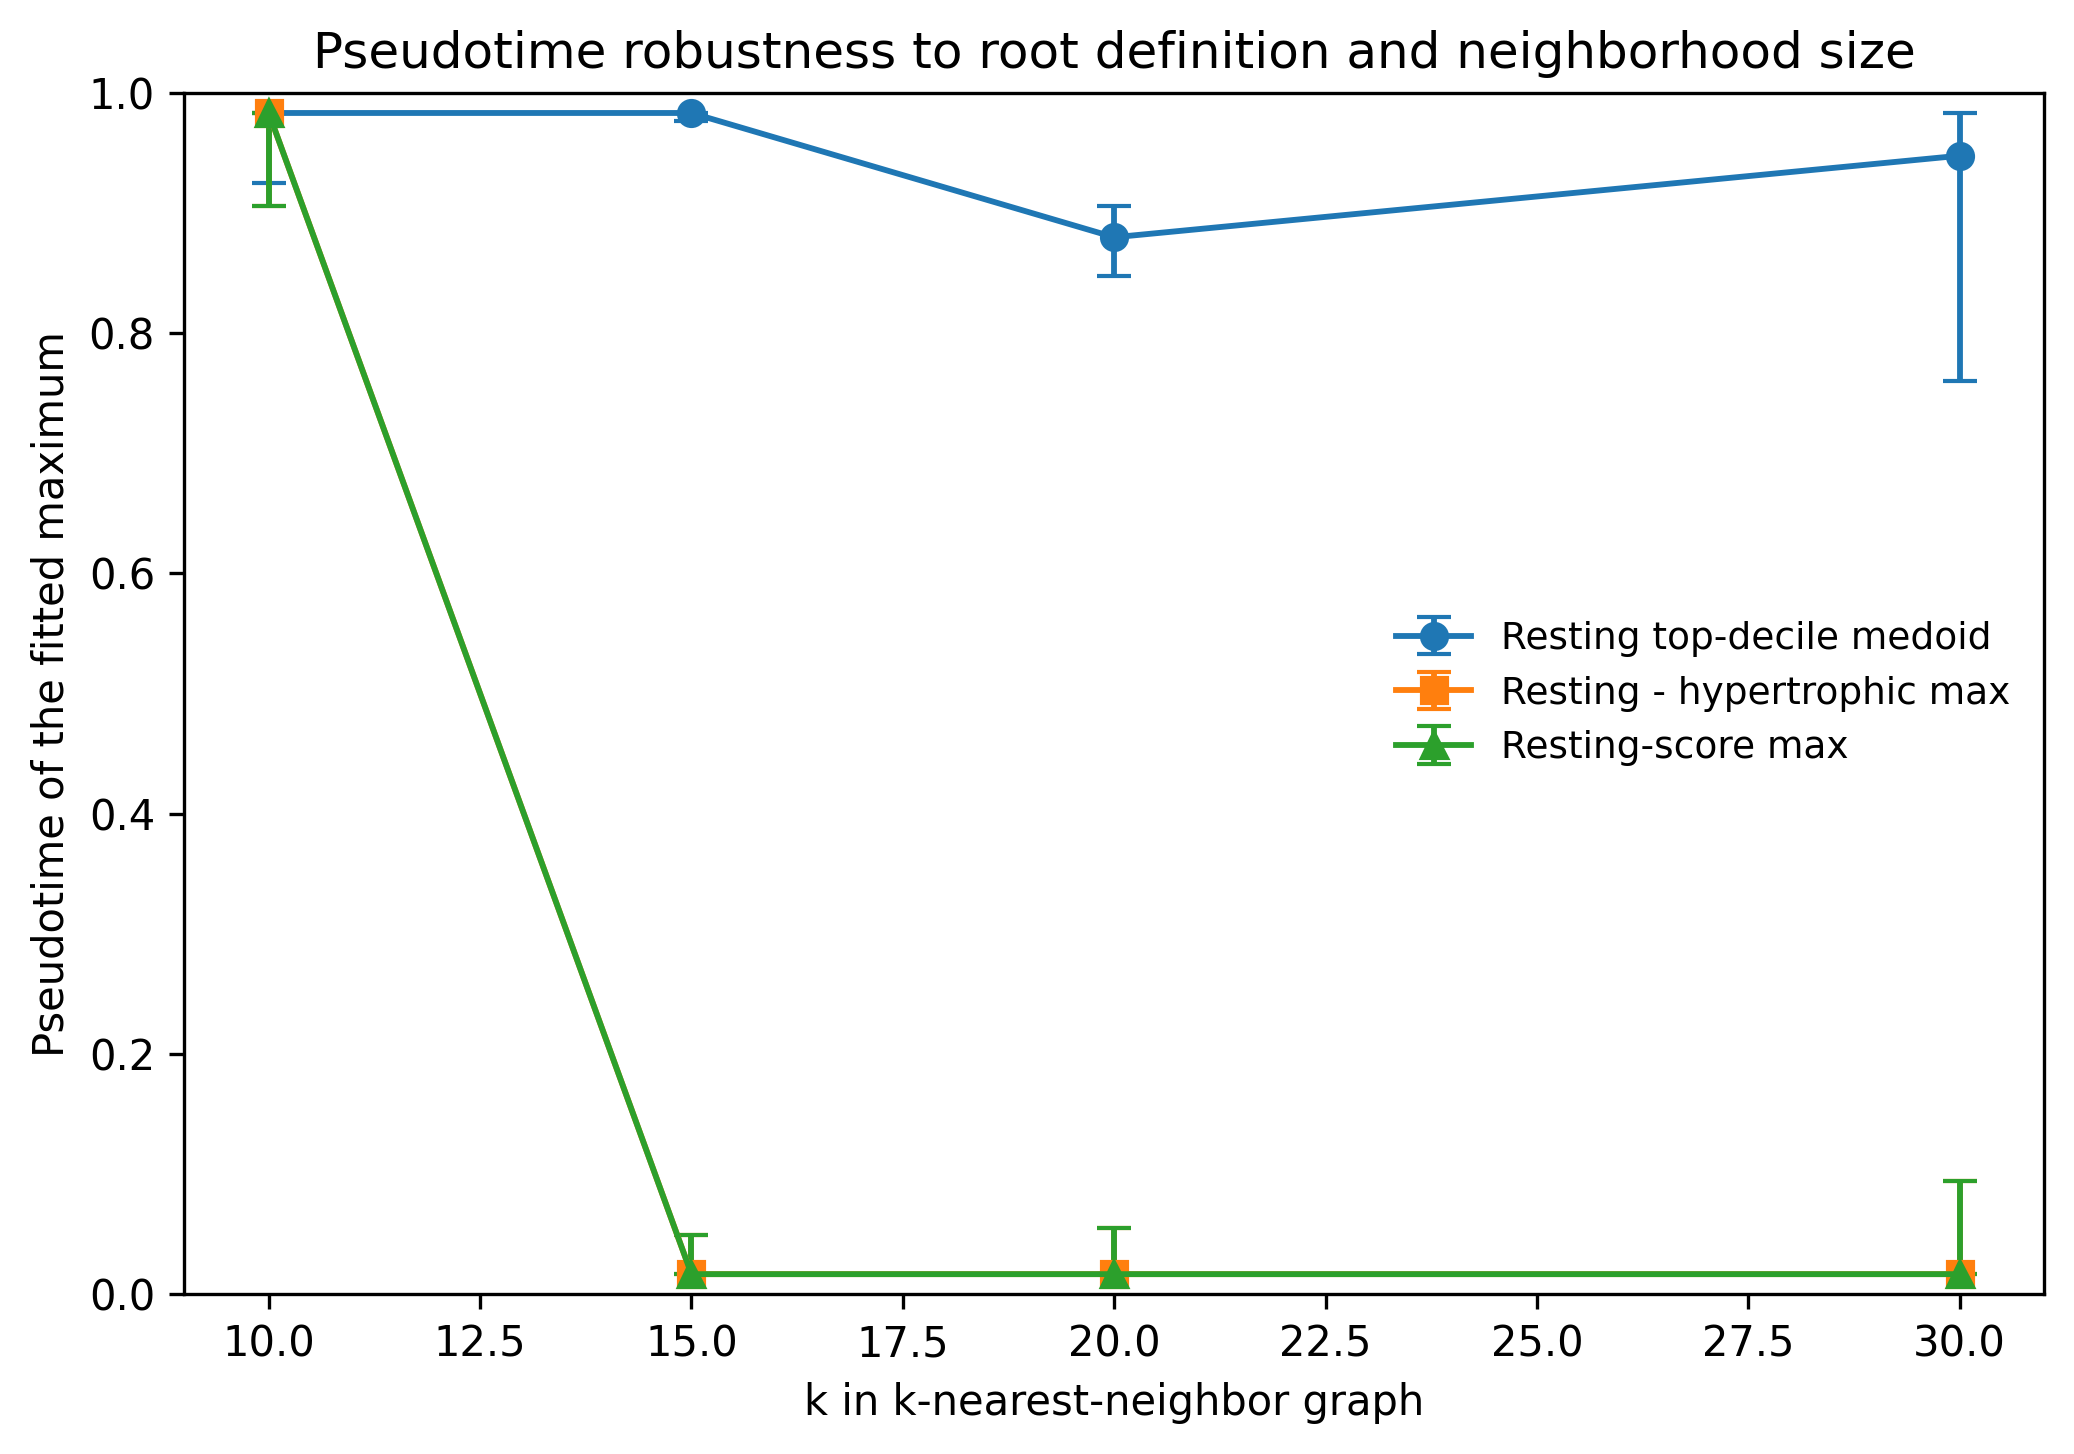

,state,submitted_inside,removed_from_submitted_inside,retained_from_submitted_inside,E15_new_inside,E15_new_outside,E15_median,E15_q25,E15_q75
0,hypertrophic,530,304,226,101,846,0.596473,0.487474,0.704577
1,prehypertrophic,546,276,270,158,1012,0.611603,0.481228,0.715888
2,proliferative,545,183,362,133,1196,0.616630,0.511656,0.727910
3,resting,212,19,193,33,1978,0.401705,0.339974,0.495885


,null,draws,exceedances,p,display
0,weight_permutation,1000,71,0.071928,0.0719
1,matched_random_genes,1000,86,0.086913,0.0869


In [41]:
analysis_figures(out)
fig_response_window_sensitivity(pd.read_csv(out / "retained_size.csv"))
fig_signature_weighting_sensitivity(pd.read_csv(out / "retained_weights.csv"))
fig_pseudotime_root_knn_robustness(pd.read_csv(out / "retained_graph.csv"))
publication_tables(out, h1)
display(pd.read_csv(out / "table1.csv"))
display(pd.read_csv(out / "H1_figure_values.csv"))

### 42 · Audit the complete revision and locate the exports

This final cell checks the primary and supplementary numbers and verifies the 45 figure exports. The audit table shows any departure from manuscript precision. Links below the audit lead to the two main tables, both audits and the figure index when Jupyter serves the output folder. The printed paths also work in a file manager.


In [42]:
verify_revision(out, figdir, root)
display(pd.read_csv(out / "revision_audit.csv"))
print("Complete analysis in", display_path(root))
from IPython.display import Markdown
from urllib.parse import quote

for file in (
    out / "table1.csv",
    out / "table2.csv",
    out / "reproduction_audit.csv",
    out / "revision_audit.csv",
    root / "figure_index.csv",
):
    if file.is_relative_to(Path.cwd()):
        relative = file.relative_to(Path.cwd()).as_posix()
        display(Markdown(f"[{relative}]({quote(relative, safe='/')})"))
    else:
        print(file)

Passed 37 revision checks and verified 45 figure exports.


,quantity,computed,reported,tolerance,passed
0,submitted_inside,1.833000e+03,1.833000e+03,0.00000,True
1,removed_from_submitted_inside,7.820000e+02,7.820000e+02,0.00000,True
2,E15_new_inside,4.250000e+02,4.250000e+02,0.00000,True
3,E15_new_outside,5.032000e+03,5.032000e+03,0.00000,True
4,E15 GH matched_p,5.444555e-01,5.445000e-01,0.00010,True
5,P28 GH matched_p,7.542458e-01,7.542000e-01,0.00010,True
6,E15 GH_alias matched_p,6.333666e-01,6.334000e-01,0.00010,True
7,P28 GH_alias matched_p,9.020979e-01,9.021000e-01,0.00010,True
8,P28 hypertrophic direction_holm,3.996004e-03,4.000000e-03,0.00010,True
9,E15 hypertrophic direction_holm,7.492507e-01,7.493000e-01,0.00010,True


Complete analysis in GHIR_reproduction


[GHIR_reproduction/tables/table1.csv](GHIR_reproduction/tables/table1.csv)

[GHIR_reproduction/tables/table2.csv](GHIR_reproduction/tables/table2.csv)

[GHIR_reproduction/tables/reproduction_audit.csv](GHIR_reproduction/tables/reproduction_audit.csv)

[GHIR_reproduction/tables/revision_audit.csv](GHIR_reproduction/tables/revision_audit.csv)

[GHIR_reproduction/figure_index.csv](GHIR_reproduction/figure_index.csv)

## Data, attribution and code license

The software accompanies *Projecting a whole-bone growth hormone exposure signature onto embryonic and postnatal cartilage: a test with independent zonal controls*, by Ahmet Haşim Yurttakal and Hasan Erbay. The original data are attributed to the investigators named in the following records.

- Juvenile mouse GH/PBS arrays · [GSE3689](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE3689)
- Embryonic mouse single-cell atlas · [GSE271634](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE271634)
- Four-week mouse epiphyseal atlas · [GSE288529](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE288529)
- Newborn mouse zone dissections · [GSE87605](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE87605)
- Day-9 mouse zone dissections · [GSE14007](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE14007)
- Human zone dissections · [GSE9160](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE9160)

Historical mouse symbols use [Mouse Genome Informatics](https://www.informatics.jax.org/downloads/reports/MRK_List2.rpt). The one-to-one mouse–human identifiers are a frozen [Ensembl Compara](https://www.ensembl.org/info/genome/compara/homology_method.html) extract. The MGI lookup credits Mouse Genome Informatics, The Jackson Laboratory, and uses [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). We restricted the report to project markers, split aliases and normalized symbol case. See the [MGI licensing notice](https://www.informatics.jax.org/mgihome/other/copyright.shtml), [GEO notice](https://www.ncbi.nlm.nih.gov/geo/info/disclaimer.html) and [Ensembl data notice](https://www.ensembl.org/about/articles/ensembl-content-disclaimer). The MIT License covers this notebook's software and accompanying documentation.

<details><summary>MIT License</summary>

MIT License

Copyright (c) 2026 GHIR reproduction software contributors

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

</details>
